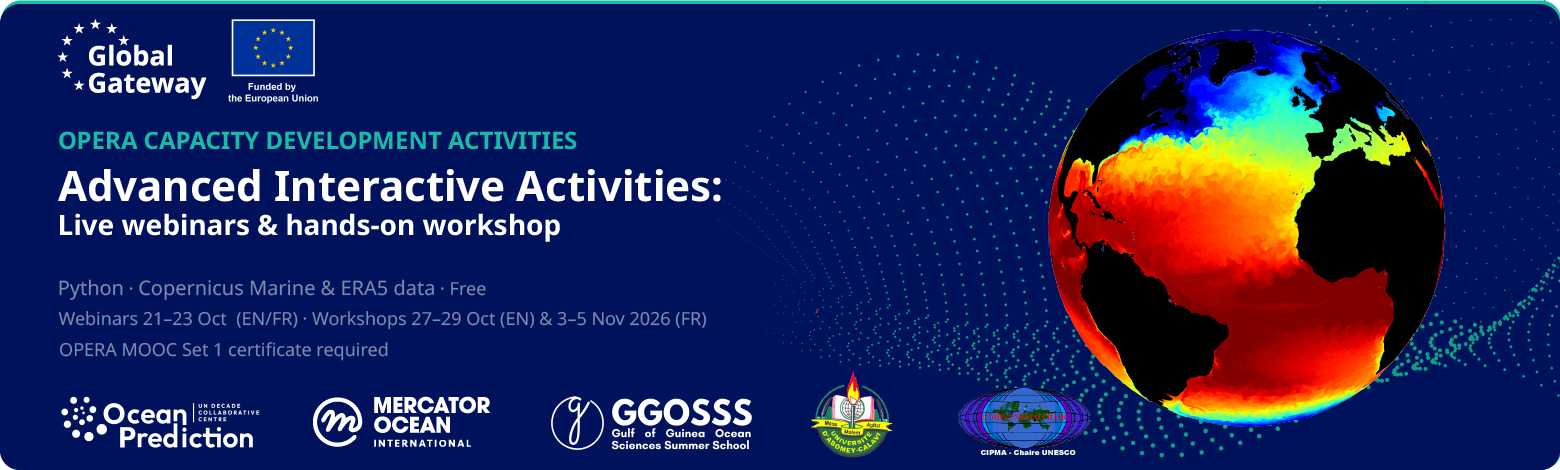

**Content creator:** Babette C. Tchonang

**Content editors:** Badara Sane, Ebenzer Nyadjro, Fernand Assene, Habib Aguedjou & Nathanael Dossa

**Content coordinator:** Arielle Stella Imbol

## About this workshop

This tutorial is part of the [**OPERA Capacity Development**](https://www.unoceanprediction.org/en/ocean-prediction-enhancement-regions-africa-opera) activities, developed and led jointly by [**GGOSSS**](https://www.ggosss.org/) (Gulf of Guinea Ocean Sciences Summer School) and the [**ICMPA – UNESCO Chair**](https://www.icmpa.net/) (International Chair in Mathematical Physics and Applications).

The [OPERA project](https://www.unoceanprediction.org/en/ocean-prediction-enhancement-regions-africa-opera) (*Ocean Prediction Enhancement in Regions of Africa*) is **financed by the [European Union](https://european-union.europa.eu/)** and implemented by [**Mercator Ocean International**](https://www.mercator-ocean.eu/), in the framework of the [**Ocean Prediction Decade Collaborative Centre (OceanPrediction DCC)**](https://www.unoceanprediction.org/).

<div style="background:#0A2372; color:white; padding:22px 28px; border-radius:8px">
<div style="color:#009E8A; font-weight:bold; letter-spacing:1px">OPERA WORKSHOP · DAY 3 · MOOC MODULES 6 · 7</div>
<div style="font-size:28px; font-weight:bold; margin-top:6px">Forecast, Validate, Use — Search and Rescue, Marine Heatwaves</div>
<div style="font-size:17px; margin-top:4px">The 10-day forecast · how much to trust it · where a drifting person goes · is the sea in a heatwave?</div>
</div>

### Where Day 3 sits in the forecasting chain

```
  OBSERVE  ──►  ASSIMILATE  ──►  FORECAST  ──►  VALIDATE / USE
   Day 1          Day 2            Day 3            Day 3
```

Day 1 observed the surface; Day 2 looked below it with sea level and a model. Today each subgroup works **all day on its own region**,
with the **operational forecast** that Copernicus Marine issues every day: what will the ocean do in the next 10 days, how good is
that forecast — and then two real applications: **search and rescue** (where does a person in the water drift?) and **marine heatwaves**
(is the sea dangerously warm, now or next week?).

> **Today's product** — by 16:40 your subgroup writes a **one-page bulletin** for your region: the search area for a drifting
> object, the heatwave watch, and the sea state for the next days.

## Day 3 schedule (09:00–18:00)

| Time | Format | Activity | Region | MOOC | Notebook |
|------|--------|----------|--------|------|----------|
| 09:00–09:30 | Opening plenary | How an ocean forecast is made and read; today's two applications | — | 6, 7 | — |
| 09:30–10:45 | Subgroups | **Set up your region** and **load the forecast once** (runs over the break) | **Your area** | 6 | Sections 0–1 |
| 10:45–11:05 | Break | | | | |
| 11:05–12:30 | Subgroups | **The forecast and how good it is** — maps, your user's point, model vs satellites and in situ | **Your area** | 6 | Sections 2–3 |
| 12:30–13:30 | Lunch | | | | |
| 13:30–15:00 | Subgroups | **Application 1 — Search and rescue**: hourly total currents, a drift model, the search area for 72 h | **Your area** | 7 | Section 4 |
| 15:00–15:20 | Break | | | | |
| 15:20–16:20 | Subgroups | **Application 2 — Marine heatwaves**: 30-year thresholds, is there a heatwave now or next week? | **Your area** | 7 | Section 5 |
| 16:20–16:40 | Subgroups | **Your bulletin** — alerts, search area, heatwave watch | **Your area** | 7 | Section 6 |
| 16:40–17:40 | Reconvergence plenary | **Three bulletins** — each subgroup presents | All three areas | 6, 7 | Section 7 |
| 17:40–18:00 | Closing plenary | Checklist, workshop reflection, what next | | | Sections 8–9 |
| *after the workshop* | On your own | **Verify your forecast** ten days later; take the data home | | 6 | Section 10 |

> **Today every subgroup works its own area all day.** Set your area **once** in Step 0.5 — everything below follows.

### Day 3 learning objectives

1. Explain how an operational ocean forecast is produced, and the difference between an **analysis** and a **forecast** (Module 6).
2. Open the Copernicus Marine **10-day forecast** and turn hourly, 3-hourly and daily fields into the information a user needs (Module 6).
3. **Validate** the model against independent observations — satellite SST and **in situ** measurements — with bias and RMSE (Module 6).
4. **Search and rescue:** compute where a drifting object goes with the **hourly total surface currents** (ocean + tides + waves) and
   the wind, and turn it into a **search area** for a rescue centre (Module 7).
5. **Marine heatwaves:** build a daily **threshold** from 30 years of reanalysis and detect heatwaves in the analyses and the forecast (Module 7).
6. Write a **bulletin** for real users, and say how confident you are (Module 7).

### How this notebook works

| | Everyone — instructors and participants |
|---|---|
| **All sections** | Run every cell, in order (`Shift + Enter`). **Nothing is downloaded.** |
| 💻 | Run the code cell |
| ✍️ | Your turn |
| ✋ | Checkpoint — tell your Subgroup Instructor if it did not work |
| 🔎 | Reading a figure — what it shows and why |

## Section 0 — Set Up Your Region

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Setup block · 09:30–10:00</span>

Same workspace and packages as Days 1–2, with one addition: **argopy**, to read Argo float profiles in Section 3.

In [1]:
# ============================================================
# STEP 0.1 — CREATE YOUR WORKSPACE  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# One folder per workshop day, each with an output/ subfolder.
# Same structure as Day 1: only DAY changes.
# ============================================================

from pathlib import Path
import os

DAY          = 3
WORKSHOP_DIR = Path.home() / 'OPERA_Workshop'
OUTPUT_DIR   = WORKSHOP_DIR / f'Day{DAY}' / 'output'
DATA_DIR     = WORKSHOP_DIR / 'data'          # used ONLY if you choose to download (Section 10)

for d in (1, 2, 3):
    (WORKSHOP_DIR / f'Day{d}' / 'output').mkdir(parents=True, exist_ok=True)

print('==> Workspace ready')
print(f'   Workshop folder : ~/{WORKSHOP_DIR.relative_to(Path.home())}')
print(f'   Today\'s outputs : ~/{OUTPUT_DIR.relative_to(Path.home())}')
print()
for d in (1, 2, 3):
    p = WORKSHOP_DIR / f'Day{d}' / 'output'
    n = len(list(p.glob('*')))
    mark = '   <- today' if d == DAY else ''
    print(f'   Day{d}/output   {n:>3} file(s){mark}')

==> Workspace ready
   Workshop folder : ~/OPERA_Workshop
   Today's outputs : ~/OPERA_Workshop/Day3/output

   Day1/output    16 file(s)
   Day2/output    17 file(s)
   Day3/output    40 file(s)   <- today


In [2]:
# ============================================================
# STEP 0.2 — CHECK & INSTALL PACKAGES  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Installs what is missing into your HOME folder (kept when the
# hub server restarts), then VERIFIES with a fresh Python what
# the kernel will load after the restart.
# ============================================================

import importlib, importlib.metadata, subprocess, sys

REQUIRED = [  # (import name, pip requirement)
    ('copernicusmarine', 'copernicusmarine'),
    ('xarray',           'xarray'),
    ('dask',             'dask'),
    ('zarr',             'zarr>=3'),
    ('aiohttp',          'aiohttp'),
    ('netCDF4',          'netCDF4'),
    ('h5netcdf',         'h5netcdf'),
    ('numpy',            'numpy'),
    ('pandas',           'pandas'),
    ('scipy',            'scipy'),
    ('matplotlib',       'matplotlib'),
    ('cartopy',          'cartopy'),
    ('cmocean',          'cmocean'),
    ('argopy',           'argopy'),          # Argo floats (Section 3)
]

def fresh_versions(names):
    """Ask a NEW Python process (= the kernel after a restart) which versions it loads."""
    code = ('import importlib, json\nout = {}\n'
            f'for n in {names!r}:\n'
            '    try:\n'
            '        m = importlib.import_module(n); out[n] = [getattr(m, "__version__", "?"), getattr(m, "__file__", "?")]\n'
            '    except Exception as e:\n'
            '        out[n] = ["MISSING", type(e).__name__]\n'
            'print(json.dumps(out))')
    r = subprocess.run([sys.executable, '-c', code], capture_output=True, text=True)
    import json
    return json.loads(r.stdout.strip().splitlines()[-1])

print(f' Python: {sys.executable}\n')
print(' Checking packages...\n')
missing = []
for import_name, requirement in REQUIRED:
    try:
        importlib.import_module(import_name)
        version = importlib.metadata.version(requirement.split('>')[0].split('=')[0])
        if import_name == 'zarr' and int(version.split('.')[0]) < 3:
            print(f'  !!   zarr {version:<12} version 3 or newer is needed to stream the data — will be updated')
            missing.append(requirement)
        else:
            print(f'  ==>  {import_name:<17} {version}')
    except ImportError:
        print(f'  ..   {import_name:<17} not installed yet — will be installed')
        missing.append(requirement)

if not missing:
    print('\n All packages ready — proceed to Step 0.3')
else:
    print(f'\n Installing: {", ".join(missing)} (1–3 minutes)...')
    # --user installs into your HOME folder, which survives a server restart
    # (the system environment is reset each time the hub server starts).
    result = subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', '--upgrade', '--user', *missing],
                            capture_output=True, text=True)
    if result.returncode != 0:      # fallback: environments that refuse --user
        result = subprocess.run([sys.executable, '-m', 'pip', 'install', '--quiet', '--upgrade', *missing],
                                capture_output=True, text=True)
    if result.returncode != 0:
        print(' ❌  Installation failed — show this message to your Subgroup Instructor:\n')
        print(result.stderr[-1500:])
    else:
        if 'kerchunk' in result.stderr:
            print('      (pip mentions "kerchunk requires zarr<3": harmless — kerchunk is not used in this workshop.)')
        # verify what the kernel WILL load after a restart
        check = fresh_versions([n for n, _ in REQUIRED])
        zv, zfile = check['zarr']
        problems = [n for n, (v, _) in check.items() if v == 'MISSING']
        if zv != 'MISSING' and int(str(zv).split('.')[0]) < 3:
            problems.append(f'zarr is still {zv} ({zfile})')
        if problems:
            print(' ❌  Installed, but a fresh Python still sees a problem:')
            for p in problems:
                print('       -', p)
            print('     Show this to your Subgroup Instructor.')
        else:
            print(f' ==>  Installation verified (zarr {zv}  ->  {zfile})')
            print('\n==>  RESTART REQUIRED: Kernel -> Restart Kernel, then re-run Steps 0.1 and 0.2')

 Python: /srv/conda/envs/notebook/bin/python

 Checking packages...

  ==>  copernicusmarine  2.5.0
  ==>  xarray            2026.7.0
  ==>  dask              2026.8.0
  ==>  zarr              3.4.0
  ==>  aiohttp           3.14.3
  ==>  netCDF4           1.7.4
  ==>  h5netcdf          1.8.1
  ==>  numpy             2.5.2
  ==>  pandas            2.3.3
  ==>  scipy             1.18.0
  ==>  matplotlib        3.11.1
  ==>  cartopy           0.25.0
  ==>  cmocean           4.0.3
  ==>  argopy            1.5.0

 All packages ready — proceed to Step 0.3


In [3]:
# ============================================================
# STEP 0.3 — IMPORT ALL LIBRARIES  (Everyone runs this)
# ============================================================

import time, shutil, warnings, logging, textwrap
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean
import dask
import copernicusmarine
from dask.diagnostics import ProgressBar
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
logging.getLogger('copernicusmarine').setLevel(logging.WARNING)   # hide the Toolbox INFO messages
PC = ccrs.PlateCarree()

plt.rcParams.update({'figure.dpi': 100, 'axes.titleweight': 'bold',
                     'axes.titlesize': 12, 'font.size': 10,
                     'axes.titley': 1.02})   # fixed title position: avoids a matplotlib 3.11 + cartopy bug
                                             # that makes maps with gridline labels disappear

# Guard: the kernel must have been restarted after Step 0.2 installed zarr 3
import zarr
if int(zarr.__version__.split('.')[0]) < 3:
    raise RuntimeError(f'zarr {zarr.__version__} is still loaded in this session. '
                       'Kernel -> Restart Kernel, then re-run the notebook from the top (Steps 0.1, 0.2, 0.3...).')

print('==> Libraries imported:')
print(f'   xarray           {xr.__version__}')
print(f'   numpy            {np.__version__}')
print(f'   zarr             {zarr.__version__}')
print(f'   copernicusmarine {copernicusmarine.__version__}')

==> Libraries imported:
   xarray           2026.7.0
   numpy            2.5.2
   zarr             3.4.0
   copernicusmarine 2.5.0


In [4]:
# ============================================================
# STEP 0.4 — HELPERS  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# The Day 1 helpers, plus nearest_ocean(): coastal places sit on
# land, so a time series must be taken at the nearest OCEAN point.
# ============================================================

def decorate(ax, extent=None, left=True, bottom=True, land='#C8B99A'):
    """Land, coastline, borders, gridlines — the same style on every map."""
    ax.add_feature(cfeature.LAND,      color=land, zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.9, edgecolor='black', zorder=3)
    ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', edgecolor='gray', zorder=3)
    if extent is not None:
        ax.set_extent(extent, crs=PC)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = gl.right_labels = False
    gl.left_labels, gl.bottom_labels = left, bottom
    return gl


def save_fig(fig, name):
    """Save a figure in today's output folder and say where it went."""
    path = OUTPUT_DIR / name
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f'==> Saved: ~/{path.relative_to(Path.home())}')
    return path


def robust_range(da, low=2, high=98, step=0.5):
    """Colour range from the 2nd-98th percentiles, rounded — works for any region."""
    lo, hi = np.nanpercentile(np.asarray(da), [low, high])
    return np.floor(lo / step) * step, np.ceil(hi / step) * step


def arrows(ax, u, v, n_across=20, scale=120, key=5, key_label='5 m s$^{-1}$',
           key_xy=(0.05, 0.05), width=0.0035, color='black'):
    """Quiver plot thinned to ~n_across arrows, with a reference arrow (inside the map)."""
    step = max(1, u.sizes['longitude'] // n_across)
    uq = u.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
    vq = v.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
    q = ax.quiver(uq.longitude.values, uq.latitude.values, uq.values, vq.values,
                  transform=PC, scale=scale, width=width, color=color, alpha=0.8, zorder=4)
    ax.quiverkey(q, *key_xy, key, key_label, labelpos='E', coordinates='axes',
                 fontproperties={'size': 9})
    return q


def nearest_ocean(field2d, lon, lat):
    """Longitude and latitude of the ocean grid point closest to (lon, lat)."""
    f = field2d.reset_coords(drop=True)
    dist = ((f.longitude - lon) ** 2 + (f.latitude - lat) ** 2).where(f.notnull())
    idx = dist.fillna(1e9).argmin(dim=['latitude', 'longitude'])
    return float(f.longitude[idx['longitude']]), float(f.latitude[idx['latitude']])


print('==> Helpers ready: decorate(), save_fig(), robust_range(), arrows(), nearest_ocean()')

==> Helpers ready: decorate(), save_fig(), robust_range(), arrows(), nearest_ocean()


### Step 0.5 — Your region and today's dates

Choose your subgroup's area **once**, in the first line below: `MY_AREA = '1'`, `'2'` or `'3'`. Each area comes with a **real user**,
the **place** that matters to them, the **thresholds** that matter for their work (you will adjust these in Section 6), and a
**search-and-rescue case** — a last known position at sea — for Section 4.

The forecast starts **today**. If you practise before the workshop, or if the forecast service is unavailable, set `REPLAY_DATE`
to a recent date (e.g. `'2026-10-01'`): the notebook then works as if that day were today.

In [40]:
# ============================================================
# STEP 0.5 — YOUR REGION AND TODAY'S DATES
# ─────────────────────────────────────────────────────────────
# MY_AREA: your subgroup — the only setting you must change today.
# Each area has a USER, a USER POINT (where the user works) and
# THRESHOLDS (when conditions become a problem for that user).
# ============================================================

MY_AREA = '3'          # <- your subgroup's area: '1', '2' or '3'

ZONES = {
    '1': dict(
        name='Canary — Mauritania / Senegal', prefix='CAN', lon=(-22.0, -15.5), lat=(14.0, 24.0), hemisphere='N',
        regime='Canary Eastern Boundary Upwelling System',
        user='Artisanal and industrial fisheries — Nouakchott and Nouadhibou',
        user_point=(-16.6, 18.1, 'Fishing grounds off Nouakchott'),
        question='Will upwelling (cold, productive water) be strong next week — and is the sea safe for pirogues?',
        thresholds=dict(hs=2.5, speed=0.5, sst_cold=-1.0, sst_warm=1.0),
        sar=dict(lkp=(-16.75, 18.05, 'Pirogue last heard off Nouakchott'),
                 story='A fishing pirogue with 8 crew reported an engine failure off Nouakchott, then contact was lost.'),
        key_xy=(0.80, 0.93)),
    '2': dict(
        name='Inner Gulf of Guinea (IGOG)', prefix='IGG', lon=(4.0, 12.5), lat=(-6.0, 5.5), hemisphere='N',
        regime='Equatorial / monsoon, large river outflow',
        user='Port and offshore operations — Port-Gentil (Gabon)',
        user_point=(8.6, -0.6, 'Approaches to Port-Gentil'),
        question='Are waves and currents safe for offshore operations and port approaches next week?',
        thresholds=dict(hs=2.0, speed=0.75, sst_cold=-1.0, sst_warm=1.0),
        sar=dict(lkp=(8.45, -0.85, 'Supply vessel off Cap Lopez'),
                 story='A crew member fell overboard from an offshore supply vessel near Cap Lopez (Port-Gentil).'),
        key_xy=(0.80, 0.93)),
    '3': dict(
        name='Agulhas', prefix='AGU', lon=(17.0, 30.0), lat=(-38.0, -32.0), hemisphere='S',
        regime='Western boundary current — rings, eddies, marine heatwaves',
        user='Shipping along the South African coast — East London route',
        user_point=(28.3, -33.4, 'Shipping lane off East London'),
        question='Where will strong currents and high waves meet on the shipping route next week?',
        thresholds=dict(hs=4.0, speed=1.5, sst_cold=-1.0, sst_warm=1.0),
        sar=dict(lkp=(28.25, -33.45, 'Bulk carrier off East London'),
                 story='A seafarer fell overboard from a bulk carrier on the coastal route off East London.'),
        key_xy=(0.45, 0.93)),
}

REPLAY_DATE = None     # e.g. '2026-10-01' to practise on a past day; None = today
PAST_DAYS   = 30       # days BEFORE today: analyses, for validation (Section 3)
FC_DAYS     = 10       # days FROM today: the forecast
CLIM_YEARS  = (1993, 2025)   # reference years for "normal" conditions (anomalies)

A = ZONES[MY_AREA]
LON_MIN, LON_MAX = A['lon']; LAT_MIN, LAT_MAX = A['lat']
EXTENT = [LON_MIN, LON_MAX, LAT_MIN, LAT_MAX]
BOX = dict(minimum_longitude=LON_MIN, maximum_longitude=LON_MAX,
           minimum_latitude=LAT_MIN,  maximum_latitude=LAT_MAX)
DOMAIN_NAME, FILE_PREFIX = A['name'], A['prefix']
UPLON, UPLAT, UPNAME = A['user_point']
TH = dict(A['thresholds'])

TODAY = (pd.Timestamp(REPLAY_DATE) if REPLAY_DATE else pd.Timestamp.now(tz='UTC').tz_localize(None)).normalize()
START = TODAY - pd.Timedelta(days=PAST_DAYS)
END   = TODAY + pd.Timedelta(days=FC_DAYS - 1)
FC_MONTH = int((TODAY + pd.Timedelta(days=FC_DAYS // 2)).month)
STAMP = TODAY.strftime('%Y%m%d')

print(f"==> Area {MY_AREA} — {DOMAIN_NAME}  ({A['regime']})")
print(f"   User          : {A['user']}")
print(f"   User point    : {UPNAME} ({UPLON}°, {UPLAT}°)")
print(f"   Question      : {A['question']}")
print(f"   SAR case      : {A['sar']['story']}")
print(f"   Today         : {TODAY:%d %B %Y}" + ('   (REPLAY — practising on a past day)' if REPLAY_DATE else ''))
print(f"   Past (valid.) : {START:%d %b} -> {TODAY - pd.Timedelta(days=1):%d %b %Y}   ({PAST_DAYS} days)")
print(f"   Forecast      : {TODAY:%d %b} -> {END:%d %b %Y}   ({FC_DAYS} days)")
if A['hemisphere'] == 'S':
    print('\n   !! SOUTHERN HEMISPHERE — seasons are reversed.')

==> Area 3 — Agulhas  (Western boundary current — rings, eddies, marine heatwaves)
   User          : Shipping along the South African coast — East London route
   User point    : Shipping lane off East London (28.3°, -33.4°)
   Question      : Where will strong currents and high waves meet on the shipping route next week?
   SAR case      : A seafarer fell overboard from a bulk carrier on the coastal route off East London.
   Today         : 26 October 2026
   Past (valid.) : 26 Sep -> 25 Oct 2026   (30 days)
   Forecast      : 26 Oct -> 04 Nov 2026   (10 days)

   !! SOUTHERN HEMISPHERE — seasons are reversed.


In [41]:
# ============================================================
# STEP 0.6 — LOGIN CHECK  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Credentials were stored on Day 1. Only if they are missing
# will you be asked for them again.
# ============================================================

from getpass import getpass

if copernicusmarine.login(check_credentials_valid=True):
    print('==> Copernicus Marine credentials found and valid — nothing to do.')
else:
    print('No valid credentials found. Enter your Copernicus Marine username and password.')
    username = input('Copernicus Marine username: ').strip()
    password = getpass('Copernicus Marine password: ')
    copernicusmarine.login(username=username, password=password, force_overwrite=True)
    del password
    print('==> Logged in.' if copernicusmarine.login(check_credentials_valid=True)
          else '==> Login did NOT verify — check your username / password.')

==> Copernicus Marine credentials found and valid — nothing to do.


In [42]:
# ============================================================
# STEP 0.7 — TODAY'S DATASETS  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# The FORECAST systems (physics and waves) — updated every day —
# plus satellite SST and the reanalysis, for validation and for
# "normal" conditions; HOURLY total surface currents and observed
# winds for search and rescue; DAILY reanalysis for heatwaves.
# All global, all streamed.
# ============================================================

DATASETS = {
    'SST_FC': dict(dataset_id='cmems_mod_glo_phy-thetao_anfc_0.083deg_P1D-m', variables=['thetao'],
                   extra=dict(minimum_depth=0, maximum_depth=1),
                   label='Forecast — temperature, daily, 1/12° (GLOBAL_ANALYSISFORECAST_PHY_001_024)'),
    'CUR_FC': dict(dataset_id='cmems_mod_glo_phy-cur_anfc_0.083deg_P1D-m', variables=['uo', 'vo'],
                   extra=dict(minimum_depth=0, maximum_depth=1),
                   label='Forecast — currents, daily, 1/12°'),
    'SSH_FC': dict(dataset_id='cmems_mod_glo_phy_anfc_0.083deg_P1D-m', variables=['zos', 'mlotst'], extra={},
                   label='Forecast — sea surface height and mixed layer, daily, 1/12°'),
    'WAV_FC': dict(dataset_id='cmems_mod_glo_wav_anfc_0.083deg_PT3H-i', variables=['VHM0', 'VMDR', 'VTPK'], extra={},
                   label='Forecast — waves, every 3 hours, 1/12° (GLOBAL_ANALYSISFORECAST_WAV_001_027)'),
    'SST_OBS': dict(dataset_id='METOFFICE-GLO-SST-L4-NRT-OBS-SST-V2', variables=['analysed_sst'], extra={},
                    label='Satellites — OSTIA SST, near real time, daily, 0.05°'),
    'CLIM':   dict(dataset_id='cmems_mod_glo_phy_my_0.083deg_P1M-m', variables=['thetao'],
                   extra=dict(minimum_depth=0, maximum_depth=1),
                   label='Reanalysis GLORYS12 — monthly, for "normal" conditions'),
    'TOTAL_CUR': dict(dataset_id='cmems_mod_glo_phy_anfc_merged-uv_PT1H-i',
                      variables=['uo', 'vo', 'utide', 'vtide', 'vsdx', 'vsdy', 'utotal', 'vtotal'], extra={},
                      label='Forecast — HOURLY surface currents: ocean + tides + waves = total (SMOC), 1/12°'),
    'WIND':   dict(dataset_id='cmems_obs-wind_glo_phy_nrt_l4_0.125deg_PT1H', variables=['eastward_wind', 'northward_wind'],
                   extra={}, product='WIND_GLO_PHY_L4_NRT_012_004',
                   label='Observed winds — satellites + model, near real time, 0.125° (for the leeway)'),
    'CLIM_D': dict(dataset_id='cmems_mod_glo_phy_my_0.083deg_P1D-m', variables=['thetao'],
                   extra=dict(minimum_depth=0, maximum_depth=1),
                   label='Reanalysis GLORYS12 — DAILY, for marine-heatwave thresholds'),
}

rows = []
for key, spec in DATASETS.items():
    try:
        copernicusmarine.describe(dataset_id=spec['dataset_id'], disable_progress_bar=True)
        ok = '✅'
    except Exception as e:
        ok = f'❌ {type(e).__name__}'
        if 'product' in spec:                     # the dataset was renamed? look for an hourly one in the product
            try:
                cat = copernicusmarine.describe(product_id=spec['product'], disable_progress_bar=True)
                ids = [d.dataset_id for p in cat.products for d in getattr(p, 'datasets', [])]
                new = next((i for key in ('PT1H', 'PT6H', '') for i in ids if key in i), None)
                if new:
                    spec['dataset_id'], ok = new, f'✅ (found {new})'
            except Exception:
                pass
    rows.append({'use': key, 'what': spec['label'], 'dataset_id': spec['dataset_id'], 'in catalogue': ok})
display(pd.DataFrame(rows).set_index('use'))


def stream(kind, start, end, box=None, service=None, **extra):
    """Open one Copernicus Marine dataset lazily over the region (or `box`) between two dates."""
    spec = DATASETS[kind]
    kw = {**spec['extra'], **extra}
    return copernicusmarine.open_dataset(
        dataset_id=spec['dataset_id'], variables=kw.pop('variables', spec['variables']),
        start_datetime=f'{pd.Timestamp(start):%Y-%m-%d}T00:00:00',
        end_datetime=f'{pd.Timestamp(end):%Y-%m-%d}T23:59:59',
        service=service, coordinates_selection_method='inside', **(box or BOX), **kw)

,what,dataset_id,in catalogue
use,,,
SST_FC,"Forecast — temperature, daily, 1/12° (GLOBAL_A...",cmems_mod_glo_phy-thetao_anfc_0.083deg_P1D-m,✅
CUR_FC,"Forecast — currents, daily, 1/12°",cmems_mod_glo_phy-cur_anfc_0.083deg_P1D-m,✅
SSH_FC,"Forecast — sea surface height and mixed layer,...",cmems_mod_glo_phy_anfc_0.083deg_P1D-m,✅
WAV_FC,"Forecast — waves, every 3 hours, 1/12° (GLOBAL...",cmems_mod_glo_wav_anfc_0.083deg_PT3H-i,✅
SST_OBS,"Satellites — OSTIA SST, near real time, daily,...",METOFFICE-GLO-SST-L4-NRT-OBS-SST-V2,✅
CLIM,"Reanalysis GLORYS12 — monthly, for ""normal"" co...",cmems_mod_glo_phy_my_0.083deg_P1M-m,✅
TOTAL_CUR,Forecast — HOURLY surface currents: ocean + ti...,cmems_mod_glo_phy_anfc_merged-uv_PT1H-i,✅
WIND,"Observed winds — satellites + model, near real...",cmems_obs-wind_glo_phy_nrt_l4_0.125deg_PT1H,✅
CLIM_D,"Reanalysis GLORYS12 — DAILY, for marine-heatwa...",cmems_mod_glo_phy_my_0.083deg_P1D-m,✅


## Section 1 — How an Ocean Forecast Is Made

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Forecast block · 10:00–10:45</span> &nbsp; **MOOC Module 6 — Interpreting forecast outputs**

### The daily forecast cycle

```
   observations of the last days            the model runs FORWARD
   (satellites, Argo, moorings…)            with forecast winds and heat fluxes
            │                                          │
            ▼                                          ▼
  ┌────────────────────┐   initial state   ┌──────────────────────────────┐
  │     ANALYSIS       │ ────────────────► │      FORECAST  day 1 … 10     │
  │ model + data       │      "today"      │      no new observations      │
  │ assimilation       │                   │      uncertainty grows        │
  └────────────────────┘                   └──────────────────────────────┘
       the past (best estimate)                     the future
```

Every day, Copernicus Marine (Mercator Ocean) produces a new **analysis** — the best estimate of today's ocean, from the model
corrected by the latest observations (Day 2, Module 4) — and runs the model **10 days ahead**. In the datasets you will open:

| Dates | What it is | How reliable |
|---|---|---|
| **before today** | **analyses** (best estimates, observations assimilated) | the best we have |
| **today → +10 days** | **forecast** from today's analysis | good at day 1–3, less and less after |

The **lead time** is how far ahead a forecast is. Errors grow with lead time, because small errors in the initial state and in the
forecast winds grow. That is why forecasts are **re-run every day**, and why we **validate** them (Section 3).

<div style="border-left:6px solid #1A54EB; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#1A54EB">Physics and waves: two systems</b><br>The <b>physics</b> forecast (temperature, currents, sea level — the NEMO model of Day 2) and the <b>wave</b> forecast (MFWAM model, driven by forecast winds) are separate systems. Waves are given every <b>3 hours</b>, physics as <b>daily means</b> — we will use <code>resample</code> to bring waves to daily values, exactly as on Days 1 and 2.</div>

WARNING - 2026-10-26T14:04:36Z - Some of your subset selection [2026-09-26 00:00:00+00:00, 2026-11-04 23:59:59+00:00] for the time dimension exceed the dataset coordinates [2022-06-01 00:00:00+00:00, 2026-11-04 00:00:00+00:00]
WARNING - 2026-10-26T14:04:36Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


==> Physics : 40 daily fields   26 Sep -> 04 Nov 2026
==> Waves   : 320 fields, every 3 h  26 Sep 00:00 -> 04 Nov 2026 21:00
   Forecast days available from 26 Oct: 10


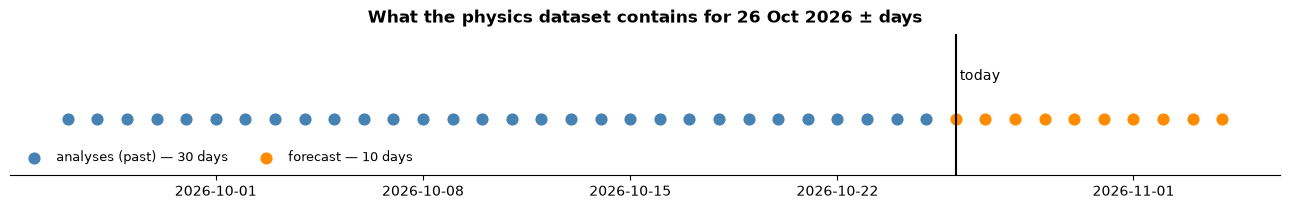

In [43]:
# ============================================================
# STEP 1.1 — OPEN THE FORECAST (no download) AND SEE ITS DATES
# ─────────────────────────────────────────────────────────────
# Which dates are ANALYSES (past) and which are FORECAST (future)?
# ============================================================

ds_sst = stream('SST_FC', START, END)
ds_wav = stream('WAV_FC', START, END)

t_phy = pd.to_datetime(ds_sst.time.values)
t_wav = pd.to_datetime(ds_wav.time.values)
print(f'==> Physics : {len(t_phy)} daily fields   {t_phy[0]:%d %b} -> {t_phy[-1]:%d %b %Y}')
print(f'==> Waves   : {len(t_wav)} fields, every 3 h  {t_wav[0]:%d %b %H:%M} -> {t_wav[-1]:%d %b %Y %H:%M}')
fc_days_available = int((t_phy >= TODAY).sum())
print(f'   Forecast days available from {TODAY:%d %b}: {fc_days_available}')

fig, ax = plt.subplots(figsize=(13, 2.2))
past, fut = t_phy[t_phy < TODAY], t_phy[t_phy >= TODAY]
ax.scatter(past, np.ones(len(past)), s=60, color='steelblue', label=f'analyses (past) — {len(past)} days')
ax.scatter(fut,  np.ones(len(fut)),  s=60, color='darkorange', label=f'forecast — {len(fut)} days')
ax.axvline(TODAY, color='k', lw=1.5); ax.text(TODAY, 1.25, ' today', fontsize=10, va='bottom')
ax.set_yticks([]); ax.set_ylim(0.6, 1.6); ax.legend(loc='lower left', ncol=2, fontsize=9, frameon=False)
ax.set_title(f'What the physics dataset contains for {TODAY:%d %b %Y} ± days')
for s in ['left', 'right', 'top']:
    ax.spines[s].set_visible(False)
plt.show()

### 1.2 — Load today's data once

As on Days 1 and 2: everything the day needs is streamed **once**, reduced, and kept in memory. For your region:

| What | Streamed as | Kept as | Used in |
|---|---|---|---|
| Surface temperature, currents, sea level, mixed layer | daily maps, 30 days past + 10 days forecast | the same (small region) | Sections 2–4 |
| Waves (height, direction, period) | **every 3 hours** | **daily maximum** height (`resample`) | Sections 2, 4 |
| Satellite SST (OSTIA) | daily maps, last 30 days | the same | Section 3 |
| Reanalysis temperature | monthly, 1993–2025 (`CLIM_YEARS`) | one map: the **normal** for this month | Sections 2, 4 |

<div style="border-left:6px solid #009E8A; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#009E8A">⏱️ Start it before the break</b><br>Run Step 1.2 at ~10:40 and let it work over the break. It is smaller than on Days 1–2: one region, 40 days.</div>

In [44]:
# ============================================================
# STEP 1.2 — LOAD TODAY'S DATA ONCE  (the only long step today)
# ─────────────────────────────────────────────────────────────
#   what                    streamed as             kept as
#   SST, currents, SSH, MLD daily, 40 days          the same
#   waves                   every 3 h               daily MAX height, mean direction/period
#   satellite SST           daily, last 30 days     the same
#   reanalysis SST          monthly, CLIM_YEARS     "normal" map for this month
# ============================================================

cur  = stream('CUR_FC', START, END)
ssh  = stream('SSH_FC', START, END)
obs  = stream('SST_OBS', START, TODAY - pd.Timedelta(days=1))
clim = stream('CLIM', f'{CLIM_YEARS[0]}-01-01', f'{CLIM_YEARS[1]}-12-31')['thetao']

surf = lambda da: da.isel(depth=0) if 'depth' in da.dims else da   # the surface level (if there is a depth axis)
rad = np.deg2rad(ds_wav['VMDR'])                       # direction the waves come FROM
lazy = {
    'sst':     surf(ds_sst['thetao']),
    'u':       surf(cur['uo']),
    'v':       surf(cur['vo']),
    'zos':     100 * ssh['zos'],
    'mld':     ssh['mlotst'],
    'hs_max':  ds_wav['VHM0'].resample(time='1D').max(),           # the worst sea state of each day
    'tp':      ds_wav['VTPK'].resample(time='1D').mean(),
    'wdir_x':  (-np.sin(rad)).resample(time='1D').mean(),          # direction the waves GO TO (unit vector)
    'wdir_y':  (-np.cos(rad)).resample(time='1D').mean(),
    'sst_obs': obs['analysed_sst'],
    'clim':    surf(clim.sel(time=clim.time.dt.month == FC_MONTH).mean('time')),
}

t0 = time.time()
print(f'Streaming and reducing Area {MY_AREA} ({len(lazy)} items) — one progress bar:')
with ProgressBar():
    (got,) = dask.compute(lazy)

sst, u, v, zos, mld = got['sst'], got['u'], got['v'], got['zos'], got['mld']
hs_max, tp, wdir_x, wdir_y = got['hs_max'], got['tp'], got['wdir_x'], got['wdir_y']
sst_clim = got['clim']
sst_obs = got['sst_obs']
units = str(obs['analysed_sst'].attrs.get('units', '')).lower()
if units.startswith('k'):                                  # OSTIA is in kelvin -> °C
    sst_obs = sst_obs - 273.15
sst_obs.attrs['units'] = '°C'
speed = np.hypot(u, v)

is_fc = sst.time >= TODAY
fc_dates = pd.to_datetime(sst.time.values[is_fc.values])
mb = sum(x.nbytes for x in [sst, u, v, zos, mld, hs_max, tp, sst_obs, sst_clim]) / 1e6
print(f'\n==> Loaded in {(time.time() - t0) / 60:.1f} min — {mb:.0f} MB in memory')
print(f'   Physics   : {sst.sizes["time"]} days ({int((~is_fc).sum())} analyses + {len(fc_dates)} forecast days)')
print(f'   Waves     : {ds_wav.sizes["time"]} fields (3-hourly) -> {hs_max.sizes["time"]} daily maxima')
print(f'   Satellite : {sst_obs.sizes["time"]} daily SST maps ({units or "units?"} -> °C)')
print(f'   Normal    : month {FC_MONTH}, {CLIM_YEARS[0]}–{CLIM_YEARS[1]} mean')
print('\n   Sections 2–4 now run from memory, in seconds.')

WARNING - 2026-10-26T14:04:47Z - Some of your subset selection [2026-09-26 00:00:00+00:00, 2026-11-04 23:59:59+00:00] for the time dimension exceed the dataset coordinates [2022-06-01 00:00:00+00:00, 2026-11-04 00:00:00+00:00]
WARNING - 2026-10-26T14:04:47Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]
WARNING - 2026-10-26T14:04:52Z - Some of your subset selection [2026-09-26 00:00:00+00:00, 2026-11-04 23:59:59+00:00] for the time dimension exceed the dataset coordinates [2022-06-01 00:00:00+00:00, 2026-11-04 00:00:00+00:00]
WARNING - 2026-10-26T14:04:57Z - Some of your subset selection [2026-09-26 00:00:00+00:00, 2026-10-25 23:59:59+00:00] for the time dimension exceed the dataset coordinates [2024-01-17 00:00:00+00:00, 2026-10-25 00:00:00+00:00]
WARNING - 2026-10-26T14:05:02Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 

Streaming and reducing Area 3 (11 items) — one progress bar:
[########################################] | 100% Completed | 28.00 s

==> Loaded in 0.5 min — 24 MB in memory
   Physics   : 40 days (30 analyses + 10 forecast days)
   Waves     : 320 fields (3-hourly) -> 40 daily maxima
   Satellite : 30 daily SST maps (kelvin -> °C)
   Normal    : month 10, 1993–2025 mean

   Sections 2–4 now run from memory, in seconds.


## Section 2 — The 10-Day Forecast

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Forecast block · 11:05–12:30</span> &nbsp; **MOOC Module 6**

Three questions a forecaster always asks: **what** will happen, **where**, and **when**? We look at maps on three days
(day 1, 5 and 10), then at the time series **at your user's location**.

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_forecast_SST_currents_AGU_20261026.png


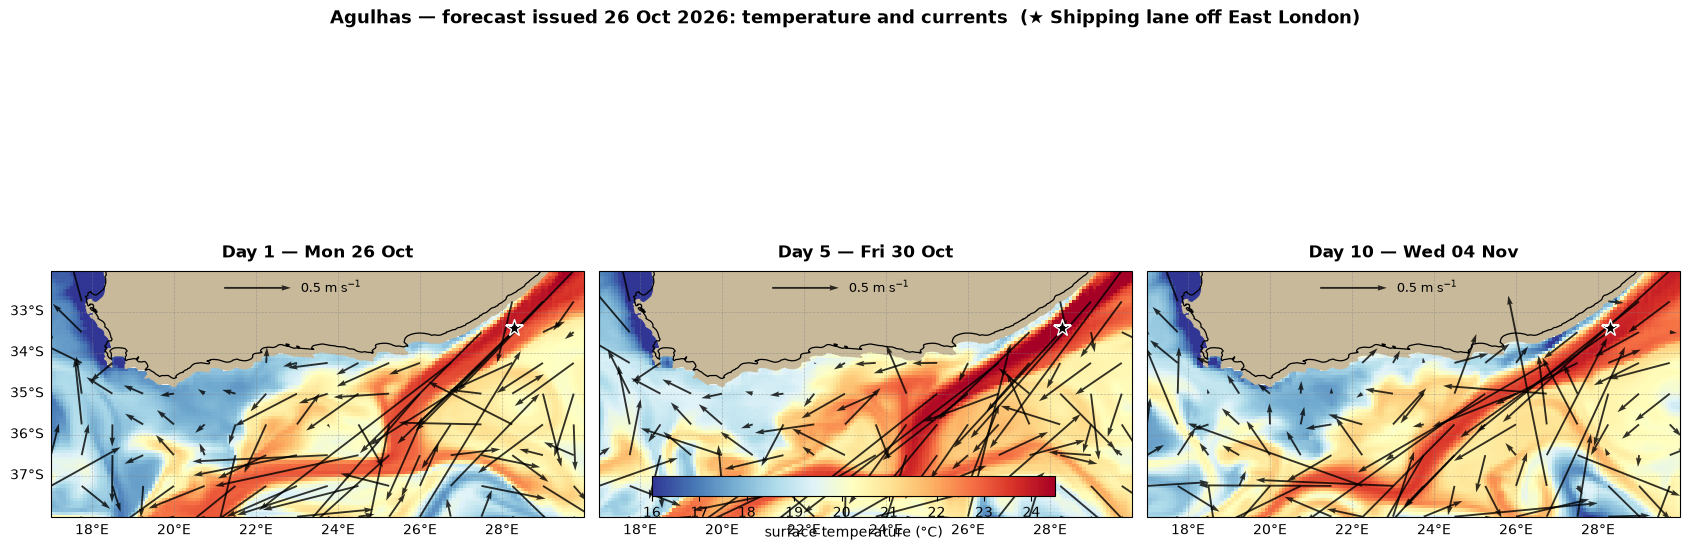

In [45]:
# ============================================================
# STEP 2.1 — FORECAST MAPS: SURFACE TEMPERATURE AND CURRENTS
# ─────────────────────────────────────────────────────────────
# Day 1, day 5 and day 10 of the forecast, same colour scale.
# ============================================================

show = [d for d in [fc_dates[0], fc_dates[min(4, len(fc_dates) - 1)], fc_dates[-1]]]
lo, hi = robust_range(sst.sel(time=fc_dates), step=0.5)
FIG_W = min(17, 3 * 5.0 * (LON_MAX - LON_MIN) / (LAT_MAX - LAT_MIN) + 2.5)   # 3 maps side by side, sized to the region

fig, axes = plt.subplots(1, 3, figsize=(FIG_W, 5.6), subplot_kw={'projection': PC})
fig.subplots_adjust(left=0.04, right=0.97, top=0.82, bottom=0.10, wspace=0.08)
for k, (ax, d) in enumerate(zip(axes, show)):
    p = sst.sel(time=d).plot(ax=ax, transform=PC, cmap='RdYlBu_r', vmin=lo, vmax=hi, extend='both', add_colorbar=False, add_labels=False)
    arrows(ax, u.sel(time=d), v.sel(time=d), n_across=16, scale=4, key=0.5, key_label='0.5 m s$^{-1}$', key_xy=A['key_xy'])
    ax.plot(UPLON, UPLAT, 'k*', ms=13, mec='white', transform=PC, zorder=6)
    decorate(ax, extent=EXTENT, left=(k == 0))
    lead = (d - TODAY).days + 1
    ax.set_title(f'Day {lead} — {d:%a %d %b}')
fig.colorbar(p, ax=axes, orientation='horizontal', fraction=0.05, pad=0.08, label='surface temperature (°C)')
fig.suptitle(f'{DOMAIN_NAME} — forecast issued {TODAY:%d %b %Y}: temperature and currents  (★ {UPNAME})',
             fontsize=13, fontweight='bold', y=0.97)
save_fig(fig, f'Day3_forecast_SST_currents_{FILE_PREFIX}_{STAMP}.png')
plt.show()

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_forecast_waves_AGU_20261026.png


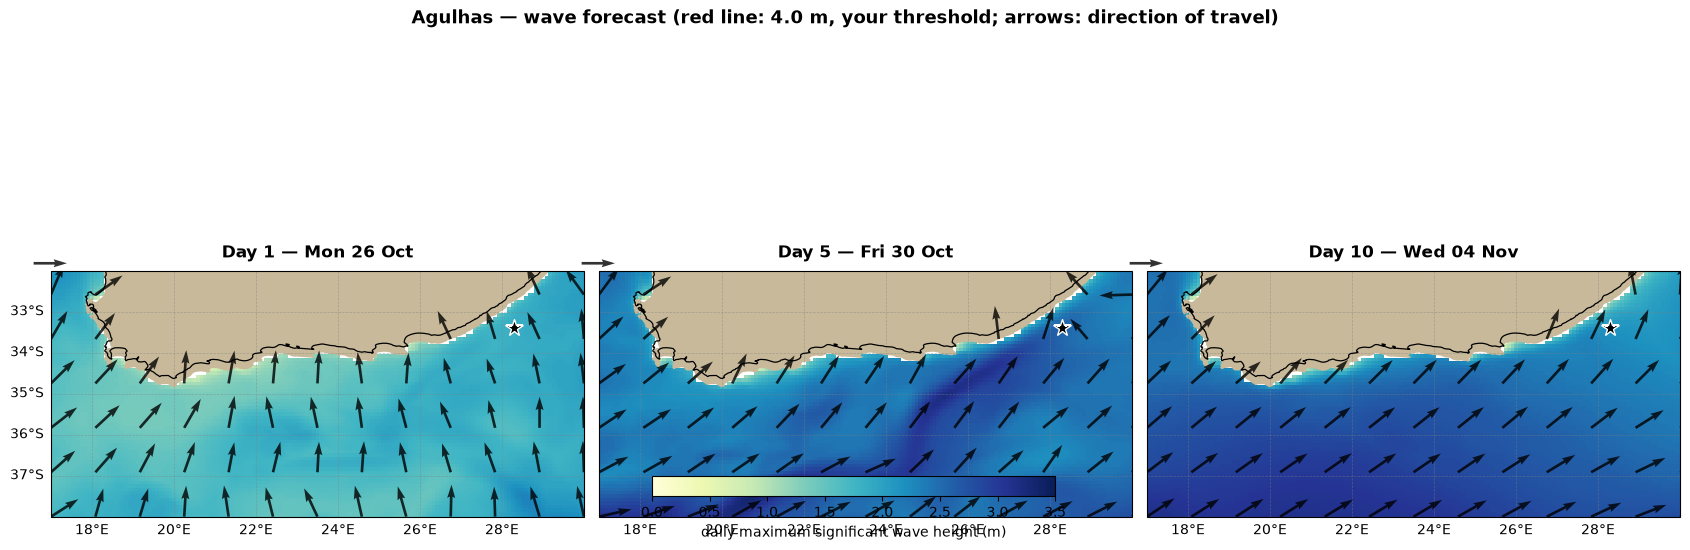

In [46]:
# ============================================================
# STEP 2.2 — FORECAST MAPS: WAVES
# ─────────────────────────────────────────────────────────────
# Daily MAXIMUM significant wave height (from 3-hourly fields),
# arrows = direction the waves travel; red line = your threshold.
# ============================================================

hmax = float(np.ceil(np.nanpercentile(hs_max.sel(time=fc_dates), 98) * 2) / 2)
fig, axes = plt.subplots(1, 3, figsize=(FIG_W, 5.6), subplot_kw={'projection': PC})
fig.subplots_adjust(left=0.04, right=0.97, top=0.82, bottom=0.10, wspace=0.08)
for k, (ax, d) in enumerate(zip(axes, show)):
    h = hs_max.sel(time=d, method='nearest')
    p = h.plot(ax=ax, transform=PC, cmap='YlGnBu', vmin=0, vmax=hmax, extend='max', add_colorbar=False, add_labels=False)
    if float(h.max()) >= TH['hs']:
        ax.contour(h.longitude, h.latitude, h, levels=[TH['hs']], colors='red', linewidths=1.8, transform=PC, zorder=4)
    # arrows(ax, wdir_x.sel(time=d, method='nearest'), wdir_y.sel(time=d, method='nearest'), n_across=12, scale=16,
    #        key=1, key_label='wave direction', key_xy=A['key_xy'], width=0.005, color='black')
    arrows(ax, wdir_x.sel(time=d, method='nearest'), wdir_y.sel(time=d, method='nearest'), n_across=12, scale=16,
       key=1, key_label='', key_xy=(0.03, 1.03), width=0.005, color='black')
    ax.plot(UPLON, UPLAT, 'k*', ms=13, mec='white', transform=PC, zorder=6)
    decorate(ax, extent=EXTENT, left=(k == 0))
    ax.set_title(f'Day {(d - TODAY).days + 1} — {d:%a %d %b}')
fig.colorbar(p, ax=axes, orientation='horizontal', fraction=0.05, pad=0.08, label='daily maximum significant wave height (m)')
fig.suptitle(f'{DOMAIN_NAME} — wave forecast (red line: {TH["hs"]} m, your threshold; arrows: direction of travel)', fontsize=13, fontweight='bold', y=0.97)
save_fig(fig, f'Day3_forecast_waves_{FILE_PREFIX}_{STAMP}.png')
plt.show()

### 🔎 Reading the forecast maps

- **Temperature and currents.** Look for what **changes** between day 1 and day 10: a cold patch growing along the coast (upwelling),
  a warm eddy moving, a current meander shifting. What does not change is usually the large-scale pattern you saw on Days 1–2.
- **Waves.** The **significant wave height** (Hs) is the mean height of the highest third of the waves; individual waves can be
  **almost twice** as high. The **daily maximum** is what matters for safety: a calm morning does not help a boat caught by the afternoon swell.
- Waves along West Africa are mostly **swell** from distant storms (South Atlantic in boreal summer) — they can be high on a calm, windless day.

<div style="border-left:6px solid #E97132; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#E97132">✍️ Your turn (5 min)</b><br>1. On which forecast day are conditions <b>worst</b> at your user's point (★)?<br>2. Does the red threshold line reach the ★ at any time?<br>3. What changes most between day 1 and day 10 in your region: temperature, currents or waves?</div>

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_forecast_user_point_AGU_20261026.png


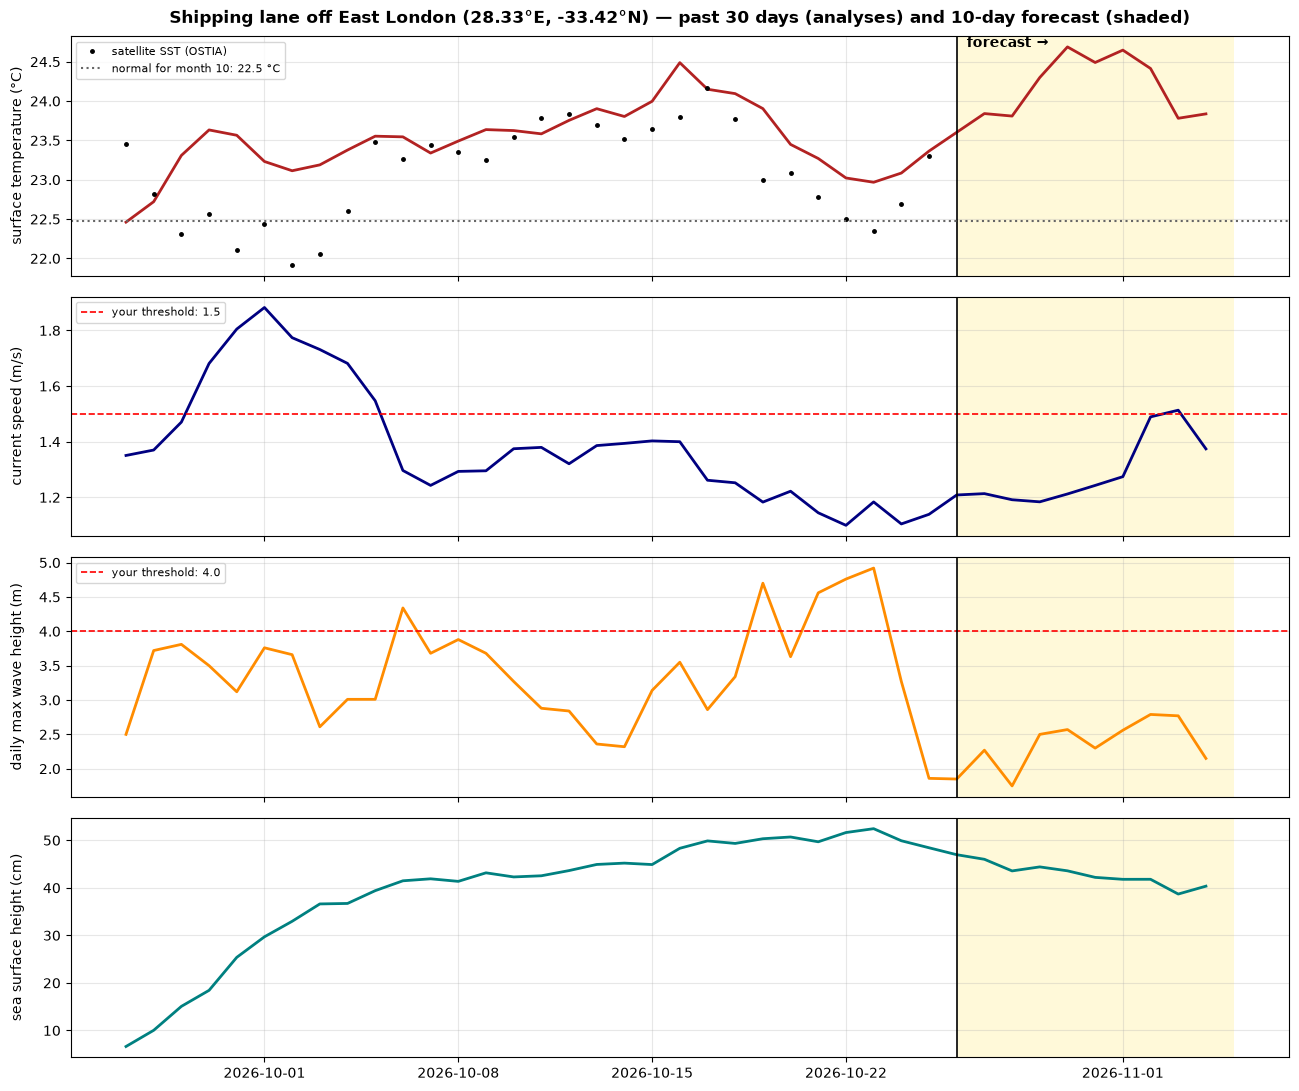

In [47]:
# ============================================================
# STEP 2.3 — THE FORECAST AT YOUR USER'S LOCATION
# ─────────────────────────────────────────────────────────────
# 30 days of analyses (solid) + 10 days of forecast (shaded),
# at the model ocean point nearest to the user point.
# ============================================================

plon, plat = nearest_ocean(sst.isel(time=0), UPLON, UPLAT)
wlon, wlat = nearest_ocean(hs_max.isel(time=0), UPLON, UPLAT)
at = dict(longitude=plon, latitude=plat)
sst_pt  = sst.sel(**at)
spd_pt  = speed.sel(**at)
zos_pt  = zos.sel(**at)
hs_pt   = hs_max.sel(longitude=wlon, latitude=wlat)
clim_pt = float(sst_clim.sel(**at, method='nearest'))
olon, olat = nearest_ocean(sst_obs.isel(time=0), plon, plat)
obs_pt  = sst_obs.sel(longitude=olon, latitude=olat)

fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
series = [(sst_pt, 'surface temperature (°C)', 'firebrick', None),
          (spd_pt, 'current speed (m/s)', 'navy', TH['speed']),
          (hs_pt,  'daily max wave height (m)', 'darkorange', TH['hs']),
          (zos_pt, 'sea surface height (cm)', 'teal', None)]
for ax, (s, label, color, thr) in zip(axes, series):
    ax.axvspan(TODAY, END + pd.Timedelta(days=1), color='gold', alpha=0.15, lw=0)
    ax.plot(s.time, s, color=color, lw=2)
    if thr is not None:
        ax.axhline(thr, color='red', ls='--', lw=1.2, label=f'your threshold: {thr}')
        ax.legend(loc='upper left', fontsize=8)
    ax.axvline(TODAY, color='k', lw=1.2)
    ax.set_ylabel(label); ax.grid(alpha=0.3)
axes[0].plot(obs_pt.time, obs_pt, 'k.', ms=5, label='satellite SST (OSTIA)')
axes[0].axhline(clim_pt, color='0.4', ls=':', lw=1.5, label=f'normal for month {FC_MONTH}: {clim_pt:.1f} °C')
axes[0].legend(loc='upper left', fontsize=8)
axes[0].text(TODAY, axes[0].get_ylim()[1], '  forecast →', va='top', fontsize=10, fontweight='bold')
axes[0].set_title(f'{UPNAME} ({plon:.2f}°E, {plat:.2f}°N) — past 30 days (analyses) and 10-day forecast (shaded)')
fig.align_ylabels(axes)
plt.tight_layout()
save_fig(fig, f'Day3_forecast_user_point_{FILE_PREFIX}_{STAMP}.png')
plt.show()

## Section 3 — How Good Is the Model? Validation

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Validation block · 13:30–15:00</span> &nbsp; **MOOC Module 6**

A forecast is only useful if we know **how much to trust it**. We compare the model with **observations** over the last 30 days,
with two simple scores:

| Score | Formula | Meaning |
|---|---|---|
| **Bias** | mean(model − observation) | Is the model **systematically** too warm (+) or too cold (−)? |
| **RMSE** | √ mean((model − observation)²) | **Typical size** of the error, whatever its sign |

Two independent observing systems: **satellite SST** (OSTIA, the whole surface) and **Argo floats** (profiles down to 2000 m, a few points).

<div style="border-left:6px solid #6B7280; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#6B7280">⚠️ Is it independent?</b><br>The past 30 days are <b>analyses</b>: the model was corrected with observations, including satellite SST and Argo. Agreement is therefore expected and does not prove the <b>forecast</b> is as good. The truly independent test is to compare the forecast with observations made <b>after</b> it was issued — you will do it in Section 8, ten days from now.</div>

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_validation_SST_AGU_20261026.png


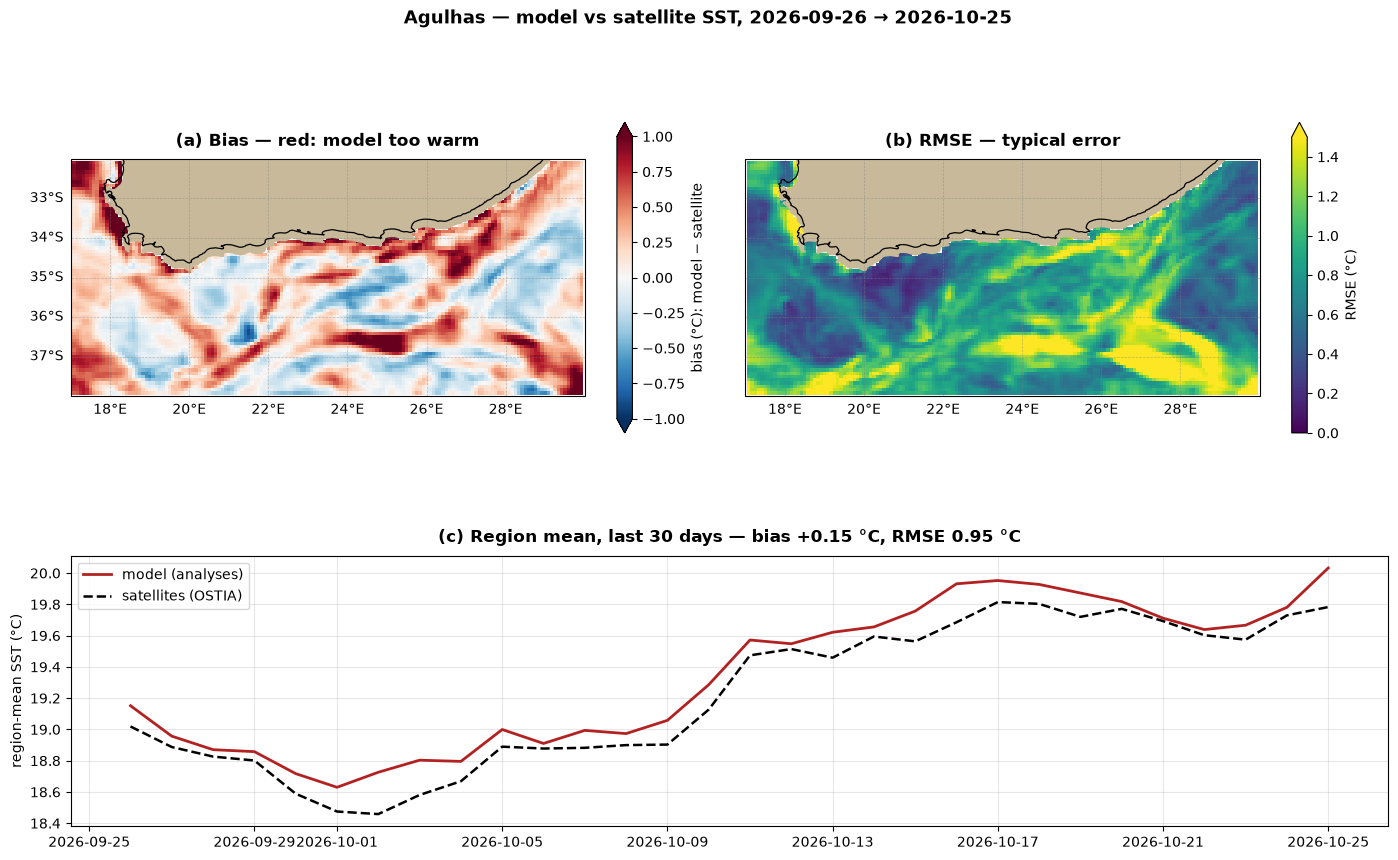

   Region: bias +0.15 °C   RMSE 0.95 °C   at Shipping lane off East London: bias +0.41 °C


In [48]:
# ============================================================
# STEP 3.1 — MODEL vs SATELLITE SST (last 30 days)
# ─────────────────────────────────────────────────────────────
# Satellite SST (0.05°) interpolated onto the model grid (1/12°),
# as on Day 2. Bias and RMSE at every point, and over the region.
# ============================================================

past = sst.sel(time=slice(START, TODAY - pd.Timedelta(days=1)))
obs_on_mod = sst_obs.interp(longitude=past.longitude, latitude=past.latitude)   # satellites on the model grid
obs_on_mod['time'] = obs_on_mod.time.dt.floor('D')                                 # same daily time stamps
past = past.assign_coords(time=past.time.dt.floor('D'))
past, obs_on_mod = xr.align(past, obs_on_mod, join='inner')                       # common days only
err = past - obs_on_mod

bias_map = err.mean('time')
rmse_map = np.sqrt((err ** 2).mean('time'))
bias, rmse = float(err.mean()), float(np.sqrt((err ** 2).mean()))

aspect = (LON_MAX - LON_MIN) / (LAT_MAX - LAT_MIN)            # width / height of the box
W = min(17, max(11, 2 * (5.2 * aspect + 1.8) + 1))             # two maps + their colour bars
fig = plt.figure(figsize=(W, 9.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1.35, 1], hspace=0.30, wspace=0.05)
ax = fig.add_subplot(gs[0, 0], projection=PC)
bias_map.plot(ax=ax, transform=PC, cmap='RdBu_r', vmin=-1, vmax=1, extend='both', add_labels=False,
              cbar_kwargs={'label': 'bias (°C): model − satellite', 'shrink': 0.85})
decorate(ax, extent=EXTENT); ax.set_title('(a) Bias — red: model too warm')
ax = fig.add_subplot(gs[0, 1], projection=PC)
rmse_map.plot(ax=ax, transform=PC, cmap='viridis', vmin=0, vmax=1.5, extend='max', add_labels=False,
              cbar_kwargs={'label': 'RMSE (°C)', 'shrink': 0.85})
decorate(ax, extent=EXTENT, left=False); ax.set_title('(b) RMSE — typical error')
ax = fig.add_subplot(gs[1, :])
ax.plot(past.time, past.mean(['latitude', 'longitude']), color='firebrick', lw=2, label='model (analyses)')
ax.plot(obs_on_mod.time, obs_on_mod.mean(['latitude', 'longitude']), 'k--', lw=1.8, label='satellites (OSTIA)')
ax.set_ylabel('region-mean SST (°C)'); ax.grid(alpha=0.3); ax.legend(loc='best')
ax.set_title(f'(c) Region mean, last {PAST_DAYS} days — bias {bias:+.2f} °C, RMSE {rmse:.2f} °C')
fig.suptitle(f'{DOMAIN_NAME} — model vs satellite SST, {past.time.values[0].astype(str)[:10]} → {past.time.values[-1].astype(str)[:10]}',
             fontsize=13, fontweight='bold', y=0.97)
save_fig(fig, f'Day3_validation_SST_{FILE_PREFIX}_{STAMP}.png')
plt.show()
print(f'   Region: bias {bias:+.2f} °C   RMSE {rmse:.2f} °C   '
      f'at {UPNAME}: bias {float(bias_map.sel(**at, method="nearest")):+.2f} °C')

### 3.2 — Below the surface: Argo floats

**Argo** is a global array of ~4000 robotic floats. Each one drifts at 1000 m, dives to 2000 m every 10 days, then rises to the surface
measuring **temperature and salinity**, and sends the profile by satellite. They are the main source of information on the ocean
**interior** — and one of the observations assimilated by the model (Day 2, Module 4).

We read the profiles of the last 30 days in your region with the **argopy** library (an internet service, separate from
Copernicus Marine), and compare each one with the model on the same day, at the same place, at the same depth.

<div style="border-left:6px solid #6B7280; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#6B7280"> If Argo does not answer</b><br>The Argo data server is sometimes slow or down. If Step 3.2 fails, read the message, go on to Step 3.3 and come back later — nothing else depends on it.</div>

In [49]:
# ============================================================
# STEP 3.2a — IN SITU DATA: READ AND MATCH WITH THE MODEL
# ─────────────────────────────────────────────────────────────
# 1. read_dataframe(): every good-quality temperature measurement
#    in your area, 0–500 m (a TABLE: one row per measurement)
# 2. SURFACE (0–5 m): one value per platform per day, against the
#    model surface temperature already in memory
# 3. WITH DEPTH: the profiles (Argo floats, moorings) against the
#    model profile on the same day, at the nearest ocean point
# The figure is drawn in Step 3.2b.
# ============================================================

INSITU_DS = 'cmems_obs-ins_glo_phybgcwav_mynrt_na_irr'      # Global Ocean In-Situ Near-Real-Time Observations
MAX_DEPTH = 500
NAMES = {'PF': 'Argo float', 'MO': 'mooring', 'TS': 'ship (TSG)', 'DB': 'drifting buoy', 'GL': 'glider',
         'CT': 'CTD', 'XB': 'XBT', 'BO': 'bottle', 'FB': 'ferrybox'}
PRECISE = ('PF', 'DB', 'MO', 'CT', 'GL')                     # precise scientific instruments
part = 'latest' if START >= pd.Timestamp.now().normalize() - pd.Timedelta(days=45) else 'history'   # latest ≈ last 30 days

# ---- 1. read ------------------------------------------------
insitu_ok = False
try:
    t0 = time.time()
    ins = copernicusmarine.read_dataframe(
        dataset_id=INSITU_DS, dataset_part=part, variables=['TEMP'],
        start_datetime=f'{START:%Y-%m-%d}T00:00:00', end_datetime=f'{TODAY:%Y-%m-%d}T00:00:00',
        minimum_depth=0, maximum_depth=MAX_DEPTH, **BOX)
    ins = ins.reset_index() if 'time' not in ins.columns else ins
    if 'value_qc' in ins.columns:
        ins = ins[ins['value_qc'] == 1]                        # keep only data flagged "good"
    ins = ins.dropna(subset=['value']).copy()
    ZCOL = 'depth' if 'depth' in ins.columns else 'pressure'  # pressure (dbar) ≈ depth (m)
    PTYPE = 'platform_type' if 'platform_type' in ins.columns else 'platform_id'
    ins['day'] = pd.to_datetime(ins['time'], utc=True).dt.tz_localize(None).dt.floor('D')
    ins['platform'] = ins[PTYPE].map(lambda c: f'{c} — {NAMES.get(str(c), "other")}')
    insitu_ok = len(ins) > 0
    print(f'==> {len(ins):,} good-quality temperature measurements from {ins["platform_id"].nunique()} platforms '
          f'({part} part, {time.time() - t0:.0f} s)')
    if insitu_ok:
        display(ins.groupby('platform').agg(measurements=('value', 'size'), platforms=('platform_id', 'nunique'),
                                            deepest_m=(ZCOL, 'max')).round(0))
except Exception as e:
    print(f'❌ In situ data not available ({type(e).__name__}: {str(e)[:150]}). Go on to Step 3.3.')

daily, errs = pd.DataFrame(), pd.DataFrame(columns=['depth', 'err', 'type'])
if insitu_ok:
    # ---- 2. SURFACE: one value per platform, per day, per model cell — model from memory (sst)
    surf_obs = ins[ins[ZCOL] <= 5].copy()
    res = float(abs(sst.latitude[1] - sst.latitude[0]))
    surf_obs['cell_lat'] = (surf_obs['latitude'] / res).round() * res
    surf_obs['cell_lon'] = (surf_obs['longitude'] / res).round() * res
    daily = (surf_obs.groupby(['platform_id', 'platform', PTYPE, 'day', 'cell_lat', 'cell_lon'], as_index=False)
                     .agg(latitude=('latitude', 'mean'), longitude=('longitude', 'mean'), value=('value', 'mean')))
    daily = daily[(daily['day'] >= pd.Timestamp(sst.time.values[0])) & (daily['day'] < TODAY)]
    if len(daily):
        m = sst.sel(time=xr.DataArray(daily['day'].values, dims='obs'),
                    latitude=xr.DataArray(daily['latitude'].values, dims='obs'),
                    longitude=xr.DataArray(daily['longitude'].values, dims='obs'), method='nearest')
        daily['model'] = m.values
        daily = daily.dropna(subset=['model'])
        daily['diff'] = daily['model'] - daily['value']
        daily['outlier'] = daily['diff'].abs() > 3                          # gross errors, left out of the scores
        daily['precise'] = daily[PTYPE].astype(str).isin(PRECISE)

    # ---- 3. WITH DEPTH: profiles = one platform on one day with several depths
    prof_obs = ins[ins[PTYPE].astype(str).isin(['PF', 'MO', 'CT', 'GL', 'XB'])]
    groups = [(k, g.sort_values(ZCOL)) for k, g in prof_obs.groupby(['platform_id', 'day'])
              if g[ZCOL].nunique() >= 4 and g[ZCOL].max() >= 50]
    if groups:
        t3d = stream('SST_FC', START, TODAY, service='arco-time-series', maximum_depth=MAX_DEPTH)['thetao']
        lazy_mod = [t3d.sel(longitude=float(g.longitude.mean()), latitude=float(g.latitude.mean()), method='nearest')
                       .sel(time=day, method='nearest') for (pid, day), g in groups]
        with ProgressBar():
            mod_profiles = dask.compute(*lazy_mod)
        rows = []
        for ((pid, day), g), mp in zip(groups, mod_profiles):
            mp = mp.dropna('depth')
            if mp.sizes['depth'] < 3:
                continue                                         # model point on land / too shallow
            obs_z = g.groupby(ZCOL)['value'].mean()
            mod_at = np.interp(obs_z.index.values, mp.depth.values, mp.values, left=np.nan, right=np.nan)
            rows.append(pd.DataFrame({'depth': obs_z.index.values, 'err': mod_at - obs_z.values,
                                      'type': str(g[PTYPE].iloc[0]), 'profile': f'{pid} {day:%d %b}'}))
        if rows:
            errs = pd.concat(rows).dropna()
    n_prof = errs['profile'].nunique() if len(errs) else 0

    # ---- scores ---------------------------------------------------
    score = lambda e: pd.Series({'n': len(e), 'bias': e.mean(), 'RMSE': np.sqrt((e ** 2).mean())})
    if len(daily):
        good = daily[~daily['outlier']]
        surf_scores = good.groupby('platform')['diff'].apply(score).unstack()
        surf_scores.loc['ALL (no outliers)'] = score(good['diff'])
        surf_scores.loc['PRECISE only (floats, buoys, moorings)'] = score(good.loc[good['precise'], 'diff'])
        print('\n   SURFACE (0–5 m) — model − in situ (°C):')
        display(surf_scores.round(2))
    if len(errs):
        errs['band'] = pd.cut(errs['depth'], [0, 10, 25, 50, 75, 100, 150, 200, 300, 400, 500])
        by_depth = errs.groupby('band', observed=True)['err'].apply(score).unstack()
        print(f'   WITH DEPTH — {n_prof} profiles, model − in situ (°C):')
        display(by_depth.round(2))

100%|██████████| [00:03<00:00]

==> 8,732 good-quality temperature measurements from 72 platforms (latest part, 18 s)


,measurements,platforms,deepest_m
platform,,,
DB — drifting buoy,313,5,0.0
PF — Argo float,8240,10,500.0
TS — ship (TSG),179,57,-0.0


WARNING - 2026-10-26T14:07:49Z - Some of your subset selection [0.0, 500.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


[########################################] | 100% Completed | 19.23 s

   SURFACE (0–5 m) — model − in situ (°C):


,n,bias,RMSE
platform,,,
DB — drifting buoy,91.0,0.48,1.14
PF — Argo float,22.0,-0.07,0.75
TS — ship (TSG),152.0,-0.28,1.28
ALL (no outliers),265.0,-0.00,1.20
"PRECISE only (floats, buoys, moorings)",113.0,0.37,1.08


   WITH DEPTH — 22 profiles, model − in situ (°C):


,n,bias,RMSE
band,,,
"(0, 10]",607.0,0.13,0.70
"(10, 25]",881.0,0.12,0.70
"(25, 50]",1510.0,0.17,0.75
"(50, 75]",458.0,0.16,0.82
"(75, 100]",511.0,0.46,1.10
"(100, 150]",575.0,0.03,1.11
"(150, 200]",574.0,0.06,1.27
"(200, 300]",1149.0,0.04,1.24
"(300, 400]",1048.0,-0.03,1.24


==> Saved: ~/OPERA_Workshop/Day3/output/Day3_validation_insitu_AGU_20261026.png


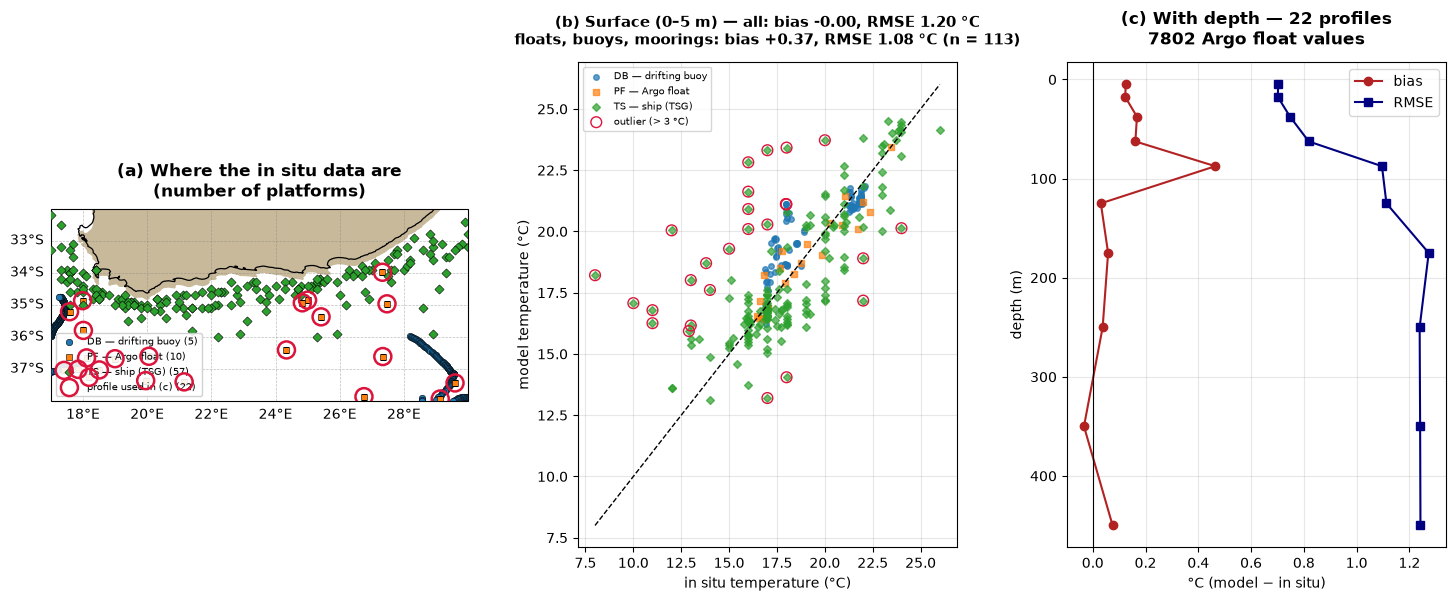

In [50]:
# ============================================================
# STEP 3.2b — IN SITU VALIDATION: THE FIGURE
# ─────────────────────────────────────────────────────────────
# (a) where the data are · (b) surface · (c) with depth
# Runs from memory: re-run it freely after changing the figure.
# ============================================================

if not insitu_ok:
    print('No in situ data — go on to Step 3.3.')
else:
    fig = plt.figure(figsize=(18, 6.3))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.1, 1, 1], wspace=0.28)

    # (a) where
    ax = fig.add_subplot(gs[0], projection=PC)
    for i, (pname, g) in enumerate(ins.drop_duplicates(['platform_id', 'time', 'latitude', 'longitude']).groupby('platform')):
        ax.scatter(g['longitude'], g['latitude'], s=22, marker='osD^vP*X'[i % 8], edgecolor='k', lw=0.4,
                   label=f'{pname} ({g["platform_id"].nunique()})', transform=PC, zorder=5)
    # decorate(ax, extent=EXTENT)
    # ax.legend(fontsize=7, loc='lower left', framealpha=0.9)

    if len(errs):                                  # the profiles used in panel (c)
        used = set(errs['profile'])
        pp = [(float(g['longitude'].mean()), float(g['latitude'].mean())) for (pid, day), g in groups
              if f'{pid} {day:%d %b}' in used]
        if pp:
            ax.scatter(*zip(*pp), s=150, facecolors='none', edgecolors='crimson', lw=1.8, transform=PC, zorder=6,
                       label=f'profile used in (c) ({len(pp)})')
    decorate(ax, extent=EXTENT)
    ax.legend(fontsize=7, loc='lower left', framealpha=0.9)
    
    ax.set_title('(a) Where the in situ data are\n(number of platforms)')

    # (b) surface
    ax = fig.add_subplot(gs[1])
    if len(daily):
        for i, (pname, g) in enumerate(daily.groupby('platform')):
            ax.scatter(g['value'], g['model'], s=16, alpha=0.7, marker='osD^vP*X'[i % 8], label=pname)
        out = daily[daily['outlier']]
        ax.scatter(out['value'], out['model'], s=60, facecolors='none', edgecolors='crimson', label='outlier (> 3 °C)')
        lo_, hi_ = float(daily[['value', 'model']].min().min()), float(daily[['value', 'model']].max().max())
        ax.plot([lo_, hi_], [lo_, hi_], 'k--', lw=1)
        a_, p_ = surf_scores.loc['ALL (no outliers)'], surf_scores.loc['PRECISE only (floats, buoys, moorings)']
        ax.set_title(f'(b) Surface (0–5 m) — all: bias {a_.bias:+.2f}, RMSE {a_.RMSE:.2f} °C\n'
                     f'floats, buoys, moorings: bias {p_.bias:+.2f}, RMSE {p_.RMSE:.2f} °C (n = {int(p_.n)})', fontsize=10.5)
        ax.legend(fontsize=7)
    ax.set_xlabel('in situ temperature (°C)'); ax.set_ylabel('model temperature (°C)'); ax.grid(alpha=0.3)

    # (c) with depth
    ax = fig.add_subplot(gs[2])
    if len(errs):
        mid = [b_.mid for b_ in by_depth.index]
        ax.plot(by_depth['bias'], mid, 'o-', color='firebrick', label='bias')
        ax.plot(by_depth['RMSE'], mid, 's-', color='navy', label='RMSE')
        ax.axvline(0, color='k', lw=0.8); ax.invert_yaxis(); ax.legend()
        ax.set_title(f'(c) With depth — {n_prof} profiles\n'
                     + ', '.join(f'{n} {NAMES.get(t, t)} values' for t, n in errs.groupby('type').size().items()))
    else:
        ax.text(0.5, 0.5, 'No profiles in your area\nin the last 30 days', ha='center', va='center', transform=ax.transAxes)
    ax.set_xlabel('°C (model − in situ)'); ax.set_ylabel('depth (m)'); ax.grid(alpha=0.3)

    save_fig(fig, f'Day3_validation_insitu_{FILE_PREFIX}_{STAMP}.png')
    plt.show()

In [51]:
# Which Argo floats are in panel (c), and how good is the model for each profile?
per_prof = errs.groupby('profile')['err'].agg(values='size', bias='mean', RMSE=lambda e: np.sqrt((e ** 2).mean()),
                                              deepest_m=lambda e: errs.loc[e.index, 'depth'].max())
per_prof['float'] = [p.split(' ')[0] for p in per_prof.index]
print(f'{per_prof["float"].nunique()} floats, {len(per_prof)} profiles:')
display(per_prof.sort_values('float').round(2))
print('\nPer float:')
display(per_prof.groupby('float').agg(profiles=('values', 'size'), bias=('bias', 'mean'), RMSE=('RMSE', 'mean')).round(2))

10 floats, 22 profiles:


,values,bias,RMSE,deepest_m,float
profile,,,,,
1902276 01 Oct,650,0.41,0.72,453.70,1902276
1902276 11 Oct,649,0.21,0.50,453.70,1902276
1902417 09 Oct,513,-0.14,0.20,453.70,1902417
1902417 18 Oct,520,0.94,0.98,453.70,1902417
1902417 30 Sep,521,0.35,0.57,453.70,1902417
1902905 05 Oct,38,0.37,0.50,437.80,1902905
1902905 26 Sep,39,-0.32,0.41,437.90,1902905
3901830 23 Oct,898,1.28,1.32,453.70,3901830
4903915 09 Oct,635,-0.53,0.66,453.70,4903915



Per float:


,profiles,bias,RMSE
float,,,
1902276,2,0.31,0.61
1902417,3,0.38,0.58
1902905,2,0.03,0.46
3901830,1,1.28,1.32
4903915,1,-0.53,0.66
4903991,2,0.42,0.65
4903993,2,0.25,0.50
5906633,3,-0.58,2.10
6903149,3,-0.56,0.70


==> Saved: ~/OPERA_Workshop/Day3/output/Day3_validation_profiles_AGU_20261026.png


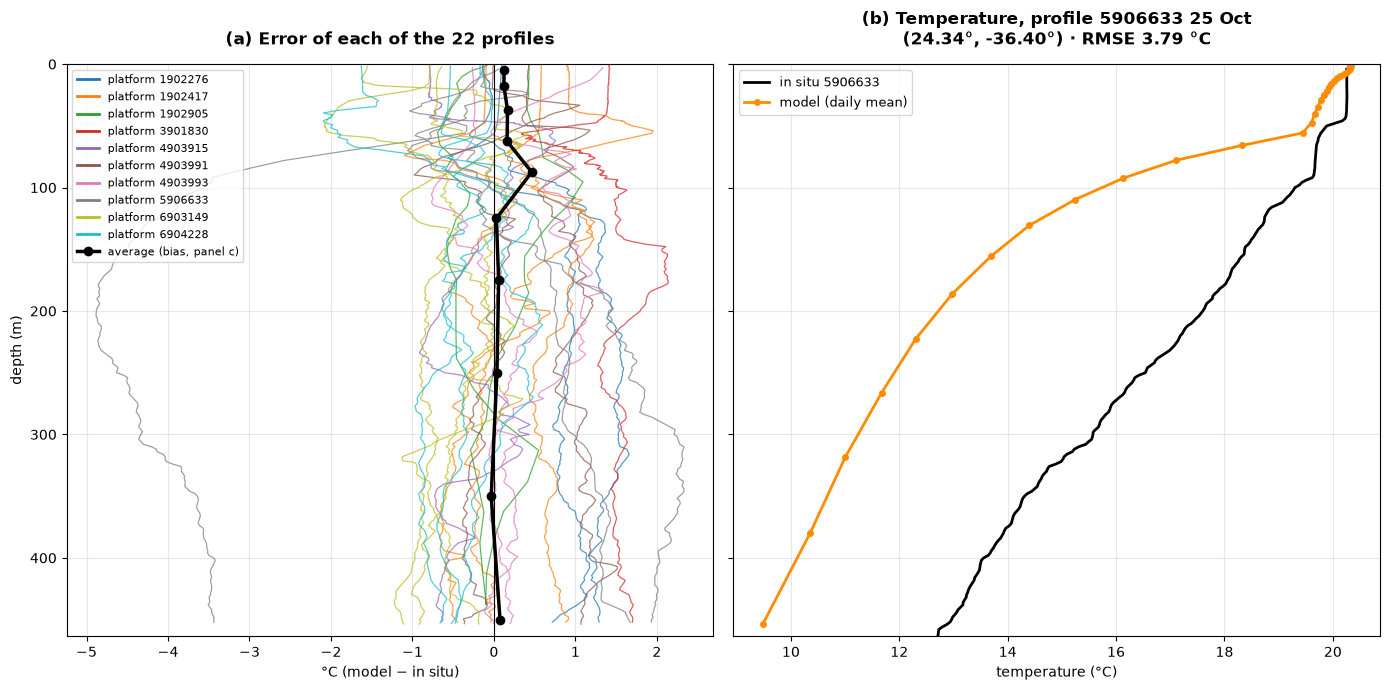

In [52]:
# ============================================================
# STEP 3.2c — OPTIONAL: THE PROFILES ONE BY ONE
# (a) the error of each profile (thin lines, one colour per float) and their average (thick)
# (b) temperature: in situ vs model for ONE profile (the worst one by default)
# Runs from memory (errs, groups, mod_profiles from Step 3.2a).
# ============================================================

SHOW_PROFILE = None      # <- e.g. '3902476 25 Oct' to choose one; None = the profile with the largest RMSE

if not len(errs):
    print('No profiles in your area — nothing to show.')
else:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
    floats = sorted({p.split(' ')[0] for p in errs['profile']})
    col = dict(zip(floats, plt.cm.tab10.colors))
    for p, e in errs.groupby('profile'):
        e = e.sort_values('depth')
        fl = p.split(' ')[0]
        ax1.plot(e['err'], e['depth'], '-', lw=0.9, alpha=0.75, color=col[fl])
    for fl in floats:
        ax1.plot([], [], color=col[fl], lw=2, label=f'platform {fl}')
    ax1.plot(by_depth['bias'], [b_.mid for b_ in by_depth.index], 'k-o', lw=2.5, label='average (bias, panel c)')
    ax1.axvline(0, color='k', lw=0.8); ax1.invert_yaxis(); ax1.grid(alpha=0.3); ax1.legend(fontsize=8)
    ax1.set_xlabel('°C (model − in situ)'); ax1.set_ylabel('depth (m)')
    ax1.set_title(f'(a) Error of each of the {errs["profile"].nunique()} profiles')

    rms = errs.groupby('profile')['err'].apply(lambda e: np.sqrt((e ** 2).mean()))
    pick = SHOW_PROFILE if SHOW_PROFILE in rms.index else rms.idxmax()
    for ((pid, day), g), mp in zip(groups, mod_profiles):
        if f'{pid} {day:%d %b}' == pick:
            obs_z = g.groupby(ZCOL)['value'].mean()
            mp = mp.dropna('depth')
            ax2.plot(obs_z.values, obs_z.index, 'k-', lw=2, label=f'in situ {pid}')
            ax2.plot(mp.values, mp.depth, 'o-', color='darkorange', ms=4, lw=2, label='model (daily mean)')
            ax2.set_title(f'(b) Temperature, profile {pick}\n'
                          f'({float(g.longitude.mean()):.2f}°, {float(g.latitude.mean()):.2f}°) · RMSE {rms[pick]:.2f} °C')
            break
    ax2.set_ylim(min(MAX_DEPTH, float(errs['depth'].max()) + 10), 0)
    ax2.set_xlabel('temperature (°C)'); ax2.grid(alpha=0.3); ax2.legend(fontsize=9)
    plt.tight_layout()
    save_fig(fig, f'Day3_validation_profiles_{FILE_PREFIX}_{STAMP}.png')
    plt.show()

### 3.3 — 🔎 What the scores tell your user

- **Surface (Step 3.1).** In most regions the bias is within a few tenths of a degree and the RMSE below ~0.5–1 °C. Errors are
  usually **largest near the coast and in fronts** (upwelling edges, eddies), where small position errors give large temperature errors.
- **Below the surface (Step 3.2).** The error is usually **largest around the thermocline** (tens to ~150 m deep): there the temperature
  changes fastest with depth, so a thermocline a few metres too deep or too shallow gives errors of 1–2 °C.
- **For the forecast:** errors grow with lead time. A reasonable working rule: days **1–3** reliable, days **4–7** useful for trends,
  days **8–10** indicative only.

<div style="border-left:6px solid #E97132; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#E97132">✍️ Your turn (10 min) — your confidence statement</b><br>Complete, with your numbers: <i>“Over the last 30 days the model surface temperature differed from satellites by … °C on average (RMSE … °C), and below the surface by up to … °C around … m. We therefore have <b>high / medium / low</b> confidence in the forecast for days 1–3, and …”</i>. It goes into your bulletin.</div>

## Section 4 — Application 1: Search and Rescue — Where Is the Drifting Object?

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Application block 1 · 13:30–15:00</span> &nbsp; **MOOC Module 7 — Downstream applications · ETOOFS Guide 11.2.2**

A person falls overboard, a pirogue loses its engine, a life raft is launched. The **Maritime Rescue Coordination Centre** knows only
the **last known position** (LKP) and time. Its question to the ocean forecaster is always the same: **where should we search now, and
where tomorrow?** Search and rescue is the first user of surface-current forecasts: about three quarters of the uses of Météo-France's
drift model MOTHY are searches for people or objects (ETOOFS Guide, 11.2.2).

### What moves a drifting object

```
  drift velocity  =  ocean current  +  tidal current  +  Stokes drift  +  leeway
                      (circulation)      (tides)          (waves)          (wind on the object)
                     └──────────── Copernicus Marine SMOC: "total" surface current ────────────┘   └ wind ┘
```

| Component | What it is | Dataset used today |
|---|---|---|
| **Ocean current** | the circulation of Days 1–3 (eddies, coastal currents, the Agulhas…) | SMOC `uo, vo` (hourly, 1/12°) |
| **Tidal current** | goes back and forth twice a day; strong on wide shelves | SMOC `utide, vtide` |
| **Stokes drift** | the slow push of the waves on everything floating | SMOC `vsdx, vsdy` |
| **Total surface current** | the sum of the three | SMOC `utotal, vtotal` |
| **Leeway** | the wind pushes the part of the object above water: ~1 % of the wind speed for a person, ~3–4 % for a raft | observed winds (satellites + model) |

The **SMOC** dataset (*Surface and Merged Ocean Currents*, part of the global physics analysis and forecast you used this morning) gives these
components **every hour**, with the past analyses and a **10-day forecast**.

### Your drift model

Real centres use models such as MOTHY, OpenDrift or SAROPS. Today you run a **small drift model written in this notebook** (Step 4.3): it
follows **500 virtual particles** released around the LKP, moves them with the currents (and the wind), adds a little random motion for
what the model cannot resolve, and stops those that reach the coast. The spread of the particles **is** the search area.

==> Case, area 3: A seafarer fell overboard from a bulk carrier on the coastal route off East London.
[########################################] | 100% Completed | 30.51 s

==> Hourly surface currents: 188 hours, 84 × 85 points, 43 MB, 36 s
   21 Oct 06:00 -> 29 Oct 2026 01:00 UTC
[########################################] | 100% Completed | 4.83 ss
==> Observed winds: 72 fields, 22 Oct 00:00 -> 24 Oct 23:00 UTC


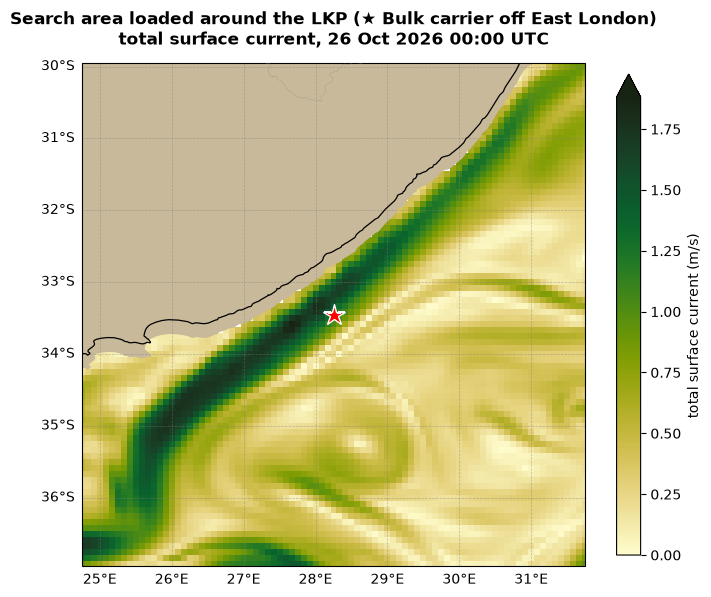

In [53]:
# ============================================================
# STEP 4.1 — YOUR CASE, AND THE HOURLY SURFACE CURRENTS (one stream)
# ─────────────────────────────────────────────────────────────
# The last known position (LKP) of your region's case, the object,
# and the currents around it: 4 days of analyses + 3 days of forecast,
# every hour. Change the case if your subgroup prefers another one.
# ============================================================

LKP_LON, LKP_LAT, LKP_NAME = A['sar']['lkp']        # last known position (change it if you like)
print(f"==> Case, area {MY_AREA}: {A['sar']['story']}")

OBJECTS = {                       # leeway = fraction of the 10 m wind speed (approximate SAR values)
    'person':  ('Person in the water',          0.011),
    'raft':    ('Life raft without drogue',     0.035),
    'pirogue': ('Pirogue / small boat adrift',  0.030),
}
OBJECT     = 'person'             # <- 'person', 'raft' or 'pirogue'
N_PART     = 500                  # virtual particles
RADIUS_KM  = 1.0                  # uncertainty of the last known position (km)
K_DIFF     = 10.0                 # random motion the model cannot resolve (m²/s)
SAR_HALF   = 3.5                  # half-width of the area loaded around the LKP (degrees)

REPLAY_T0  = TODAY - pd.Timedelta(days=4) + pd.Timedelta(hours=6)     # Scenario A: alarm 4 days ago, 06:00 UTC
REPLAY_H   = 48                                                       #             followed for 48 h (analyses)
FC_T0      = TODAY                                                    # Scenario B: alarm today, 00:00 UTC
FC_H       = 72                                                       #             forecast for 72 h

SAR_BOX = dict(minimum_longitude=LKP_LON - SAR_HALF, maximum_longitude=LKP_LON + SAR_HALF,
               minimum_latitude=LKP_LAT - SAR_HALF,  maximum_latitude=LKP_LAT + SAR_HALF)
s0, s1 = REPLAY_T0 - pd.Timedelta(days=1), FC_T0 + pd.Timedelta(hours=FC_H + 1)

t0 = time.time()
smoc = stream('TOTAL_CUR', s0, s1, box=SAR_BOX)
smoc = smoc.isel(depth=0) if 'depth' in smoc.dims else smoc
smoc = smoc.sel(time=slice(s0, s1))
with ProgressBar():
    smoc = smoc.compute()
print(f'\n==> Hourly surface currents: {smoc.sizes["time"]} hours, {smoc.sizes["latitude"]} × {smoc.sizes["longitude"]} points, '
      f'{smoc.nbytes / 1e6:.0f} MB, {time.time() - t0:.0f} s')
print(f'   {pd.Timestamp(smoc.time.values[0]):%d %b %H:%M} -> {pd.Timestamp(smoc.time.values[-1]):%d %b %Y %H:%M} UTC')

sp0 = np.hypot(smoc['utotal'], smoc['vtotal']).sel(time=FC_T0, method='nearest')
if not np.isfinite(float(sp0.sel(longitude=LKP_LON, latitude=LKP_LAT, method='nearest'))):
    LKP_LON, LKP_LAT = nearest_ocean(sp0, LKP_LON, LKP_LAT)
    print(f'   The LKP falls on land in the model grid: moved to the nearest sea point ({LKP_LON:.2f}°, {LKP_LAT:.2f}°).')

wind = None
try:                                       # observed winds, for the leeway (replay only: they are observations, not a forecast)
    w = stream('WIND', REPLAY_T0 - pd.Timedelta(hours=3), REPLAY_T0 + pd.Timedelta(hours=REPLAY_H + 3), box=SAR_BOX)
    wu = next(v for v in w.data_vars if v.startswith('eastward_wind') or w[v].attrs.get('standard_name') == 'eastward_wind')
    wv = next(v for v in w.data_vars if v.startswith('northward_wind') or w[v].attrs.get('standard_name') == 'northward_wind')
    with ProgressBar():
        wind = w[[wu, wv]].rename({wu: 'u10', wv: 'v10'}).compute()
    print(f'==> Observed winds: {wind.sizes["time"]} fields, {pd.Timestamp(wind.time.values[0]):%d %b %H:%M} -> '
          f'{pd.Timestamp(wind.time.values[-1]):%d %b %H:%M} UTC')
    ok = wind['u10'].notnull().any(['latitude', 'longitude'])
    w_end = pd.Timestamp(wind.time.values[ok.values][-1]) if ok.any() else None
    if w_end is not None and w_end < REPLAY_T0 + pd.Timedelta(hours=REPLAY_H):
        print(f'   Note: observed winds stop at {w_end:%d %b %H:%M} UTC (satellite winds arrive with a delay).\n'
              f'   After that, drift 3 continues with the currents only (no leeway).')
except Exception as e:
    print(f'   Winds not available ({type(e).__name__}): the replay will run without leeway.')

fig, ax = plt.subplots(figsize=(7, 6.5), subplot_kw={'projection': PC})
spd_now = np.hypot(smoc['utotal'], smoc['vtotal']).sel(time=FC_T0, method='nearest')
spd_now.plot(ax=ax, transform=PC, cmap=cmocean.cm.speed, vmin=0, extend='max', add_labels=False,
             cbar_kwargs={'label': 'total surface current (m/s)', 'shrink': 0.8})
ax.plot(LKP_LON, LKP_LAT, 'r*', ms=16, mec='white', transform=PC, zorder=6)
decorate(ax, extent=[SAR_BOX['minimum_longitude'], SAR_BOX['maximum_longitude'], SAR_BOX['minimum_latitude'], SAR_BOX['maximum_latitude']])
ax.set_title(f'Search area loaded around the LKP (★ {LKP_NAME})\ntotal surface current, {FC_T0:%d %b %Y} 00:00 UTC')
plt.show()

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_SAR_currents_AGU_20261026.png


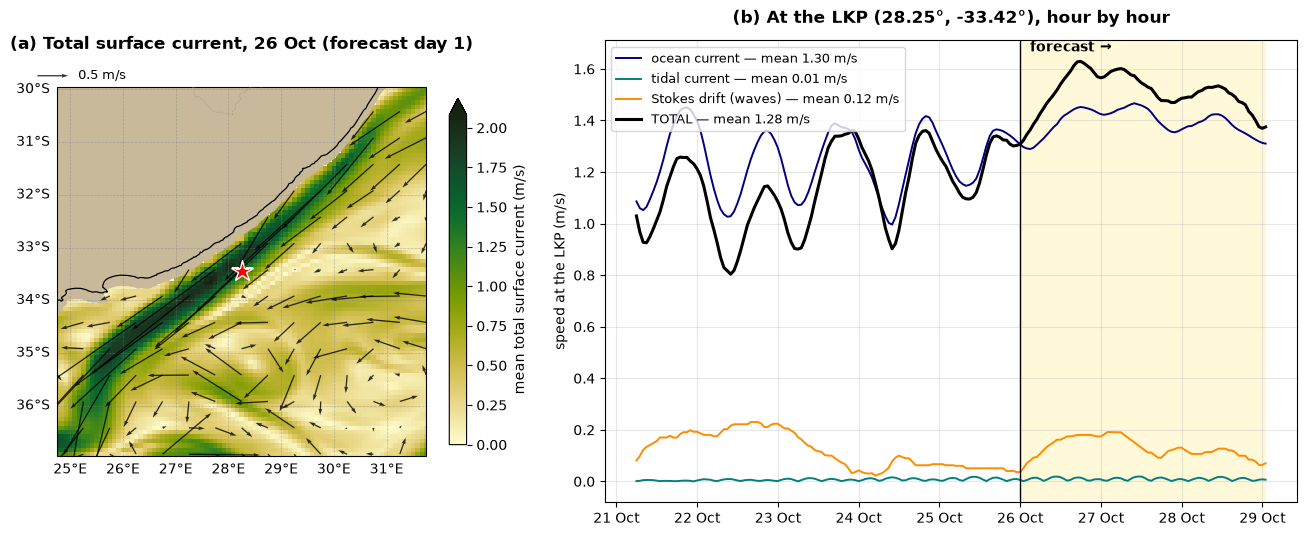

   Mean speed at the LKP: ocean current 1.30 m/s · tidal current 0.01 m/s · Stokes drift (waves) 0.12 m/s · TOTAL 1.28 m/s


In [54]:
# ============================================================
# STEP 4.2 — WHAT MOVES A DRIFTING OBJECT IN YOUR REGION?
# ─────────────────────────────────────────────────────────────
# (a) the total surface current on the first forecast day (arrows)
# (b) at the LKP, hour by hour: ocean current, tides, waves (Stokes)
#     and their sum. Which one dominates in your region?
# ============================================================

day1 = smoc.sel(time=slice(FC_T0, FC_T0 + pd.Timedelta(hours=23))).mean('time')
klon, klat = nearest_ocean(day1['utotal'], LKP_LON, LKP_LAT)
pt = smoc.sel(longitude=klon, latitude=klat)
comp = {'ocean current':      (np.hypot(pt.uo, pt.vo),         'navy'),
        'tidal current':      (np.hypot(pt.utide, pt.vtide),   'teal'),
        'Stokes drift (waves)': (np.hypot(pt.vsdx, pt.vsdy),   'darkorange'),
        'TOTAL':              (np.hypot(pt.utotal, pt.vtotal), 'black')}

fig = plt.figure(figsize=(16, 6))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.5], wspace=0.15)
ax = fig.add_subplot(gs[0], projection=PC)
np.hypot(day1.utotal, day1.vtotal).plot(ax=ax, transform=PC, cmap=cmocean.cm.speed, vmin=0, extend='max', add_labels=False,
                                        cbar_kwargs={'label': 'mean total surface current (m/s)', 'shrink': 0.75})
arrows(ax, day1.utotal, day1.vtotal, n_across=14, scale=6, key=0.5, key_label='0.5 m/s', key_xy=(0.03, 1.03))
ax.plot(LKP_LON, LKP_LAT, 'r*', ms=16, mec='white', transform=PC, zorder=6)
decorate(ax, extent=[SAR_BOX['minimum_longitude'], SAR_BOX['maximum_longitude'], SAR_BOX['minimum_latitude'], SAR_BOX['maximum_latitude']])
ax.set_title(f'(a) Total surface current, {FC_T0:%d %b} (forecast day 1)', pad=22)

ax = fig.add_subplot(gs[1])
for name, (s, c) in comp.items():
    ax.plot(s.time, s, color=c, lw=2.2 if name == 'TOTAL' else 1.4, label=f'{name} — mean {float(s.mean()):.2f} m/s')
ax.axvspan(FC_T0, pd.Timestamp(smoc.time.values[-1]), color='gold', alpha=0.15, lw=0)
ax.axvline(FC_T0, color='k', lw=1); ax.text(FC_T0, ax.get_ylim()[1], '  forecast →', va='top', fontweight='bold')
ax.set_ylabel('speed at the LKP (m/s)'); ax.grid(alpha=0.3); ax.legend(fontsize=9, loc='upper left')
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.DayLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.set_title(f'(b) At the LKP ({klon:.2f}°, {klat:.2f}°), hour by hour')
save_fig(fig, f'Day3_SAR_currents_{FILE_PREFIX}_{STAMP}.png')
plt.show()

share = {k: float(v[0].mean()) for k, v in comp.items()}
print('   Mean speed at the LKP: ' + ' · '.join(f'{k} {x:.2f} m/s' for k, x in share.items()))

### 🔎 Reading the drift ingredients

- The **tidal current** turns or reverses every ~12 h 25 min: it moves an object back and forth more than it carries it away, but it
  matters a lot in the first hours and on wide shelves.
- The **Stokes drift** is small (a few cm/s) but **always in the direction the waves travel**: over two days it adds kilometres.
- The **ocean current** usually sets where the object ends up after a few days — in the Agulhas it can carry it 100 km a day.
- **Leeway** is not in this figure: it depends on the **object** (a person barely emerges; a raft catches the wind like a sail).

<div style="border-left:6px solid #E97132; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#E97132">✍️ Your turn (3 min)</b><br>In your region, which ingredient dominates at the LKP? Would you ever be allowed to ignore the tides? The waves?</div>

In [55]:
# ============================================================
# STEP 4.3 — THE DRIFT MODEL  (read it, then run it)
# ─────────────────────────────────────────────────────────────
# A small Lagrangian model: particles are moved by a velocity field
# interpolated in space and time (4th-order Runge-Kutta, 30 min steps),
# plus a random walk (diffusion K_DIFF). A particle that meets land
# (no current) is "on the coast"; one that leaves the loaded area is
# "outside". Positions are kept every hour.
# ============================================================

from scipy.interpolate import RegularGridInterpolator
from scipy.spatial import ConvexHull
M_PER_DEG = 111_195.0
T_REF = pd.Timestamp('2000-01-01')
hours_since = lambda t: (pd.to_datetime(t) - T_REF) / pd.Timedelta(hours=1)


def field(u, v):
    """Interpolators for a velocity field (time, latitude, longitude) in m/s."""
    axes = (np.asarray(hours_since(u.time.values), float), u.latitude.values, u.longitude.values)
    mk = lambda a: RegularGridInterpolator(axes, np.asarray(a.transpose('time', 'latitude', 'longitude').values, float),
                                           bounds_error=False, fill_value=np.nan)
    return mk(u), mk(v)


def drift(fields, lon0, lat0, start, hours, n=None, radius_km=None, K=None, dt_min=30, seed=1, box=None):
    """Release n particles around (lon0, lat0) at `start`, move them for `hours`.
    fields: list of (fu, fv, factor) added together, e.g. [(cur_u, cur_v, 1), (wind_u, wind_v, 0.011)].
    Returns a Dataset (time, particle) with lon, lat and status (0 adrift, 1 on the coast, 2 outside)."""
    n, radius_km, K = n or N_PART, radius_km or RADIUS_KM, K if K is not None else K_DIFF
    rng = np.random.default_rng(seed)
    r = radius_km * 1000 * np.sqrt(rng.random(n)); a = 2 * np.pi * rng.random(n)
    lat = lat0 + r * np.sin(a) / M_PER_DEG
    lon = lon0 + r * np.cos(a) / (M_PER_DEG * np.cos(np.deg2rad(lat0)))
    status = np.zeros(n, int)
    box = box or SAR_BOX
    dt = dt_min * 60.0
    t = float(hours_since(start))
    out_t, out_lon, out_lat, out_st = [pd.Timestamp(start)], [lon.copy()], [lat.copy()], [status.copy()]

    def vel(tt, x, y):
        uu, vv = np.zeros_like(x), np.zeros_like(x)
        pts = np.column_stack([np.full_like(x, tt), y, x])
        for i, (fu, fv, k) in enumerate(fields):
            fu_, fv_ = fu(pts), fv(pts)
            if i > 0:                                  # wind: a gap in the data means no leeway, not a coast
                fu_, fv_ = np.nan_to_num(fu_), np.nan_to_num(fv_)
            uu = uu + k * fu_; vv = vv + k * fv_
        return uu, vv

    to_deg = lambda u, v, y: (u / (M_PER_DEG * np.cos(np.deg2rad(y))), v / M_PER_DEG)
    for step in range(int(hours * 60 / dt_min)):
        act = status == 0
        x, y = lon[act], lat[act]
        u1, v1 = vel(t, x, y);                       dx1, dy1 = to_deg(u1, v1, y)
        u2, v2 = vel(t + dt / 7200, x + dx1 * dt / 2, y + dy1 * dt / 2); dx2, dy2 = to_deg(u2, v2, y)
        u3, v3 = vel(t + dt / 7200, x + dx2 * dt / 2, y + dy2 * dt / 2); dx3, dy3 = to_deg(u3, v3, y)
        u4, v4 = vel(t + dt / 3600, x + dx3 * dt, y + dy3 * dt);         dx4, dy4 = to_deg(u4, v4, y)
        nx = x + dt * (dx1 + 2 * dx2 + 2 * dx3 + dx4) / 6
        ny = y + dt * (dy1 + 2 * dy2 + 2 * dy3 + dy4) / 6
        sig = np.sqrt(2 * K * dt)                                   # random walk (m)
        ny = ny + sig * rng.standard_normal(len(x)) / M_PER_DEG
        nx = nx + sig * rng.standard_normal(len(x)) / (M_PER_DEG * np.cos(np.deg2rad(y)))
        t += dt / 3600
        uu = fields[0][0](np.column_stack([np.full_like(nx, t), ny, nx]))   # the coast = where the CURRENT is missing
        outside = (nx < box['minimum_longitude']) | (nx > box['maximum_longitude']) | \
                  (ny < box['minimum_latitude']) | (ny > box['maximum_latitude'])
        coast = ~np.isfinite(uu) & ~outside
        moving = ~coast & ~outside
        idx = np.where(act)[0]
        lon[idx[moving]], lat[idx[moving]] = nx[moving], ny[moving]
        status[idx[coast]], status[idx[outside]] = 1, 2
        if (step + 1) * dt_min % 60 == 0:
            out_t.append(pd.Timestamp(start) + pd.Timedelta(minutes=(step + 1) * dt_min))
            out_lon.append(lon.copy()); out_lat.append(lat.copy()); out_st.append(status.copy())
    return xr.Dataset({'lon': (('time', 'particle'), np.array(out_lon)), 'lat': (('time', 'particle'), np.array(out_lat)),
                       'status': (('time', 'particle'), np.array(out_st))}, coords={'time': out_t})


def km_xy(lon, lat, lon0, lat0):
    return (np.asarray(lon) - lon0) * M_PER_DEG / 1000 * np.cos(np.deg2rad(lat0)), (np.asarray(lat) - lat0) * M_PER_DEG / 1000


def cloud_stats(d, hour):
    """Search-area numbers for one simulation, `hour` hours after the release."""
    s = d.isel(time=min(hour, d.sizes['time'] - 1))
    lon, lat, st = s.lon.values, s.lat.values, s.status.values
    x, y = km_xy(lon, lat, LKP_LON, LKP_LAT)
    cx, cy = x.mean(), y.mean()
    try:
        area = ConvexHull(np.column_stack([x, y])).volume
    except Exception:
        area = 0.0
    q = lambda a: np.percentile(a, [5, 95])
    return dict(hours=hour, centre_lon=lon.mean(), centre_lat=lat.mean(), distance_km=np.hypot(cx, cy),
                bearing_deg=(np.degrees(np.arctan2(cx, cy)) + 360) % 360, area_km2=area,
                lon_5=q(lon)[0], lon_95=q(lon)[1], lat_5=q(lat)[0], lat_95=q(lat)[1],
                on_coast_pct=100 * (st == 1).mean(), outside_pct=100 * (st == 2).mean())


def hull(ax, lon, lat, **kw):
    pts = np.column_stack([lon, lat])
    if len(pts) >= 3:
        h = ConvexHull(pts); v = np.r_[h.vertices, h.vertices[0]]
        ax.plot(pts[v, 0], pts[v, 1], transform=PC, **kw)


CUR_OCEAN = field(smoc['uo'], smoc['vo'])
CUR_TOTAL = field(smoc['utotal'], smoc['vtotal'])
WIND_F = field(wind['u10'], wind['v10']) if wind is not None else None
print('==> Drift model ready: drift(), cloud_stats(), hull()')
print(f'   Object: {OBJECTS[OBJECT][0]} (leeway {100 * OBJECTS[OBJECT][1]:.1f} % of the wind) · '
      f'{N_PART} particles · LKP uncertainty {RADIUS_KM} km · diffusion {K_DIFF} m²/s')

==> Drift model ready: drift(), cloud_stats(), hull()
   Object: Person in the water (leeway 1.1 % of the wind) · 500 particles · LKP uncertainty 1.0 km · diffusion 10.0 m²/s


==> Saved: ~/OPERA_Workshop/Day3/output/Day3_SAR_replay_AGU_20261026.png


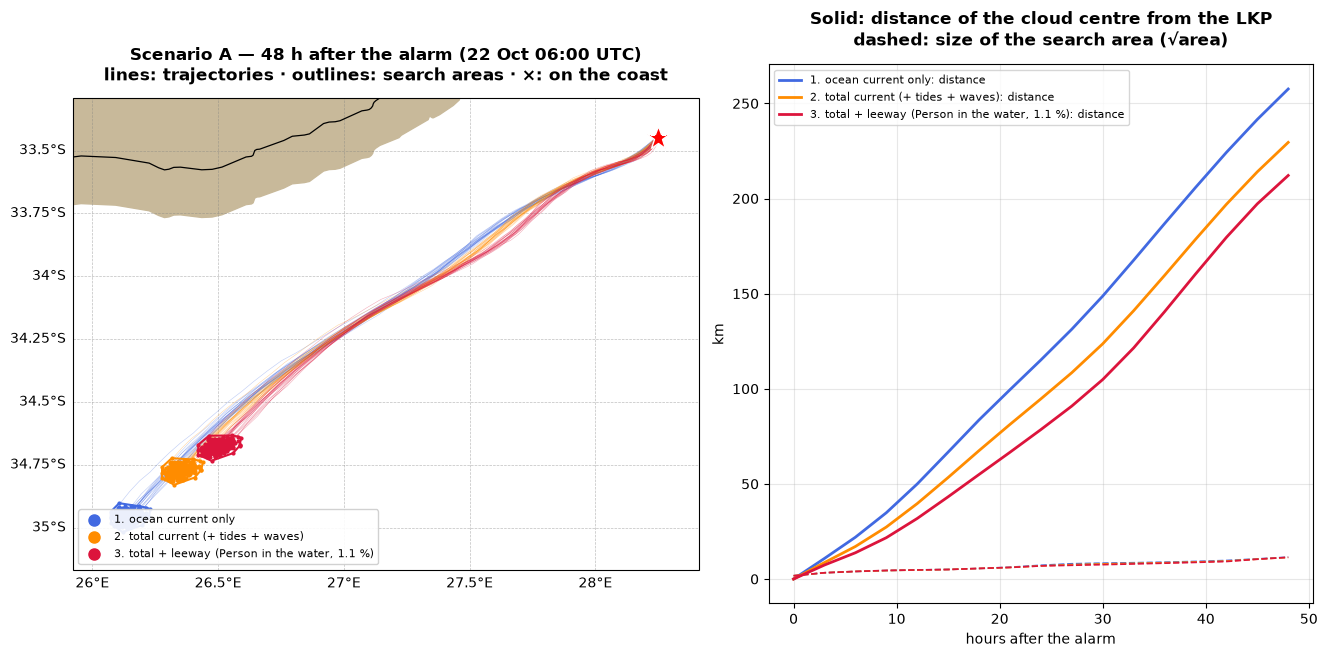

,distance (km),towards (° from N),search area (km²),on the coast (%),left the area (%)
drift,,,,,
1. ocean current only,258.0,229.0,132.0,0.0,0.0
2. total current (+ tides + waves),230.0,230.0,128.0,0.0,0.0
"3. total + leeway (Person in the water, 1.1 %)",212.0,230.0,130.0,0.0,0.0


   After 48 h, "2. total current (+ tides + waves)" is 28 km from "ocean current only".
   After 48 h, "3. total + leeway (Person in the water, 1.1 %)" is 45 km from "ocean current only".


In [56]:
# ============================================================
# STEP 4.4 — SCENARIO A: REPLAY A CASE FROM 3 DAYS AGO (48 h)
# ─────────────────────────────────────────────────────────────
# Same LKP, same particles, three versions of the drift:
#   1. ocean current only            (what a "classic" model gives)
#   2. total surface current         (+ tides + waves)
#   3. total current + leeway (wind) (the full drift of the object)
# The past days are ANALYSES: the best estimate of what happened.
# ============================================================

name, leeway = OBJECTS[OBJECT]
runs = {'1. ocean current only': ([(*CUR_OCEAN, 1)], 'royalblue'),
        '2. total current (+ tides + waves)': ([(*CUR_TOTAL, 1)], 'darkorange')}
if WIND_F is not None:
    runs[f'3. total + leeway ({name}, {100 * leeway:.1f} %)'] = ([(*CUR_TOTAL, 1), (*WIND_F, leeway)], 'crimson')

replay = {k: drift(f, LKP_LON, LKP_LAT, REPLAY_T0, REPLAY_H) for k, (f, c) in runs.items()}

fig = plt.figure(figsize=(16, 7))
gs = fig.add_gridspec(1, 2, width_ratios=[1.15, 1], wspace=0.12)
ax = fig.add_subplot(gs[0], projection=PC)
allx = np.concatenate([d.lon.values.ravel() for d in replay.values()]); ally = np.concatenate([d.lat.values.ravel() for d in replay.values()])
pad = 0.15
ext = [np.nanmin(allx) - pad, np.nanmax(allx) + pad, np.nanmin(ally) - pad, np.nanmax(ally) + pad]
for k, d in replay.items():
    c = runs[k][1]
    for p in range(0, N_PART, 25):                                  # a few trajectories
        ax.plot(d.lon[:, p], d.lat[:, p], color=c, lw=0.4, alpha=0.35, transform=PC, zorder=3)
    end = d.isel(time=-1)
    ax.scatter(end.lon, end.lat, s=4, color=c, transform=PC, zorder=4, label=k)
    hull(ax, end.lon.values, end.lat.values, color=c, lw=1.5, zorder=5)
    hit = end.status == 1
    ax.scatter(end.lon[hit], end.lat[hit], s=18, marker='x', color='k', transform=PC, zorder=6)
ax.plot(LKP_LON, LKP_LAT, 'r*', ms=17, mec='white', transform=PC, zorder=7)
decorate(ax, extent=ext)
ax.legend(loc='lower left', fontsize=8, markerscale=4, framealpha=0.9)
ax.set_title(f'Scenario A — {REPLAY_H} h after the alarm ({REPLAY_T0:%d %b %H:%M} UTC)\nlines: trajectories · outlines: search areas · ×: on the coast')

stats = pd.DataFrame([{'drift': k, **cloud_stats(d, REPLAY_H)} for k, d in replay.items()]).set_index('drift')
ax = fig.add_subplot(gs[1])
for k, d in replay.items():
    h = [cloud_stats(d, hh) for hh in range(0, REPLAY_H + 1, 3)]
    ax.plot([x['hours'] for x in h], [x['distance_km'] for x in h], '-', color=runs[k][1], lw=2, label=f'{k}: distance')
    ax.plot([x['hours'] for x in h], [np.sqrt(x['area_km2']) for x in h], '--', color=runs[k][1], lw=1.2)
ax.set_xlabel('hours after the alarm'); ax.set_ylabel('km'); ax.grid(alpha=0.3)
ax.set_title('Solid: distance of the cloud centre from the LKP\ndashed: size of the search area (√area)')
ax.legend(fontsize=8)
save_fig(fig, f'Day3_SAR_replay_{FILE_PREFIX}_{STAMP}.png')
plt.show()

show_cols = {'distance_km': 'distance (km)', 'bearing_deg': 'towards (° from N)', 'area_km2': 'search area (km²)',
             'on_coast_pct': 'on the coast (%)', 'outside_pct': 'left the area (%)'}
display(stats[list(show_cols)].rename(columns=show_cols).round(0))
names = list(replay)
for k in names[1:]:
    a, b = stats.loc[names[0]], stats.loc[k]
    gap = np.hypot(*km_xy(b.centre_lon, b.centre_lat, a.centre_lon, a.centre_lat))
    print(f'   After {REPLAY_H} h, "{k}" is {gap:.0f} km from "ocean current only".')

### 🔎 Reading the replay

- The **distance** between the clouds is the error you would make by ignoring tides, waves or wind. Compare it with the size of the
  search area: if the clouds do not overlap, the "simple" search would look in the wrong place.
- The **search area grows** with time even if the currents were perfect: the LKP is uncertain, and the model cannot resolve every eddy
  (the random walk). Every hour lost makes the area to search larger — which is why time matters so much in SAR.
- Change `OBJECT` in Step 4.1 to `'raft'` and re-run Steps 4.3–4.4: a raft catches the wind and drifts differently from a person.

<div style="border-left:6px solid #E97132; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#E97132">✍️ Your turn (5 min)</b><br>1. After 48 h, how far apart are the "ocean only" and "full" drifts? Is that more or less than the size of the search area?<br>2. How many particles reached the coast, and where? Who should be warned?</div>

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_SAR_forecast_AGU_20261026.png


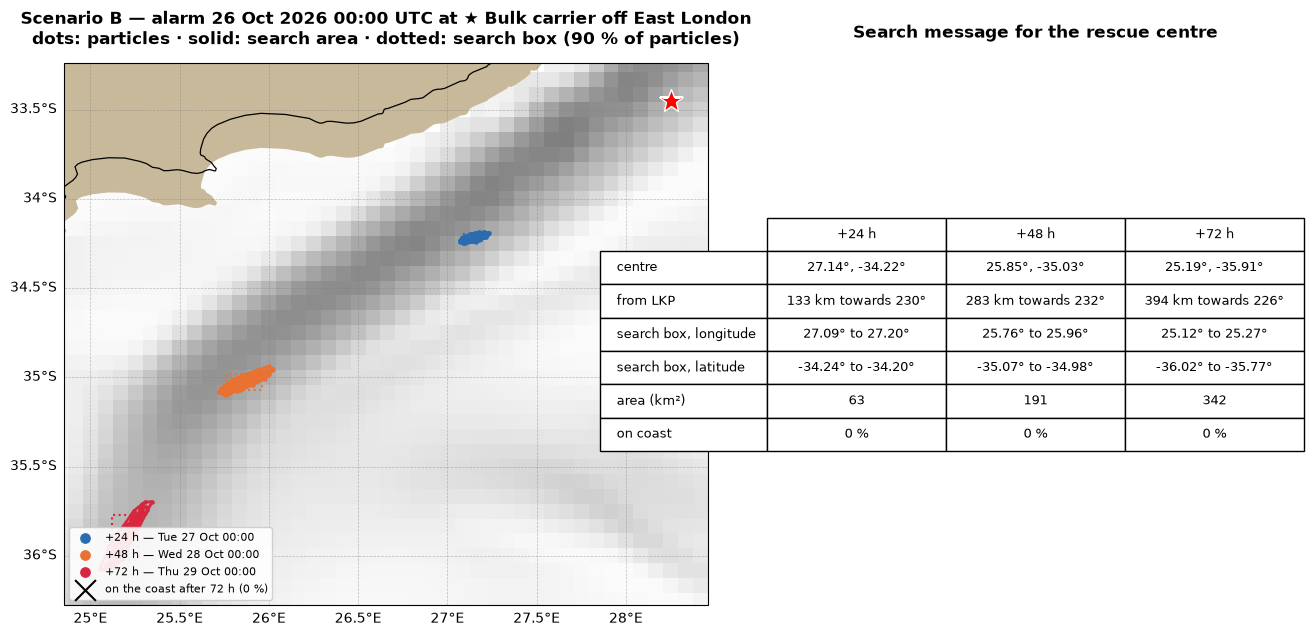

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_SAR_search_areas_AGU_20261026.csv


In [57]:
# ============================================================
# STEP 4.5 — SCENARIO B: TODAY'S ALARM — THE SEARCH AREA FOR 72 h
# ─────────────────────────────────────────────────────────────
# The LKP is reported now. With the FORECAST total surface current:
# where is the object likely to be in 24, 48 and 72 hours?
# (No wind here: the leeway needs a weather forecast — see the note.)
# ============================================================

hours_fc = int(min(FC_H, (pd.Timestamp(smoc.time.values[-1]) - FC_T0) / pd.Timedelta(hours=1)))
sar_fc = drift([(*CUR_TOTAL, 1)], LKP_LON, LKP_LAT, FC_T0, hours_fc, seed=7)
STEPS = [h for h in (24, 48, 72) if h <= hours_fc]
COLS = {24: '#2B6CB0', 48: '#E97132', 72: '#D7263D'}

fig = plt.figure(figsize=(16, 7.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1.2, 1], wspace=0.10)
ax = fig.add_subplot(gs[0], projection=PC)
x, y = sar_fc.lon.values.ravel(), sar_fc.lat.values.ravel()
ext = [np.nanmin(x) - 0.2, np.nanmax(x) + 0.2, np.nanmin(y) - 0.2, np.nanmax(y) + 0.2]
sp = np.hypot(smoc.utotal, smoc.vtotal).sel(time=slice(FC_T0, FC_T0 + pd.Timedelta(hours=hours_fc))).mean('time')
sp.plot(ax=ax, transform=PC, cmap='Greys', vmin=0, alpha=0.5, add_colorbar=False, add_labels=False)
rows = []
for h in STEPS:
    s = sar_fc.isel(time=h)
    ax.scatter(s.lon, s.lat, s=5, color=COLS[h], transform=PC, zorder=4, label=f'+{h} h — {FC_T0 + pd.Timedelta(hours=h):%a %d %b %H:%M}')
    hull(ax, s.lon.values, s.lat.values, color=COLS[h], lw=2, zorder=5)
    st = cloud_stats(sar_fc, h); rows.append(st)
    ax.add_patch(mpatches.Rectangle((st['lon_5'], st['lat_5']), st['lon_95'] - st['lon_5'], st['lat_95'] - st['lat_5'],
                                    fill=False, ec=COLS[h], ls=':', lw=1.5, transform=PC, zorder=5))
hit = sar_fc.status.isel(time=-1) == 1
ax.scatter(sar_fc.lon.isel(time=-1)[hit], sar_fc.lat.isel(time=-1)[hit], s=25, marker='x', color='k', transform=PC, zorder=6,
           label=f'on the coast after {hours_fc} h ({100 * float(hit.mean()):.0f} %)')
ax.plot(LKP_LON, LKP_LAT, 'r*', ms=18, mec='white', transform=PC, zorder=7)
decorate(ax, extent=ext)
ax.legend(loc='lower left', fontsize=8, markerscale=3, framealpha=0.9)
ax.set_title(f'Scenario B — alarm {FC_T0:%d %b %Y} 00:00 UTC at ★ {LKP_NAME}\n'
             'dots: particles · solid: search area · dotted: search box (90 % of particles)')

ax = fig.add_subplot(gs[1])
ax.axis('off')
SEARCH = pd.DataFrame(rows).set_index('hours')
tbl = SEARCH.assign(**{'search box, longitude': [f'{a:.2f}° to {b:.2f}°' for a, b in zip(SEARCH.lon_5, SEARCH.lon_95)],
                       'search box, latitude':  [f'{a:.2f}° to {b:.2f}°' for a, b in zip(SEARCH.lat_5, SEARCH.lat_95)],
                       'centre':                [f'{a:.2f}°, {b:.2f}°' for a, b in zip(SEARCH.centre_lon, SEARCH.centre_lat)],
                       'from LKP':              [f'{d:.0f} km towards {b:.0f}°' for d, b in zip(SEARCH.distance_km, SEARCH.bearing_deg)],
                       'area (km²)':            SEARCH.area_km2.round(0).astype(int),
                       'on coast':              [f'{c:.0f} %' for c in SEARCH.on_coast_pct]})
cols = ['centre', 'from LKP', 'search box, longitude', 'search box, latitude', 'area (km²)', 'on coast']
t = ax.table(cellText=tbl[cols].T.values, rowLabels=cols, colLabels=[f'+{h} h' for h in tbl.index],
             loc='center', cellLoc='center')
t.auto_set_font_size(False); t.set_fontsize(9.5); t.scale(1, 2.0)
ax.set_title('Search message for the rescue centre', fontweight='bold')
save_fig(fig, f'Day3_SAR_forecast_{FILE_PREFIX}_{STAMP}.png')
plt.show()

path = OUTPUT_DIR / f'Day3_SAR_search_areas_{FILE_PREFIX}_{STAMP}.csv'
SEARCH.round(3).to_csv(path); print(f'==> Saved: ~/{path.relative_to(Path.home())}')

<div style="border-left:6px solid #1A54EB; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#1A54EB">Why no wind in the forecast?</b><br>The leeway needs a <b>wind forecast</b>, which comes from a weather centre (ECMWF, NOAA GFS, your national meteorological service), not from Copernicus Marine. Real SAR systems combine both. Today, Scenario A showed you how much the wind changes the drift for your object: keep that in mind when you read the forecast search area — and say it in your message.</div>

### 🔎 Reading the search area

- The **search box** (dotted) contains 90 % of the particles: it is what a rescue centre needs to plan aircraft and boat tracks.
- The area grows with time: at +72 h it is often **too large to search**. A drift forecast is most valuable in the **first 24–48 h**.
- Particles on the **coast** (×) say where survivors or wreckage may come ashore — a message for coastal communities and the police.
- The forecast currents have errors (Section 3). This is why rescue centres **re-run** the drift every few hours, with every new
  sighting and every new forecast.

<div style="border-left:6px solid #E97132; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#E97132">✍️ Your turn (10 min) — your message to the rescue centre</b><br><i>“Object: … LKP … at … UTC. Search first within … (box) in the next 24 h; the object drifts … km/day towards … . After 48 h the area exceeds … km². … % may reach the coast near … . Confidence: …”</i>. It goes into your bulletin.</div>

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_SAR_buoy_check_AGU_20261026.png


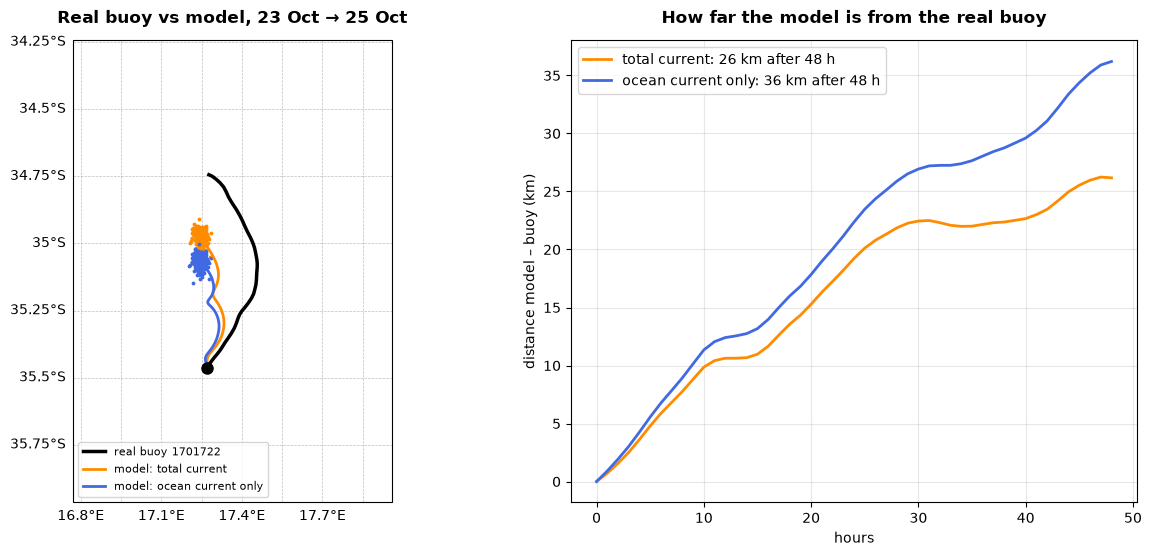

   Note: most drifting buoys carry a drogue (an underwater sail) at ~15 m: they follow the current a little below the surface,
   less pushed by wind and waves than a person or a raft.


In [73]:
# ============================================================
# STEP 4.6 — CHECK THE MODEL WITH A REAL DRIFTING BUOY (if any)
# ─────────────────────────────────────────────────────────────
# Drifting buoys (platform code DB) report their position every
# hour or so. Release virtual particles where a real buoy was, and
# compare where they go with where the buoy really went.
# Uses the in situ data read in Step 3.2.
# ============================================================

DRIFT_DAYS = 3
# BUOY_END   = str(REPLAY_T0 + pd.Timedelta(hours=REPLAY_H))   # the buoy's drift ends when the replay ends
# DRIFT_DAYS = 2                                              # the replay lasts 48 h
track = None
if 'ins' in globals() and insitu_ok:
    db = ins[ins[PTYPE].astype(str) == 'DB'].copy()
    if len(db):
        db['t'] = pd.to_datetime(db['time'], utc=True).dt.tz_localize(None)
        best = None
        for pid, g in db.groupby('platform_id'):
            g = g.drop_duplicates('t').sort_values('t').set_index('t')[['longitude', 'latitude']]
            g = g[g.index <= TODAY - pd.Timedelta(hours=1)]
            if len(g) and (g.index[-1] - g.index[0]) >= pd.Timedelta(days=DRIFT_DAYS):
                best = (pid, g) if best is None or len(g) > len(best[1]) else best
        if best:
            pid, g = best
            t0_ = g.index[-1] - pd.Timedelta(days=DRIFT_DAYS)
            track = g[g.index >= t0_].resample('1h').mean().interpolate(limit=6).dropna()
if track is None or len(track) < 24:
    print('No drifting buoy with 3 days of positions in your area in the last 30 days — nothing to compare. '
          'Go on to Section 5 (this step is optional).')
else:
    b0 = track.iloc[0]
    vbox = dict(minimum_longitude=float(track.longitude.min()) - 1.5, maximum_longitude=float(track.longitude.max()) + 1.5,
                minimum_latitude=float(track.latitude.min()) - 1.5, maximum_latitude=float(track.latitude.max()) + 1.5)
    sm = stream('TOTAL_CUR', track.index[0] - pd.Timedelta(hours=2), track.index[-1] + pd.Timedelta(hours=2), box=vbox,
                variables=['utotal', 'vtotal', 'uo', 'vo'])
    sm = (sm.isel(depth=0) if 'depth' in sm.dims else sm).compute()
    hrs = int((track.index[-1] - track.index[0]) / pd.Timedelta(hours=1))
    sims = {'total current': (drift([(*field(sm.utotal, sm.vtotal), 1)], b0.longitude, b0.latitude, track.index[0], hrs,
                                    radius_km=0.1, box=vbox, n=200), 'darkorange'),
            'ocean current only': (drift([(*field(sm.uo, sm.vo), 1)], b0.longitude, b0.latitude, track.index[0], hrs,
                                         radius_km=0.1, box=vbox, n=200), 'royalblue')}
    fig = plt.figure(figsize=(15, 6))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.1], wspace=0.15)
    ax = fig.add_subplot(gs[0], projection=PC)
    ax.plot(track.longitude, track.latitude, 'k-', lw=2.5, transform=PC, zorder=6, label=f'real buoy {pid}')
    ax.plot(b0.longitude, b0.latitude, 'ko', ms=8, transform=PC, zorder=7)
    for k, (d, c) in sims.items():
        ax.plot(d.lon.mean('particle'), d.lat.mean('particle'), '-', color=c, lw=2, transform=PC, zorder=5, label=f'model: {k}')
        e = d.isel(time=-1); ax.scatter(e.lon, e.lat, s=3, color=c, transform=PC, zorder=4)
    decorate(ax, extent=[vbox['minimum_longitude'] + 1, vbox['maximum_longitude'] - 1, vbox['minimum_latitude'] + 1, vbox['maximum_latitude'] - 1])
    ax.legend(fontsize=8, loc='lower left'); ax.set_title(f'Real buoy vs model, {track.index[0]:%d %b} → {track.index[-1]:%d %b}')
    ax = fig.add_subplot(gs[1])
    obs_t = track.index
    for k, (d, c) in sims.items():
        mlon = d.lon.mean('particle').to_series().reindex(obs_t, method='nearest')
        mlat = d.lat.mean('particle').to_series().reindex(obs_t, method='nearest')
        sep = np.hypot(*km_xy(mlon.values, mlat.values, track.longitude.values, track.latitude.values))
        ax.plot((obs_t - obs_t[0]) / pd.Timedelta(hours=1), sep, color=c, lw=2, label=f'{k}: {sep[-1]:.0f} km after {hrs} h')
    ax.set_xlabel('hours'); ax.set_ylabel('distance model – buoy (km)'); ax.grid(alpha=0.3); ax.legend()
    ax.set_title('How far the model is from the real buoy')
    save_fig(fig, f'Day3_SAR_buoy_check_{FILE_PREFIX}_{STAMP}.png')
    plt.show()
    print('   Note: most drifting buoys carry a drogue (an underwater sail) at ~15 m: they follow the current a little below the surface,\n'
          '   less pushed by wind and waves than a person or a raft.')

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_SAR_buoy_check_AGU_20261026.png


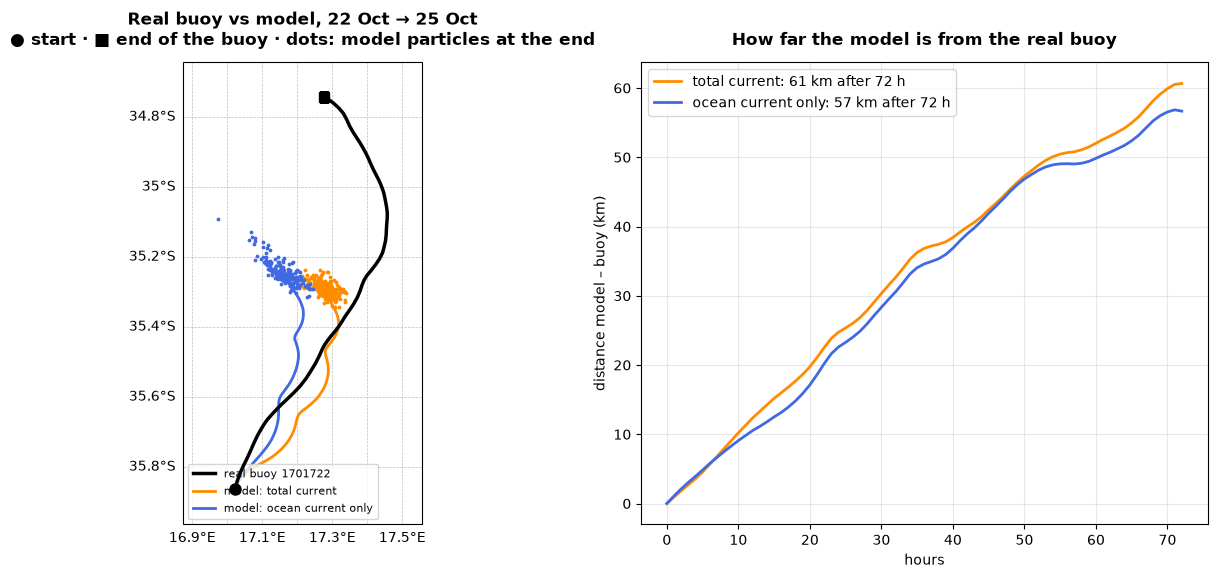

   Note: most drifting buoys carry a drogue (an underwater sail) at ~15 m: they follow the current a little below the surface,
   less pushed by wind and waves than a person or a raft.


In [59]:
# ============================================================
# STEP 4.6 — CHECK THE MODEL WITH A REAL DRIFTING BUOY (if any)
# ─────────────────────────────────────────────────────────────
# Drifting buoys (platform code DB) report their position every
# hour or so. Release virtual particles where a real buoy was, and
# compare where they go with where the buoy really went.
# Uses the in situ data read in Step 3.2.
# ============================================================

DRIFT_DAYS = 3
track = None
if 'ins' in globals() and insitu_ok:
    db = ins[ins[PTYPE].astype(str) == 'DB'].copy()
    if len(db):
        db['t'] = pd.to_datetime(db['time'], utc=True).dt.tz_localize(None)
        best = None
        for pid, g in db.groupby('platform_id'):
            g = g.drop_duplicates('t').sort_values('t').set_index('t')[['longitude', 'latitude']]
            g = g[g.index <= TODAY - pd.Timedelta(hours=1)]
            if len(g) and (g.index[-1] - g.index[0]) >= pd.Timedelta(days=DRIFT_DAYS):
                best = (pid, g) if best is None or len(g) > len(best[1]) else best
        if best:
            pid, g = best
            t0_ = g.index[-1] - pd.Timedelta(days=DRIFT_DAYS)
            track = g[g.index >= t0_].resample('1h').mean().interpolate(limit=6).dropna()
if track is None or len(track) < 24:
    print('No drifting buoy with 3 days of positions in your area in the last 30 days — nothing to compare. '
          'Go on to Section 5 (this step is optional).')
else:
    b0 = track.iloc[0]
    vbox = dict(minimum_longitude=float(track.longitude.min()) - 1.5, maximum_longitude=float(track.longitude.max()) + 1.5,
                minimum_latitude=float(track.latitude.min()) - 1.5, maximum_latitude=float(track.latitude.max()) + 1.5)
    sm = stream('TOTAL_CUR', track.index[0] - pd.Timedelta(hours=2), track.index[-1] + pd.Timedelta(hours=2), box=vbox,
                variables=['utotal', 'vtotal', 'uo', 'vo'])
    sm = (sm.isel(depth=0) if 'depth' in sm.dims else sm).compute()
    hrs = int((track.index[-1] - track.index[0]) / pd.Timedelta(hours=1))
    sims = {'total current': (drift([(*field(sm.utotal, sm.vtotal), 1)], b0.longitude, b0.latitude, track.index[0], hrs,
                                    radius_km=0.1, box=vbox, n=200), 'darkorange'),
            'ocean current only': (drift([(*field(sm.uo, sm.vo), 1)], b0.longitude, b0.latitude, track.index[0], hrs,
                                         radius_km=0.1, box=vbox, n=200), 'royalblue')}
    fig = plt.figure(figsize=(15, 6))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.1], wspace=0.15)
    ax = fig.add_subplot(gs[0], projection=PC)
    ax.plot(track.longitude, track.latitude, 'k-', lw=2.5, transform=PC, zorder=6, label=f'real buoy {pid}')
    ax.plot(b0.longitude, b0.latitude, 'ko', ms=8, transform=PC, zorder=7)
    for k, (d, c) in sims.items():
        ax.plot(d.lon.mean('particle'), d.lat.mean('particle'), '-', color=c, lw=2, transform=PC, zorder=5, label=f'model: {k}')
        e = d.isel(time=-1); ax.scatter(e.lon, e.lat, s=3, color=c, transform=PC, zorder=4)
    ax.plot(track.longitude.iloc[-1], track.latitude.iloc[-1], 'ks', ms=7, transform=PC, zorder=7)   # where the buoy ended
    xs = np.r_[track.longitude.values, *[d.lon.values.ravel() for d, c in sims.values()]]
    ys = np.r_[track.latitude.values, *[d.lat.values.ravel() for d, c in sims.values()]]
    decorate(ax, extent=[np.nanmin(xs) - 0.1, np.nanmax(xs) + 0.1, np.nanmin(ys) - 0.1, np.nanmax(ys) + 0.1])   # zoom on the drift
    ax.legend(fontsize=8, loc='lower left'); ax.set_title(f'Real buoy vs model, {track.index[0]:%d %b} → {track.index[-1]:%d %b}\n● start · ■ end of the buoy · dots: model particles at the end')
    ax = fig.add_subplot(gs[1])
    obs_t = track.index
    for k, (d, c) in sims.items():
        mlon = d.lon.mean('particle').to_series().reindex(obs_t, method='nearest')
        mlat = d.lat.mean('particle').to_series().reindex(obs_t, method='nearest')
        sep = np.hypot(*km_xy(mlon.values, mlat.values, track.longitude.values, track.latitude.values))
        ax.plot((obs_t - obs_t[0]) / pd.Timedelta(hours=1), sep, color=c, lw=2, label=f'{k}: {sep[-1]:.0f} km after {hrs} h')
    ax.set_xlabel('hours'); ax.set_ylabel('distance model – buoy (km)'); ax.grid(alpha=0.3); ax.legend()
    ax.set_title('How far the model is from the real buoy')
    save_fig(fig, f'Day3_SAR_buoy_check_{FILE_PREFIX}_{STAMP}.png')
    plt.show()
    print('   Note: most drifting buoys carry a drogue (an underwater sail) at ~15 m: they follow the current a little below the surface,\n'
          '   less pushed by wind and waves than a person or a raft.')

<details><summary><b>Optional, for the curious — the same drift with OpenDrift</b> (click to open)</summary>

[OpenDrift](https://opendrift.github.io) is the open-source drift framework of the Norwegian Meteorological Institute, used operationally
for search and rescue and oil spills (and in the GGOSSS plastics study of the Cameroon coast). It is **not** installed on the workshop
hub by default. If your instructor has installed it (`pip install opendrift`), the next cell runs the Scenario B forecast with
OpenDrift's `OceanDrift` model on the same currents, so you can compare the two models. Otherwise it simply says so.
</details>

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_SAR_buoy_OpenDrift_AGU_20261026.png


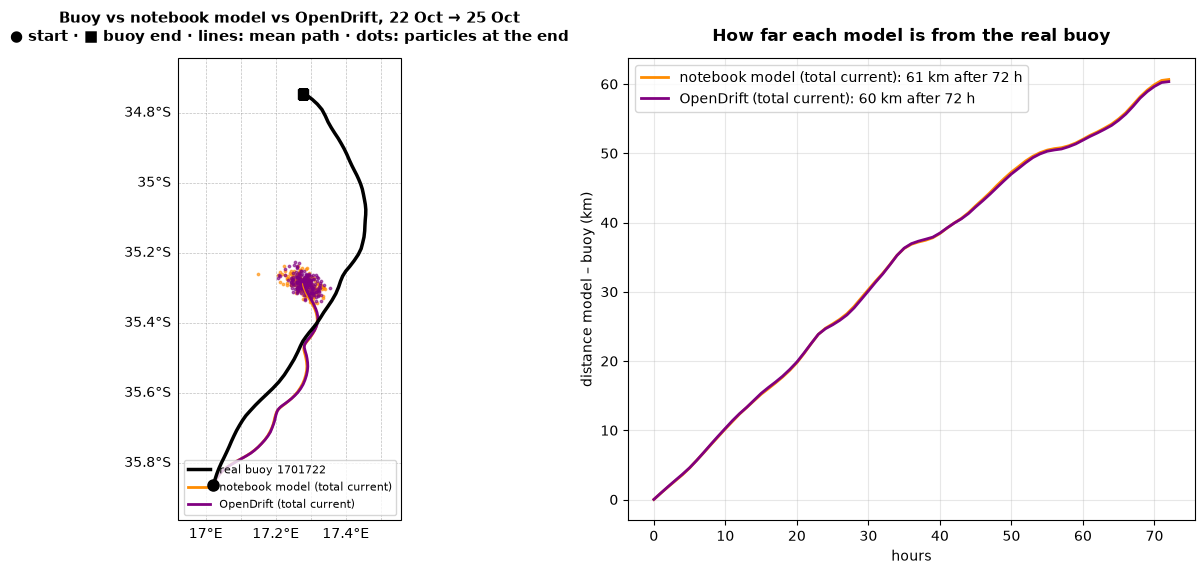

,after 24 h (km),after 48 h (km),after 72 h (km),mean error (km)
notebook model (total current),24.7,45.4,60.7,33.4
OpenDrift (total current),24.7,45.1,60.3,33.3


   Both models use the same currents: if they agree with each other but not with the buoy, the error comes from the
   CURRENTS (or the drogue at ~15 m), not from the drift model.


In [60]:
# ============================================================
# STEP 4.8 — OPTIONAL: REAL BUOY vs YOUR MODEL vs OPENDRIFT
# ─────────────────────────────────────────────────────────────
# The buoy check of Step 4.6, now with three tracks:
#   black  = the real drifting buoy (observations)
#   orange = the notebook model (Step 4.3), total current
#   purple = OpenDrift (OceanDrift), the same total current
# Same start point, same time, same currents.
# Needs Step 4.6 (a buoy was found) and OpenDrift (Step 4.7).
# ============================================================

try:
    from opendrift.models.oceandrift import OceanDrift
    from opendrift.readers import reader_netCDF_CF_generic
    has_od = True
except ImportError:
    has_od = False

if track is None or len(track) < 24:
    print('No drifting buoy was found in Step 4.6 — nothing to compare.')
elif not has_od:
    print('OpenDrift is not installed on this hub — this step is optional. Nothing else depends on it.')
else:
    # ---- OpenDrift on the currents loaded around the buoy in Step 4.6 (sm)
    fb = OUTPUT_DIR / f'SMOC_buoy_{FILE_PREFIX}_{STAMP}.nc'
    cf = sm[['utotal', 'vtotal']].rename(utotal='x_sea_water_velocity', vtotal='y_sea_water_velocity')
    cf['x_sea_water_velocity'].attrs.update(standard_name='x_sea_water_velocity', units='m s-1')
    cf['y_sea_water_velocity'].attrs.update(standard_name='y_sea_water_velocity', units='m s-1')
    cf.drop_vars([c for c in cf.coords if c not in ('time', 'latitude', 'longitude')]).to_netcdf(fb)
    o = OceanDrift(loglevel=50)
    o.add_reader(reader_netCDF_CF_generic.Reader(str(fb)))
    for key in ('drift:horizontal_diffusivity', 'environment:constant:horizontal_diffusivity'):   # name depends on the version
        if key in o.get_configspec():
            o.set_config(key, K_DIFF); break
    o.set_config('general:coastline_action', 'stranding')
    o.seed_elements(lon=b0.longitude, lat=b0.latitude, radius=100, number=200,
                    time=track.index[0].to_pydatetime(), wind_drift_factor=0)
    o.run(duration=pd.Timedelta(hours=hrs).to_pytimedelta(), time_step=1800, time_step_output=3600)
    r = o.result
    od_lon = r.lon.mean('trajectory', skipna=True).to_series()
    od_lat = r.lat.mean('trajectory', skipna=True).to_series()
    od_lon.index, od_lat.index = pd.to_datetime(od_lon.index), pd.to_datetime(od_lat.index)
    fb.unlink(missing_ok=True)

    nb_run = sims['total current'][0]                         # the notebook model, total current (Step 4.6)
    runs3 = {'notebook model (total current)': (nb_run.lon.mean('particle').to_series(), nb_run.lat.mean('particle').to_series(),
                                                nb_run.isel(time=-1).lon.values, nb_run.isel(time=-1).lat.values, 'darkorange'),
             'OpenDrift (total current)':      (od_lon, od_lat,
                                                r.lon.isel(time=-1).values, r.lat.isel(time=-1).values, 'purple')}

    fig = plt.figure(figsize=(15, 6))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.1], wspace=0.15)
    ax = fig.add_subplot(gs[0], projection=PC)
    ax.plot(track.longitude, track.latitude, 'k-', lw=2.5, transform=PC, zorder=6, label=f'real buoy {pid}')
    ax.plot(b0.longitude, b0.latitude, 'ko', ms=8, transform=PC, zorder=7)
    ax.plot(track.longitude.iloc[-1], track.latitude.iloc[-1], 'ks', ms=7, transform=PC, zorder=7)
    xs, ys = [track.longitude.values], [track.latitude.values]
    for k, (mlon, mlat, elon, elat, c) in runs3.items():
        ax.plot(mlon, mlat, '-', color=c, lw=2, transform=PC, zorder=5, label=k)
        ax.scatter(elon, elat, s=3, color=c, alpha=0.6, transform=PC, zorder=4)
        xs += [mlon.values, elon]; ys += [mlat.values, elat]
    xs, ys = np.concatenate(xs), np.concatenate(ys)
    decorate(ax, extent=[np.nanmin(xs) - 0.1, np.nanmax(xs) + 0.1, np.nanmin(ys) - 0.1, np.nanmax(ys) + 0.1])
    ax.legend(fontsize=8, loc='lower left')
    ax.set_title(f'Buoy vs notebook model vs OpenDrift, {track.index[0]:%d %b} → {track.index[-1]:%d %b}\n'
                 '● start · ■ buoy end · lines: mean path · dots: particles at the end', fontsize=11)

    ax = fig.add_subplot(gs[1])
    obs_t = track.index
    table = {}
    for k, (mlon, mlat, elon, elat, c) in runs3.items():
        lo = mlon.reindex(obs_t, method='nearest'); la = mlat.reindex(obs_t, method='nearest')
        sep = np.hypot(*km_xy(lo.values, la.values, track.longitude.values, track.latitude.values))
        ax.plot((obs_t - obs_t[0]) / pd.Timedelta(hours=1), sep, color=c, lw=2, label=f'{k}: {sep[-1]:.0f} km after {hrs} h')
        table[k] = {'after 24 h (km)': sep[min(24, len(sep) - 1)], 'after 48 h (km)': sep[min(48, len(sep) - 1)],
                    f'after {hrs} h (km)': sep[-1], 'mean error (km)': np.nanmean(sep)}
    ax.set_xlabel('hours'); ax.set_ylabel('distance model – buoy (km)'); ax.grid(alpha=0.3); ax.legend()
    ax.set_title('How far each model is from the real buoy')
    save_fig(fig, f'Day3_SAR_buoy_OpenDrift_{FILE_PREFIX}_{STAMP}.png')
    plt.show()
    display(pd.DataFrame(table).T.round(1))
    print('   Both models use the same currents: if they agree with each other but not with the buoy, the error comes from the\n'
          '   CURRENTS (or the drogue at ~15 m), not from the drift model.')

In [61]:
DRIFT_DAYS = 3
BUOY_ID    = None     # <- e.g. '7810806' to choose a buoy from the list below; None = the one with the most positions
BUOY_END   = None     # <- e.g. '2026-10-15' to end the 3 days on that date; None = the buoy's last 3 days
track = None
if 'ins' in globals() and insitu_ok:
    db = ins[ins[PTYPE].astype(str) == 'DB'].copy()
    if len(db):
        db['t'] = pd.to_datetime(db['time'], utc=True).dt.tz_localize(None)
        buoys = {}
        for pid_, g in db.groupby('platform_id'):
            g = g.drop_duplicates('t').sort_values('t').set_index('t')[['longitude', 'latitude']]
            g = g[g.index <= TODAY - pd.Timedelta(hours=1)]
            if len(g) and (g.index[-1] - g.index[0]) >= pd.Timedelta(days=DRIFT_DAYS):
                buoys[str(pid_)] = g
        if buoys:
            print(f'==> {len(buoys)} drifting buoys with at least {DRIFT_DAYS} days of positions in your area:')
            display(pd.DataFrame({p: {'first position': f'{g.index[0]:%d %b %H:%M}', 'last position': f'{g.index[-1]:%d %b %H:%M}',
                                      'positions': len(g), 'lon (mean)': round(g.longitude.mean(), 2),
                                      'lat (mean)': round(g.latitude.mean(), 2)} for p, g in buoys.items()}).T)
            if BUOY_ID is not None and str(BUOY_ID) in buoys:
                pid = str(BUOY_ID)
            else:
                if BUOY_ID is not None:
                    print(f'   Buoy {BUOY_ID} is not in the list — using the one with the most positions.')
                pid = max(buoys, key=lambda p: len(buoys[p]))
            g = buoys[pid]
            t_end = min(pd.Timestamp(BUOY_END), g.index[-1]) if BUOY_END else g.index[-1]
            t0_ = t_end - pd.Timedelta(days=DRIFT_DAYS)
            track = g[(g.index >= t0_) & (g.index <= t_end)].resample('1h').mean().interpolate(limit=6).dropna()
            print(f'   Using buoy {pid}: {t0_:%d %b %H:%M} → {t_end:%d %b %H:%M} UTC ({len(track)} hourly positions)')

==> 2 drifting buoys with at least 3 days of positions in your area:


,first position,last position,positions,lon (mean),lat (mean)
1701722,22 Oct 18:00,25 Oct 23:00,155,17.28,-35.34
4804012,26 Sep 00:00,29 Sep 21:00,94,29.14,-36.93


   Using buoy 1701722: 22 Oct 23:00 → 25 Oct 23:00 UTC (73 hourly positions)


==> Test: buoy 1701722, period ending 2026-10-25 23:00 ...
==> Test: buoy 4804012, period ending 2026-09-21 18:00 ...
   not enough positions — skipped.
==> Saved: ~/OPERA_Workshop/Day3/output/Day3_SAR_buoy_tests_AGU_20261026.png


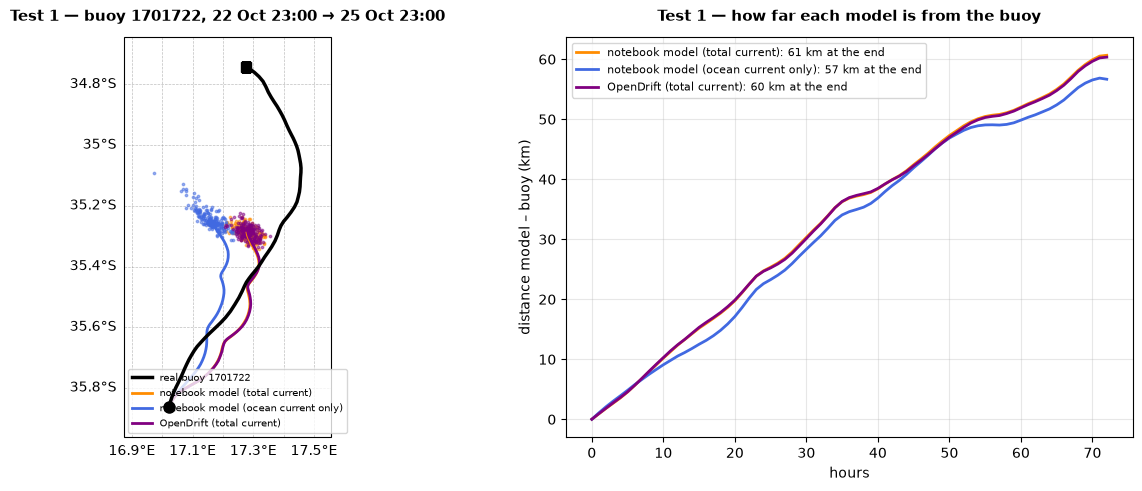


   EVERY TEST:


after 24 h (km)  \
test buoy    period          model                                                  
1    1701722 22 Oct → 25 Oct notebook model (total current)                  24.7   
                             notebook model (ocean current only)             22.6   
                             OpenDrift (total current)                       24.7   

                                                                  after 48 h (km)  \
test buoy    period          model                                                  
1    1701722 22 Oct → 25 Oct notebook model (total current)                  45.4   
                             notebook model (ocean current only)             45.1   
                             OpenDrift (total current)                       45.1   

                                                                  after 72 h (km)  \
test buoy    period          model                                                  
1    1701722 22 Oct → 25 Oct notebook model (total current)                  60.7   
                             notebook model (ocean current only)             56.7   
                             OpenDrift (total current)                       60.3   

                                                                  mean error (km)  
test buoy    period          model                                                 
1    1701722 22 Oct → 25 Oct notebook model (total current)                  33.4  
                             notebook model (ocean current only)             31.7  
                             OpenDrift (total current)                       33.3

   SUMMARY — average over the 1 tests (km):


,after 24 h (km),after 48 h (km),after 72 h (km),mean error (km)
model,,,,
OpenDrift (total current),24.7,45.1,60.3,33.3
notebook model (ocean current only),22.6,45.1,56.7,31.7
notebook model (total current),24.7,45.4,60.7,33.4


   Use the "after 24 h" value of the total-current model in your bulletin confidence line, e.g.
   "Drift: typically N km off after 24 h, M km after 72 h (checked against K buoys)."


In [63]:
# ============================================================
# STEP 4.9 — OPTIONAL: SEVERAL BUOY TESTS IN ONE FIGURE
# ─────────────────────────────────────────────────────────────
# The buoy check of Step 4.8, for several buoys / periods at once:
#   black  = real buoy · orange = notebook model, total current
#   blue   = notebook model, ocean current only · purple = OpenDrift
# Needs the buoy list of Step 4.6 (buoys). OpenDrift is used if installed.
# ============================================================

TESTS = [('7810806', '2026-10-23 18:00'),     # (buoy, end of the 3 days) — same 3 days for both buoys
         ('7810809', '2026-10-23 18:00')]
# zone3
TESTS = [('1701722', '2026-10-25 23:00'),     # (buoy, end of the 3 days) — same 3 days for both buoys
         ('4804012', '2026-09-21 18:00')]
# TESTS = None    # automatic: every buoy, its last 3 days + an earlier, separate 3-day period when it has one
NO_LOOPS = True # also run the model with the inertial/tidal loops FILTERED OUT of the currents (an experiment)
try:
    from opendrift.models.oceandrift import OceanDrift
    from opendrift.readers import reader_netCDF_CF_generic
    has_od = True
except ImportError:
    has_od = False
    print('   (OpenDrift is not installed: the tests use the notebook model only.)')


def buoy_test(pid_, end=None):
    """One buoy test: the buoy track over DRIFT_DAYS, and the drifts started where the buoy was."""
    g = buoys[str(pid_)]
    t_end = min(pd.Timestamp(end), g.index[-1]) if end else g.index[-1]
    tr = g[(g.index >= t_end - pd.Timedelta(days=DRIFT_DAYS)) & (g.index <= t_end)].resample('1h').mean().interpolate(limit=6).dropna()
    if len(tr) < 24:
        return None
    s0_ = tr.iloc[0]
    hrs_ = int((tr.index[-1] - tr.index[0]) / pd.Timedelta(hours=1))
    vb = dict(minimum_longitude=float(tr.longitude.min()) - 1.5, maximum_longitude=float(tr.longitude.max()) + 1.5,
              minimum_latitude=float(tr.latitude.min()) - 1.5, maximum_latitude=float(tr.latitude.max()) + 1.5)
    cur = stream('TOTAL_CUR', tr.index[0] - pd.Timedelta(hours=2), tr.index[-1] + pd.Timedelta(hours=2), box=vb,
                 variables=['utotal', 'vtotal', 'uo', 'vo'])
    cur = (cur.isel(depth=0) if 'depth' in cur.dims else cur).compute()
    out = {}
    for name, (u, v, c) in {'notebook model (total current)': ('utotal', 'vtotal', 'darkorange'),
                            'notebook model (ocean current only)': ('uo', 'vo', 'royalblue')}.items():
        d = drift([(*field(cur[u], cur[v]), 1)], s0_.longitude, s0_.latitude, tr.index[0], hrs_, radius_km=0.1, box=vb, n=200)
        out[name] = (d.lon.mean('particle').to_series(), d.lat.mean('particle').to_series(),
                     d.isel(time=-1).lon.values, d.isel(time=-1).lat.values, c)
    if has_od:
        fb = OUTPUT_DIR / f'SMOC_test_{FILE_PREFIX}.nc'
        cf = cur[['utotal', 'vtotal']].rename(utotal='x_sea_water_velocity', vtotal='y_sea_water_velocity')
        cf['x_sea_water_velocity'].attrs.update(standard_name='x_sea_water_velocity', units='m s-1')
        cf['y_sea_water_velocity'].attrs.update(standard_name='y_sea_water_velocity', units='m s-1')
        cf.drop_vars([c for c in cf.coords if c not in ('time', 'latitude', 'longitude')]).to_netcdf(fb)
        o = OceanDrift(loglevel=50)
        o.add_reader(reader_netCDF_CF_generic.Reader(str(fb)))
        for key in ('drift:horizontal_diffusivity', 'environment:constant:horizontal_diffusivity'):
            if key in o.get_configspec():
                o.set_config(key, K_DIFF); break
        o.set_config('general:coastline_action', 'stranding')
        o.seed_elements(lon=s0_.longitude, lat=s0_.latitude, radius=100, number=200, time=tr.index[0].to_pydatetime(),
                        wind_drift_factor=0)
        o.run(duration=pd.Timedelta(hours=hrs_).to_pytimedelta(), time_step=1800, time_step_output=3600)
        r_ = o.result
        ol, oa = r_.lon.mean('trajectory', skipna=True).to_series(), r_.lat.mean('trajectory', skipna=True).to_series()
        ol.index, oa.index = pd.to_datetime(ol.index), pd.to_datetime(oa.index)
        out['OpenDrift (total current)'] = (ol, oa, r_.lon.isel(time=-1).values, r_.lat.isel(time=-1).values, 'purple')
        fb.unlink(missing_ok=True)
    return tr, out


if 'buoys' not in globals() or not buoys:
    print('No drifting buoy list from Step 4.6 — run Step 4.6 first (this step is optional).')
else:
    if TESTS is None:                                    # automatic list of tests
        TESTS = []
        for p, g in buoys.items():
            TESTS.append((p, None))
            early_end = g.index[-1] - pd.Timedelta(days=DRIFT_DAYS)
            if early_end - g.index[0] >= pd.Timedelta(days=DRIFT_DAYS):
                TESTS.append((p, f'{early_end:%Y-%m-%d %H:%M}'))
    results = []
    for p, end in TESTS:
        print(f'==> Test: buoy {p}, period ending {end or "at its last position"} ...')
        res = buoy_test(p, end)
        if res is None:
            print('   not enough positions — skipped.'); continue
        results.append((p, *res))

    fig = plt.figure(figsize=(15, 5.2 * len(results)))
    gs = fig.add_gridspec(len(results), 2, width_ratios=[1, 1.1], wspace=0.15, hspace=0.35)
    rows = []
    for i, (p, tr, out) in enumerate(results):
        ax = fig.add_subplot(gs[i, 0], projection=PC)
        ax.plot(tr.longitude, tr.latitude, 'k-', lw=2.5, transform=PC, zorder=6, label=f'real buoy {p}')
        ax.plot(tr.longitude.iloc[0], tr.latitude.iloc[0], 'ko', ms=8, transform=PC, zorder=7)
        ax.plot(tr.longitude.iloc[-1], tr.latitude.iloc[-1], 'ks', ms=7, transform=PC, zorder=7)
        xs, ys = [tr.longitude.values], [tr.latitude.values]
        for k, (mlon, mlat, elon, elat, c) in out.items():
            ax.plot(mlon, mlat, '-', color=c, lw=2, transform=PC, zorder=5, label=k)
            ax.scatter(elon, elat, s=3, color=c, alpha=0.5, transform=PC, zorder=4)
            xs += [mlon.values, elon]; ys += [mlat.values, elat]
        xs, ys = np.concatenate(xs), np.concatenate(ys)
        decorate(ax, extent=[np.nanmin(xs) - 0.1, np.nanmax(xs) + 0.1, np.nanmin(ys) - 0.1, np.nanmax(ys) + 0.1])
        ax.legend(fontsize=7, loc='lower left')
        ax.set_title(f'Test {i + 1} — buoy {p}, {tr.index[0]:%d %b %H:%M} → {tr.index[-1]:%d %b %H:%M}', fontsize=11)

        ax = fig.add_subplot(gs[i, 1])
        hh = (tr.index - tr.index[0]) / pd.Timedelta(hours=1)
        for k, (mlon, mlat, elon, elat, c) in out.items():
            lo = mlon.reindex(tr.index, method='nearest'); la = mlat.reindex(tr.index, method='nearest')
            sep = np.hypot(*km_xy(lo.values, la.values, tr.longitude.values, tr.latitude.values))
            ax.plot(hh, sep, color=c, lw=2, label=f'{k}: {sep[-1]:.0f} km at the end')
            rows.append({'test': i + 1, 'buoy': p, 'period': f'{tr.index[0]:%d %b} → {tr.index[-1]:%d %b}', 'model': k,
                         'after 24 h (km)': sep[min(24, len(sep) - 1)], 'after 48 h (km)': sep[min(48, len(sep) - 1)],
                         'after 72 h (km)': sep[min(72, len(sep) - 1)], 'mean error (km)': np.nanmean(sep)})
        ax.set_xlabel('hours'); ax.set_ylabel('distance model – buoy (km)'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
        ax.set_title(f'Test {i + 1} — how far each model is from the buoy', fontsize=11)
    save_fig(fig, f'Day3_SAR_buoy_tests_{FILE_PREFIX}_{STAMP}.png')
    plt.show()

    tests_df = pd.DataFrame(rows)
    print('\n   EVERY TEST:')
    display(tests_df.set_index(['test', 'buoy', 'period', 'model']).round(1))
    print(f'   SUMMARY — average over the {len(results)} tests (km):')
    display(tests_df.groupby('model')[['after 24 h (km)', 'after 48 h (km)', 'after 72 h (km)', 'mean error (km)']].mean().round(1))
    print('   Use the "after 24 h" value of the total-current model in your bulletin confidence line, e.g.\n'
          '   "Drift: typically N km off after 24 h, M km after 72 h (checked against K buoys)."')

## Section 5 — Application 2: Marine Heatwaves

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Application block 2 · 15:20–16:20</span> &nbsp; **MOOC Module 7 · MyOcean Health (Webinar Day 3)**

A **marine heatwave** (MHW) is a period when the sea is unusually warm for the time of year, for several days. It can bleach corals,
kill fish and shellfish, move fish stocks away from the coast and fuel storms. The standard definition (Hobday et al., 2016) is:

> the surface temperature stays **above the 90th percentile** of the 30-year record for that day of the year, for **at least 5 days**.

The intensity is measured against the gap between normal and threshold (Hobday et al., 2018):

| Category | SST − normal, in multiples of (threshold − normal) | |
|---|---|---|
| **I — Moderate** | 1 to 2 | 🟡 |
| **II — Strong** | 2 to 3 | 🟠 |
| **III — Severe** | 3 to 4 | 🔴 |
| **IV — Extreme** | 4 and more | 🟤 |

This morning's anomaly compared the forecast with a **monthly** normal. A heatwave needs more: a **daily** normal and a **daily threshold**,
from 30 years of **daily** reanalysis (GLORYS12, Day 2) — then you can say, day by day, whether the analyses of the last 30 days and the
10-day forecast at your point are in a heatwave. This is what **MyOcean Health** shows for the global ocean (Webinar Day 3).

WARNING - 2026-10-26T14:20:43Z - Some of your subset selection [0.0, 1.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]



==> 10,957 days of reanalysis SST at Shipping lane off East London (1993–2022), 7 s


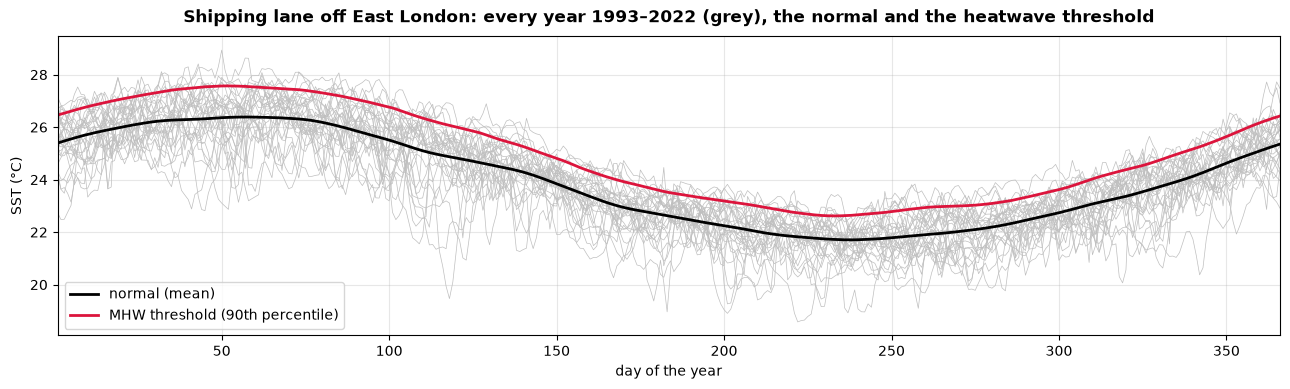

   The threshold is 1.03 °C above normal on average (from 0.87 to 1.26 °C).


In [64]:
# ============================================================
# STEP 5.1 — 30 YEARS OF DAILY SST AT YOUR POINT -> NORMAL AND THRESHOLD
# ─────────────────────────────────────────────────────────────
# One small stream (a few points, 30 years, daily) with the
# 'arco-time-series' service, made for long series at one place.
# For each day of the year: the normal (mean) and the 90th percentile,
# using an 11-day window and a 31-day smoothing (Hobday et al., 2016).
# ============================================================

MHW_YEARS = (1993, 2022)        # 30-year reference period
pbox = dict(minimum_longitude=plon - 0.1, maximum_longitude=plon + 0.1,
            minimum_latitude=plat - 0.1, maximum_latitude=plat + 0.1)
t0 = time.time()
h = stream('CLIM_D', f'{MHW_YEARS[0]}-01-01', f'{MHW_YEARS[1]}-12-31', box=pbox, service='arco-time-series')['thetao']
with ProgressBar():
    hist = surf(h).mean(['latitude', 'longitude']).compute().to_series()
hist.index = pd.to_datetime(hist.index).normalize()
print(f'\n==> {len(hist):,} days of reanalysis SST at {UPNAME} ({hist.index[0]:%Y}–{hist.index[-1]:%Y}), {time.time() - t0:.0f} s')


def doy366(idx):
    """Day of year on a 366-day calendar (29 Feb = day 60 every year), so that dates match across years."""
    idx = pd.DatetimeIndex(idx)
    # print(idx)
    d = idx.dayofyear.values.copy()
    d[(~idx.is_leap_year) & (d >= 60)] += 1
    # print(d)
    return d

def circ(a, smooth=31):
    h = smooth // 2                                          # 15
    s = pd.Series(a)
    padded = pd.concat([s.iloc[-h:], s, s.iloc[:h]])         # Dec | the year | Jan
    return padded.rolling(smooth, center=True).mean().iloc[h:-h].values

def mhw_climatology(s, window=11, smooth=31, pct=90):
    d = doy366(s.index); v = s.values
    clim, thr = np.full(366, np.nan), np.full(366, np.nan)
    for k in range(1, 367):
        dist = np.abs(((d - k) + 183) % 366 - 183)
        # print(dist)
        sel = v[dist <= window // 2]
        clim[k - 1], thr[k - 1] = np.nanmean(sel), np.nanpercentile(sel, pct)
        # print(np.nanpercentile(sel, pct))
    h = smooth // 2
    circ = lambda a: pd.concat([pd.Series(a[-h:]), pd.Series(a), pd.Series(a[:h])]).rolling(smooth, center=True).mean().iloc[h:-h].values
    return pd.Series(circ(clim), index=range(1, 367)), pd.Series(circ(thr), index=range(1, 367))


CLIM_DAY, THR_DAY = mhw_climatology(hist)
on = lambda ser, idx: ser.reindex(doy366(idx)).values          # climatology on given dates

fig, ax = plt.subplots(figsize=(13, 4))
for y in range(MHW_YEARS[0], MHW_YEARS[1] + 1):
    s = hist[hist.index.year == y]
    ax.plot(doy366(s.index), s.values, color='0.75', lw=0.5)
ax.plot(CLIM_DAY.index, CLIM_DAY, 'k', lw=2, label='normal (mean)')
ax.plot(THR_DAY.index, THR_DAY, color='crimson', lw=2, label='MHW threshold (90th percentile)')
ax.set_xlim(1, 366); ax.set_xlabel('day of the year'); ax.set_ylabel('SST (°C)'); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f'{UPNAME}: every year {MHW_YEARS[0]}–{MHW_YEARS[1]} (grey), the normal and the heatwave threshold')
plt.show()
print(f'   The threshold is {float((THR_DAY - CLIM_DAY).mean()):.2f} °C above normal on average '
      f'(from {float((THR_DAY - CLIM_DAY).min()):.2f} to {float((THR_DAY - CLIM_DAY).max()):.2f} °C).')

In [65]:
CLIM_DAY

1      25.394460
2      25.434713
3      25.473966
4      25.512154
5      25.549626
         ...    
362    25.184108
363    25.227479
364    25.270282
365    25.312238
366    25.353644
Length: 366, dtype: float64

In [66]:
MHW_YEARS[0], MHW_YEARS[1] + 1

(1993, 2023)

         start        end  days
run                            
2   2026-09-28 2026-10-20    23
4   2026-10-27 2026-11-02     7
==> Saved: ~/OPERA_Workshop/Day3/output/Day3_MHW_now_AGU_20261026.png


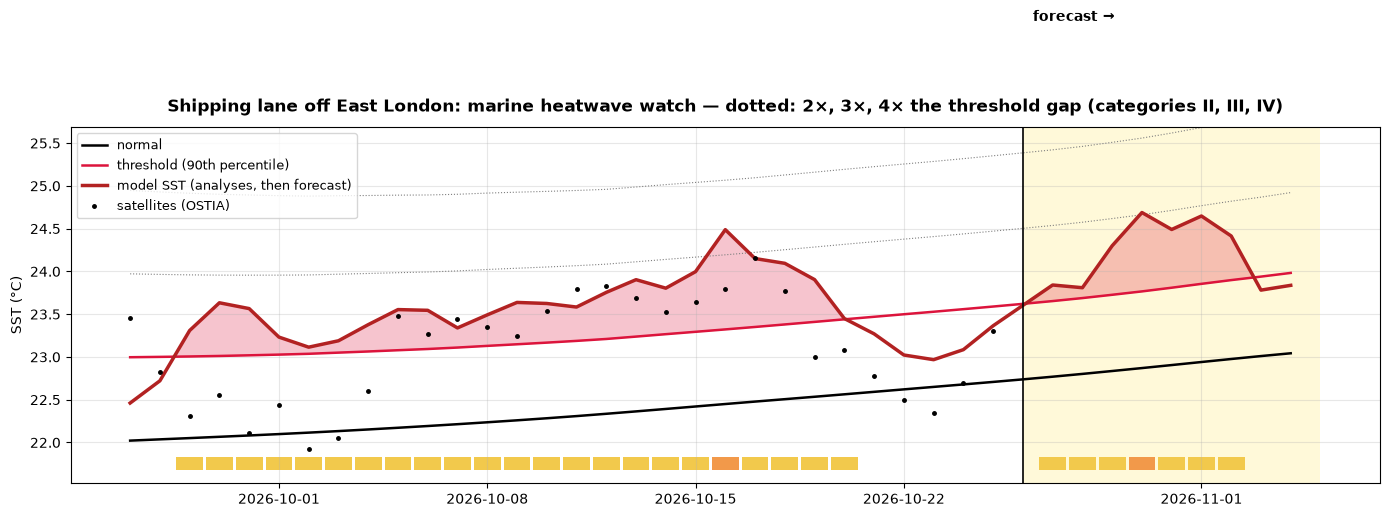

,start,end,days,peak_anomaly,category
0,28 Sep,20 Oct,23,2.04,II strong
1,27 Oct,02 Nov,7,1.82,II strong


   A II strong marine heatwave is ongoing: 27 Oct → 02 Nov (7 days, peak +1.8 °C above normal).
   Forecast days in a heatwave: 7 of 10


In [67]:
# ============================================================
# STEP 5.2 — IS THERE A MARINE HEATWAVE NOW, OR COMING?
# ─────────────────────────────────────────────────────────────
# The last 30 days (analyses) and the 10-day forecast at your point,
# against the daily normal and threshold. A heatwave = at least 5 days
# above the threshold; two heatwaves separated by a gap of 1–2 days
# count as one (Hobday et al., 2016). Categories: Hobday et al. (2018).
# ============================================================

CATS = {0: ('none', '#2E9E5B'), 1: ('I moderate', '#F2C94C'), 2: ('II strong', '#F2994A'),
        3: ('III severe', '#D7263D'), 4: ('IV extreme', '#7B2D26')}

def mhw_events(s, clim, thr, min_days=5, max_gap=2):
    """Marine heatwaves in a daily SST series s (Hobday et al. 2016; categories: Hobday et al. 2018).
    clim, thr: the normal and the threshold on the same dates as s.
    Returns: the category of each day (0 = none, 1–4 = I–IV) and a table with one row per heatwave."""
    d = pd.DataFrame({'sst': s.values, 'clim': clim, 'thr': thr}, index=s.index)
    d['date'] = d.index
    d['above'] = d.sst > d.thr                                  # is the day above the threshold?
    d['ratio'] = (d.sst - d.clim) / (d.thr - d.clim)            # how many ΔT above normal

    # 1. runs of consecutive warm days: the run number goes up by 1 each time 'above' switches
    d['run'] = (d.above != d.above.shift()).cumsum()
    runs = d[d.above].groupby('run').agg(start=('date', 'first'), end=('date', 'last'), days=('date', 'size'))
    print(runs)

    # 2. keep only runs of at least 5 days
    runs = runs[runs.days >= min_days]

    # 3. join two heatwaves if the gap between them is 2 days or less
    events = []
    for start, end in zip(runs.start, runs.end):
        if events and (start - events[-1][1]).days - 1 <= max_gap:
            events[-1][1] = end                                 # same heatwave: extend it
        else:
            events.append([start, end])                         # a new heatwave

    # 4. category of each day, and one row per heatwave
    d['cat'] = 0
    rows = []
    for start, end in events:
        d.loc[start:end, 'cat'] = d.loc[start:end, 'ratio'].clip(1, 4).astype(int)   # 1.x → I, 2.x → II, … ≥ 4 → IV
        ev = d.loc[start:end]
        rows.append({'start': start, 'end': end, 'days': len(ev),
                     'peak_anomaly': round(float((ev.sst - ev.clim).max()), 2),
                     'category': CATS[int(ev.cat.max())][0]})
    return d['cat'], pd.DataFrame(rows)
    
now = sst_pt.to_series()
now.index = pd.to_datetime(now.index).normalize()
c_now, t_now = on(CLIM_DAY, now.index), on(THR_DAY, now.index)
MHW_CAT, MHW_EV = mhw_events(now, c_now, t_now)

fig, ax = plt.subplots(figsize=(14, 5.2))
ax.axvspan(TODAY, now.index[-1] + pd.Timedelta(days=1), color='gold', alpha=0.15, lw=0)
for m, ls in [(2, ':'), (3, ':'), (4, ':')]:
    ax.plot(now.index, c_now + m * (t_now - c_now), color='0.5', ls=ls, lw=0.8)
ax.plot(now.index, c_now, 'k', lw=1.8, label='normal')
ax.plot(now.index, t_now, color='crimson', lw=1.8, label='threshold (90th percentile)')
ax.fill_between(now.index, t_now, now.values, where=now.values > t_now, color='crimson', alpha=0.25, interpolate=True)
ax.plot(now.index, now.values, color='firebrick', lw=2.5, label='model SST (analyses, then forecast)')
if 'obs_pt' in globals():
    ax.plot(obs_pt.time, obs_pt, 'k.', ms=5, label='satellites (OSTIA)')
for d, c in MHW_CAT.items():
    if c:
        ax.bar(d, 0.15, bottom=ax.get_ylim()[0], width=0.9, color=CATS[c][1])
ax.axvline(TODAY, color='k', lw=1.2); ax.text(TODAY, ax.get_ylim()[1], '  forecast →', va='top', fontweight='bold')
ax.set_ylabel('SST (°C)'); ax.grid(alpha=0.3); ax.legend(loc='upper left', fontsize=9)
ax.set_ylim(min(np.nanmin(now.values), np.nanmin(c_now)) - 0.5,
            max(np.nanmax(now.values), np.nanmax(t_now)) + 1.0)   # zoom on the data; dotted lines above are cut off
ax.set_title(f'{UPNAME}: marine heatwave watch — dotted: 2×, 3×, 4× the threshold gap (categories II, III, IV)')
save_fig(fig, f'Day3_MHW_now_{FILE_PREFIX}_{STAMP}.png')
plt.show()

if len(MHW_EV):
    display(MHW_EV.assign(start=MHW_EV.start.dt.strftime('%d %b'), end=MHW_EV.end.dt.strftime('%d %b')).round(2))
    last = MHW_EV.iloc[-1]
    state = 'is ongoing' if last.end >= TODAY else 'ended'
    print(f'   A {last.category} marine heatwave {state}: {last.start:%d %b} → {last.end:%d %b} ({last.days} days, '
          f'peak +{last.peak_anomaly:.1f} °C above normal).')
else:
    print('   No marine heatwave at your point in the last 30 days or in the 10-day forecast.')
print(f'   Forecast days in a heatwave: {int((MHW_CAT[MHW_CAT.index >= TODAY] > 0).sum())} of {int((MHW_CAT.index >= TODAY).sum())}')

         start        end  days
run                            
2   1993-01-02 1993-01-09     8
4   1993-04-22 1993-04-27     6
6   1993-07-14 1993-07-16     3
8   1993-07-18 1993-07-19     2
10  1993-08-06 1993-08-10     5
..         ...        ...   ...
618 2022-11-11 2022-11-12     2
620 2022-11-21 2022-11-24     4
622 2022-11-26 2022-11-29     4
624 2022-12-07 2022-12-12     6
626 2022-12-15 2022-12-19     5

[313 rows x 3 columns]
==> Saved: ~/OPERA_Workshop/Day3/output/Day3_MHW_history_AGU_20261026.png


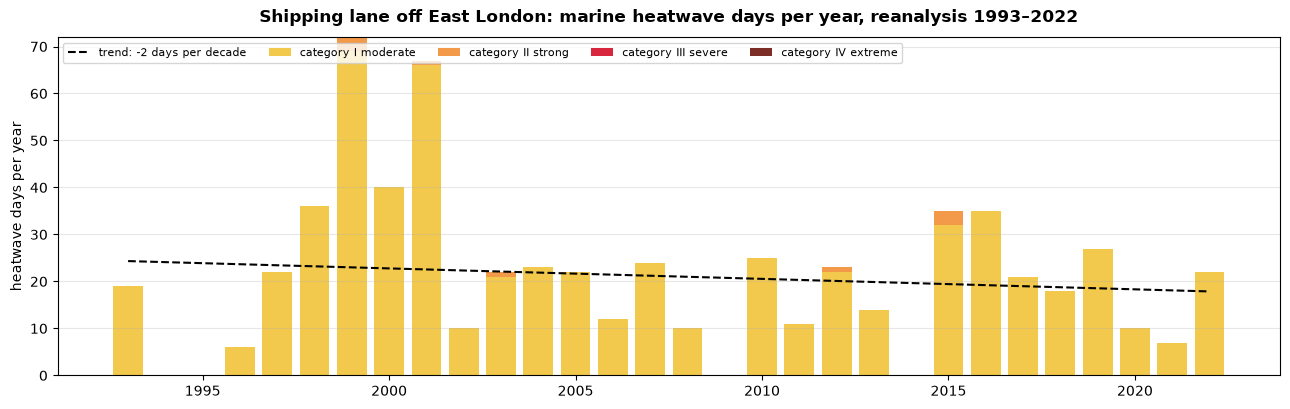

   73 heatwaves in 30 years · 25 days/year in 1993–2007, 17 days/year in 2008–2022
   Strongest events: Feb 2003 (+2.6 °C, 15 days) · Dec 1999 (+2.5 °C, 8 days) · Dec 2012 (+2.4 °C, 7 days)


In [68]:
# ============================================================
# STEP 5.3 — ARE MARINE HEATWAVES BECOMING MORE FREQUENT HERE?
# ─────────────────────────────────────────────────────────────
# The same detection applied to the 30 years of reanalysis:
# number of heatwave days per year at your point.
# ============================================================

cat_hist, ev_hist = mhw_events(hist, on(CLIM_DAY, hist.index), on(THR_DAY, hist.index))
per_year = pd.DataFrame({k: (cat_hist == k).groupby(cat_hist.index.year).sum() for k in range(1, 5)})
total = per_year.sum(1)
slope = np.polyfit(total.index, total.values, 1)[0] * 10

fig, ax = plt.subplots(figsize=(13, 4.2))
bottom = np.zeros(len(per_year))
for k in range(1, 5):
    ax.bar(per_year.index, per_year[k], bottom=bottom, color=CATS[k][1], label=f'category {CATS[k][0]}')
    bottom += per_year[k].values
ax.plot(total.index, np.polyval(np.polyfit(total.index, total.values, 1), total.index), 'k--', lw=1.5,
        label=f'trend: {slope:+.0f} days per decade')
ax.set_ylabel('heatwave days per year'); ax.grid(alpha=0.3, axis='y'); ax.legend(fontsize=8, ncol=5, loc='upper left')
ax.set_title(f'{UPNAME}: marine heatwave days per year, reanalysis {MHW_YEARS[0]}–{MHW_YEARS[1]}')
save_fig(fig, f'Day3_MHW_history_{FILE_PREFIX}_{STAMP}.png')
plt.show()
first, second = total.loc[:MHW_YEARS[0] + 14].mean(), total.loc[MHW_YEARS[0] + 15:].mean()
print(f'   {len(ev_hist)} heatwaves in {MHW_YEARS[1] - MHW_YEARS[0] + 1} years · '
      f'{first:.0f} days/year in {MHW_YEARS[0]}–{MHW_YEARS[0] + 14}, {second:.0f} days/year in {MHW_YEARS[0] + 15}–{MHW_YEARS[1]}')
if len(ev_hist):
    top = ev_hist.sort_values('peak_anomaly', ascending=False).head(3)
    print('   Strongest events: ' + ' · '.join(f'{r.start:%b %Y} (+{r.peak_anomaly:.1f} °C, {r.days} days)' for r in top.itertuples()))

### 🔎 Reading the heatwave figures

- The threshold is **relative to the time of year**: 28 °C can be normal in March and a heatwave in August. That is why we need a
  **daily** normal, not a monthly one.
- With a fixed 30-year reference, a warming ocean gives **more heatwave days** in recent years (Step 5.3). This is one of the clearest
  signals of climate change in the ocean (Ocean State Report; Webinar Day 3).
- The forecast is **model SST**; the threshold comes from the **reanalysis** (same model family, Day 2). A small systematic difference
  shifts the days in or out of a heatwave: compare with the satellites (black dots) before you raise an alarm.

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_forecast_SST_anomaly_AGU_20261026.png


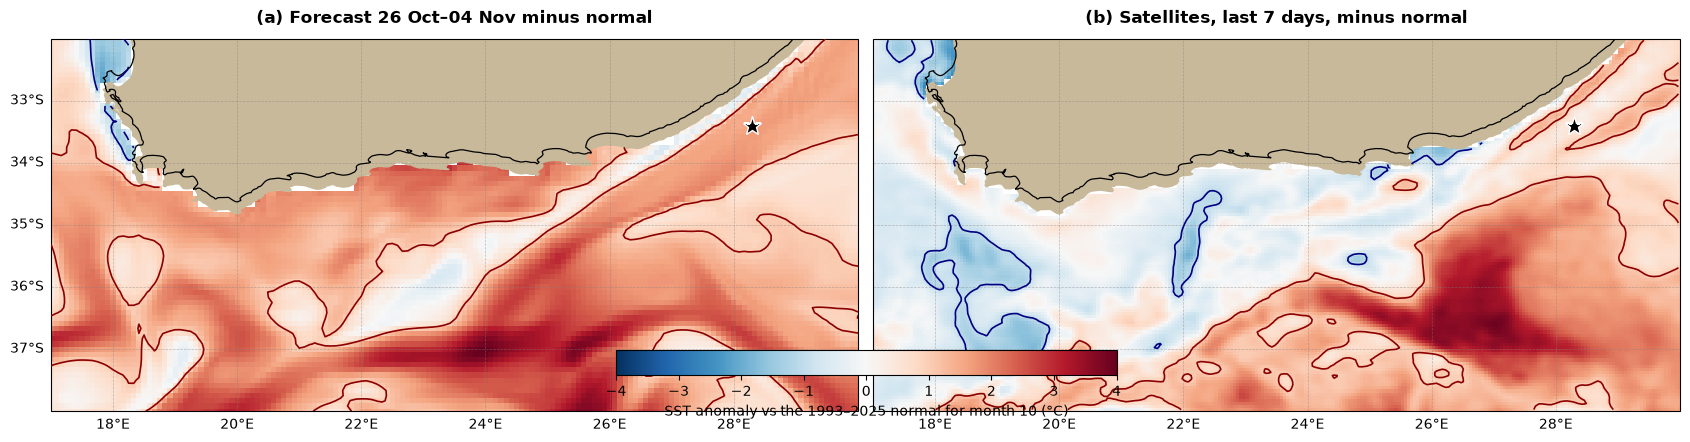

   At Shipping lane off East London: forecast +1.7 °C · satellites +0.4 °C · region mean +1.47 °C


In [69]:
# ============================================================
# STEP 5.4 — WHERE IS IT WARM? THE FORECAST vs THE NORMAL, AS A MAP
# ─────────────────────────────────────────────────────────────
# Anomaly = forecast mean SST (next 10 days) − normal SST for this
# month (reanalysis, CLIM_YEARS). Red: warmer than usual (heatwave
# watch); blue: colder than usual (upwelling).
# ============================================================

sst_fc_mean = sst.sel(time=fc_dates).mean('time')
anom = sst_fc_mean - sst_clim.interp_like(sst_fc_mean)
lim = max(2.0, float(np.ceil(np.nanpercentile(np.abs(anom), 98))))
obs_recent = sst_obs.sel(time=slice(TODAY - pd.Timedelta(days=7), None)).mean('time')
obs_anom = obs_recent - sst_clim.interp(longitude=obs_recent.longitude, latitude=obs_recent.latitude)

aspect = (LON_MAX - LON_MIN) / (LAT_MAX - LAT_MIN)
fig, axes = plt.subplots(1, 2, figsize=(min(17, 2 * 5.5 * aspect + 3), 6.5), subplot_kw={'projection': PC})
for k, (ax, da, title) in enumerate(zip(axes, [anom, obs_anom],
                                        [f'(a) Forecast {fc_dates[0]:%d %b}–{fc_dates[-1]:%d %b} minus normal',
                                         '(b) Satellites, last 7 days, minus normal'])):
    p = da.plot(ax=ax, transform=PC, cmap='RdBu_r', vmin=-lim, vmax=lim, extend='both', add_colorbar=False, add_labels=False)
    ax.contour(da.longitude, da.latitude, da, levels=[TH['sst_cold'], TH['sst_warm']], colors=['navy', 'darkred'],
               linewidths=1.2, transform=PC, zorder=4)
    ax.plot(UPLON, UPLAT, 'k*', ms=14, mec='white', transform=PC, zorder=6)
    decorate(ax, extent=EXTENT, left=(k == 0)); ax.set_title(title)
fig.colorbar(p, ax=axes, orientation='horizontal', fraction=0.05, pad=0.08,
             label=f'SST anomaly vs the {CLIM_YEARS[0]}–{CLIM_YEARS[1]} normal for month {FC_MONTH} (°C)')
save_fig(fig, f'Day3_forecast_SST_anomaly_{FILE_PREFIX}_{STAMP}.png')
plt.show()
print(f'   At {UPNAME}: forecast {float(anom.sel(**at, method="nearest")):+.1f} °C · '
      f'satellites {float(obs_anom.sel(longitude=UPLON, latitude=UPLAT, method="nearest")):+.1f} °C · region mean {float(anom.mean()):+.2f} °C')

In [70]:
da

<xarray.DataArray (latitude: 120, longitude: 260)> Size: 250kB
array([[-0.33162306, -0.32526979, -0.33905309, ...,  1.62833027,
         1.59160961,  1.59986766],
       [-0.44204451, -0.43059049, -0.43361872, ...,  1.53496755,
         1.52280595,  1.53320543],
       [-0.52812118, -0.50786061, -0.51147137, ...,  1.48513174,
         1.49864224,  1.504493  ],
       ...,
       [-0.410497  , -0.53601297, -0.66958456, ...,  0.63188131,
         0.68764864,  0.74490024],
       [-0.34058643, -0.48766483, -0.64214862, ...,  0.63124969,
         0.69154521,  0.76528005],
       [-0.26629813, -0.42752297, -0.59069564, ...,  0.62236067,
         0.67939533,  0.75052358]], shape=(120, 260))
Coordinates:
  * latitude   (latitude) float32 480B -37.97 -37.92 -37.88 ... -32.08 -32.03
  * longitude  (longitude) float32 1kB 17.02 17.08 17.12 ... 29.88 29.92 29.98
    depth      float32 4B 0.494
Attributes:
    comment:        OSTIA foundation SST
    reference:     Good S, Fiedler E, Mao C, Martin MJ, Maycock A, Reid R, Ro...
    source:        AVHRR18_G-NAVO-L2P-V1.0, AVHRR19_G-NAVO-L2P-V1.0, AVHRR_SS...
    cell_methods:  area: mean
    unit_long:     Degrees Celsius

<div style="border-left:6px solid #E97132; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#E97132">✍️ Your turn (10 min) — your heatwave message</b><br>1. Is there a heatwave at your point now, or in the forecast? Which category, from when to when?<br>2. Do the satellites agree with the model?<br>3. Who in your region should know (fishers, aquaculture, coral reef managers, health services)? Write one sentence for them, e.g. <i>“The sea off … is … °C warmer than usual and will stay so until …: risk of …”</i>.</div>

## Section 6 — From Forecast to Decision: Your Bulletin

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Use block · 16:20–16:40</span> &nbsp; **MOOC Module 7 — Downstream applications**

Two users today: the **rescue centre** (Section 4) and the people exposed to **heatwaves** (Section 5). Your bulletin brings both
together with the sea state for the next days:

1. **Alerts** — day by day at your user point: waves, currents, heatwave category — 🟢 normal · 🟠 watch · 🔴 warning.
2. **The bulletin** — one page: key messages, the search area, the heatwave watch, the alerts, and how confident you are.

<div style="border-left:6px solid #1A54EB; background:#F4F7FC; padding:10px 14px; margin:8px 0; border-radius:4px"><b style="color:#1A54EB">Thresholds are a decision</b><br>The default thresholds are starting points (e.g. 2.5 m waves for artisanal pirogues). Discuss them in your subgroup and change them: a threshold is where science meets the user's reality.</div>

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_alerts_AGU_20261026.png


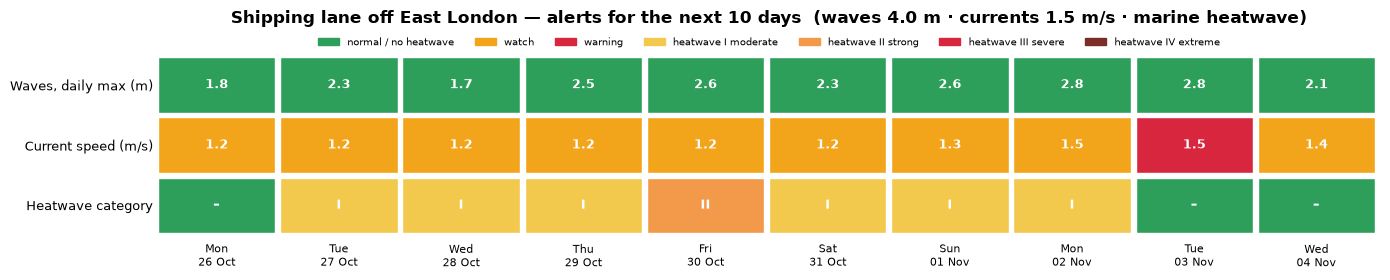

   Warnings (red): 1   Watches (amber): 9   Heatwave days: 7


In [71]:
# ============================================================
# STEP 6.1 — ALERTS FOR YOUR USER, DAY BY DAY
# ─────────────────────────────────────────────────────────────
# Edit the thresholds if your subgroup decides so, then re-run.
#   waves / currents : 🟢 < 75 % of threshold · 🟠 75–100 % · 🔴 above
#   heatwave         : category of the day (Section 5)
# ============================================================

TH = dict(A['thresholds'])          # e.g. TH['hs'] = 3.0  to change the wave threshold

fc = pd.DataFrame({
    'Waves, daily max (m)':  hs_pt.sel(time=fc_dates, method='nearest').values,
    'Current speed (m/s)':   spd_pt.sel(time=fc_dates).values,
    'Heatwave category':     MHW_CAT.reindex(fc_dates.normalize()).fillna(0).values,
}, index=fc_dates)

def level(name, x):
    if name.startswith('Heatwave'):
        return f'mhw{int(x)}'
    t = TH['hs'] if name.startswith('Waves') else TH['speed']
    return 'red' if x >= t else ('amber' if x >= 0.75 * t else 'ok')

COL = {'ok': '#2E9E5B', 'amber': '#F2A51A', 'red': '#D7263D', **{f'mhw{k}': c for k, (_, c) in CATS.items()}}
alerts = fc.apply(lambda col: col.map(lambda x: level(col.name, x)))

from matplotlib.patches import Patch
LEGEND = [Patch(color=COL['ok'], label='normal / no heatwave'), Patch(color=COL['amber'], label='watch'),
          Patch(color=COL['red'], label='warning'),
          *[Patch(color=CATS[k][1], label=f'heatwave {CATS[k][0]}') for k in range(1, 5)]]


def alert_grid(ax):
    """Draw the day-by-day alert table on an axis."""
    for i, name in enumerate(fc.columns):
        for j, d in enumerate(fc.index):
            ax.add_patch(plt.Rectangle((j, i), 0.96, 0.92, color=COL[alerts.iloc[j, i]], ec='white'))
            val = fc.iloc[j, i]
            txt_ = (['–', 'I', 'II', 'III', 'IV'][int(val)] if name.startswith('Heatwave') else f'{val:.1f}')
            ax.text(j + 0.48, i + 0.46, txt_, ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    ax.set_xlim(0, len(fc)); ax.set_ylim(len(fc.columns), 0)
    ax.set_xticks(np.arange(len(fc)) + 0.48); ax.set_xticklabels([f'{d:%a}\n{d:%d %b}' for d in fc.index], fontsize=8)
    ax.set_yticks(np.arange(len(fc.columns)) + 0.46); ax.set_yticklabels(fc.columns, fontsize=9)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.legend(handles=LEGEND, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=7, fontsize=7.5, frameon=False)


fig, ax = plt.subplots(figsize=(14, 2.9))
alert_grid(ax)
ax.set_title(f'{UPNAME} — alerts for the next {len(fc)} days  (waves {TH["hs"]} m · currents {TH["speed"]} m/s · marine heatwave)', pad=22)
save_fig(fig, f'Day3_alerts_{FILE_PREFIX}_{STAMP}.png')
plt.show()
print(f'   Warnings (red): {int((alerts == "red").sum().sum())}   Watches (amber): {int((alerts == "amber").sum().sum())}   '
      f'Heatwave days: {int((fc["Heatwave category"] > 0).sum())}')

### 6.2 — Write your bulletin

Fill in the text below **with your subgroup** (keep it short: a user reads a bulletin in 30 seconds), then run the cell.
It builds a **one-page bulletin** — key messages, the search area, the heatwave watch, the alerts and your confidence — saved as an image
and as a text file in your Day 3 output folder.

| ✔ Write | ✘ Avoid |
|---|---|
| “Search first **15 km south-west** of the LKP within 24 h; the object drifts ~**20 km/day** towards the south-west.” | “The object may have drifted.” |
| “The sea is **1.8 °C warmer than usual** until Friday: **strong** marine heatwave, risk for shellfish farms.” | “A positive SST anomaly is forecast.” |
| “High confidence for 24 h, medium for 48 h; no wind in the forecast drift.” | (no confidence statement) |

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_bulletin_AGU_20261026.png


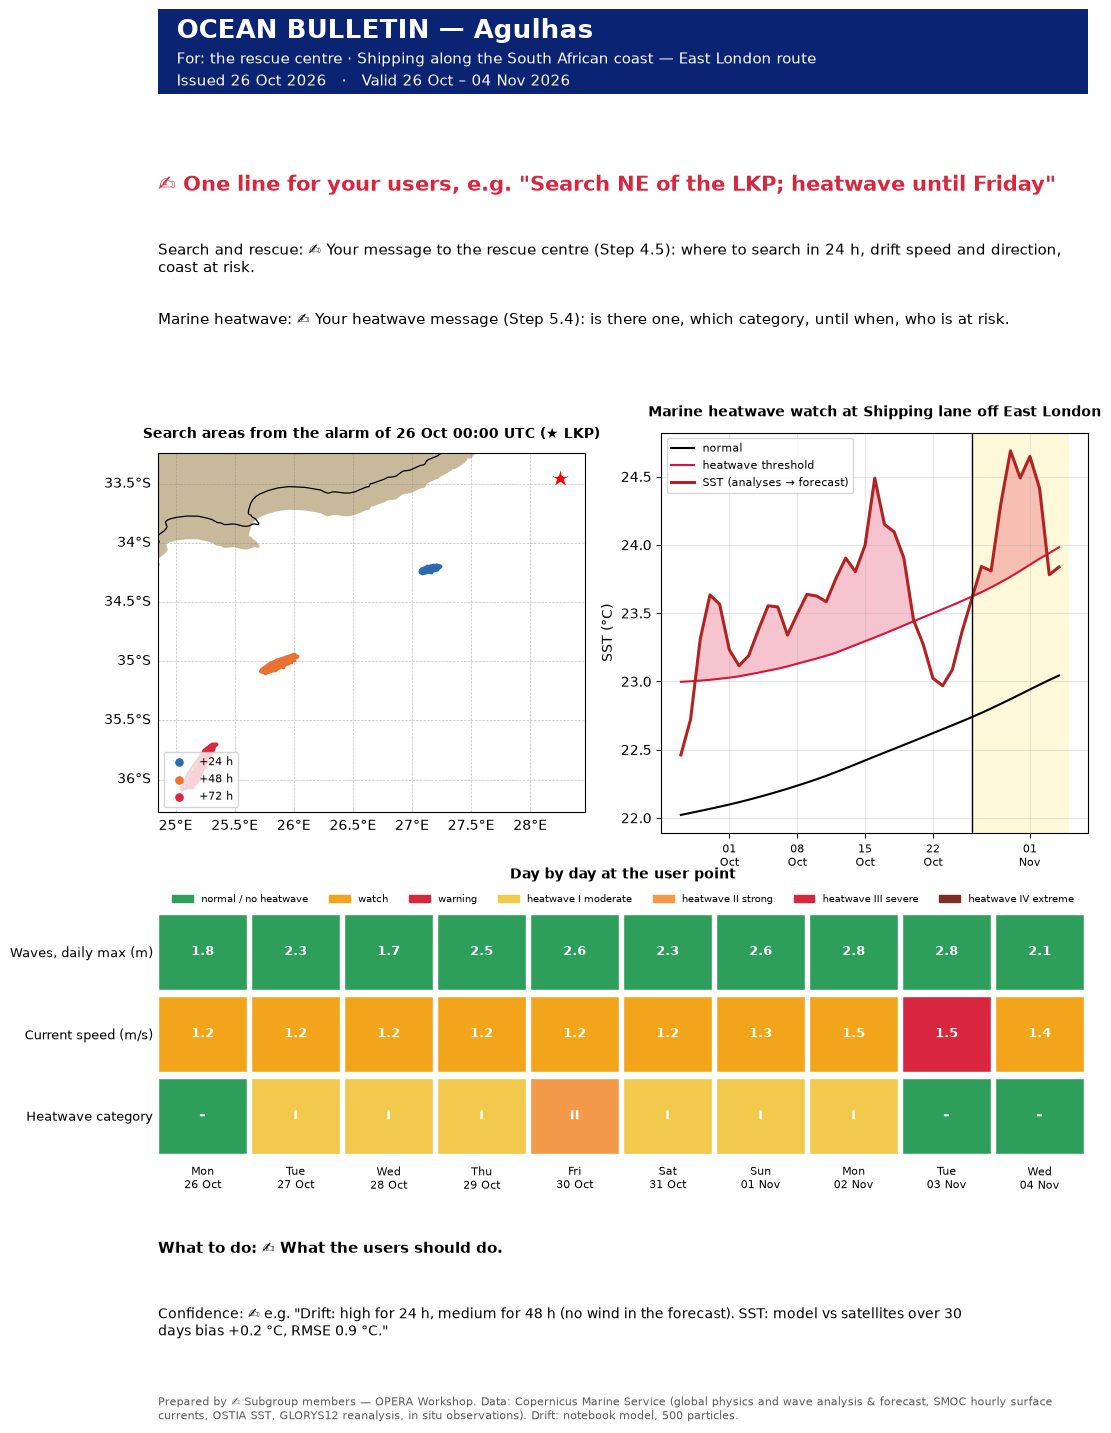

==> Saved: ~/OPERA_Workshop/Day3/output/Day3_bulletin_AGU_20261026.md
   (Some fields still contain the ✍️ template text — replace them before presenting.)


In [72]:
# ============================================================
# STEP 6.2 — YOUR ONE-PAGE BULLETIN
# ─────────────────────────────────────────────────────────────
# Replace the text between quotes, then run. The figure and the
# text are saved in your Day 3 output folder.
# ============================================================

BULLETIN = dict(
    headline   = '✍️ One line for your users, e.g. "Search NE of the LKP; heatwave until Friday"',
    sar        = '✍️ Your message to the rescue centre (Step 4.5): where to search in 24 h, drift speed and direction, coast at risk.',
    mhw        = '✍️ Your heatwave message (Step 5.4): is there one, which category, until when, who is at risk.',
    advice     = '✍️ What the users should do.',
    confidence = f'✍️ e.g. "Drift: high for 24 h, medium for 48 h (no wind in the forecast). SST: model vs satellites over 30 days '
                 f'bias {bias:+.1f} °C, RMSE {rmse:.1f} °C."',
    authors    = '✍️ Subgroup members',
)

import matplotlib.dates as mdates
wrap = lambda s, n: '\n'.join(textwrap.wrap(s, n))
fig = plt.figure(figsize=(12, 18))
gs = fig.add_gridspec(5, 2, height_ratios=[0.55, 1.15, 2.6, 1.6, 1.0], hspace=0.38, wspace=0.18)

ax = fig.add_subplot(gs[0, :]); ax.axis('off')
ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color='#0A2372'))
ax.text(0.02, 0.66, f'OCEAN BULLETIN — {DOMAIN_NAME}', color='white', fontsize=19, fontweight='bold', transform=ax.transAxes)
ax.text(0.02, 0.36, f'For: the rescue centre · {A["user"]}', color='white', fontsize=10.5, transform=ax.transAxes)
ax.text(0.02, 0.10, f'Issued {TODAY:%d %b %Y}   ·   Valid {fc.index[0]:%d %b} – {fc.index[-1]:%d %b %Y}',
        color='white', fontsize=10.5, transform=ax.transAxes)

ax = fig.add_subplot(gs[1, :]); ax.axis('off')
ax.text(0, 1.0, wrap(BULLETIN['headline'], 80), fontsize=15, fontweight='bold', color='#D7263D', va='top', transform=ax.transAxes)
ax.text(0, 0.62, 'Search and rescue: ' + wrap(BULLETIN['sar'], 105), fontsize=10.5, va='top', transform=ax.transAxes)
ax.text(0, 0.22, 'Marine heatwave: ' + wrap(BULLETIN['mhw'], 105), fontsize=10.5, va='top', transform=ax.transAxes)

ax = fig.add_subplot(gs[2, 0], projection=PC)
x, y = sar_fc.lon.values.ravel(), sar_fc.lat.values.ravel()
for hh in STEPS:
    s = sar_fc.isel(time=hh)
    ax.scatter(s.lon, s.lat, s=3, color=COLS[hh], transform=PC, zorder=4, label=f'+{hh} h')
    hull(ax, s.lon.values, s.lat.values, color=COLS[hh], lw=1.8, zorder=5)
ax.plot(LKP_LON, LKP_LAT, 'r*', ms=16, mec='white', transform=PC, zorder=6)
decorate(ax, extent=[np.nanmin(x) - 0.2, np.nanmax(x) + 0.2, np.nanmin(y) - 0.2, np.nanmax(y) + 0.2])
ax.legend(loc='lower left', fontsize=8, markerscale=3)
ax.set_title(f'Search areas from the alarm of {FC_T0:%d %b} 00:00 UTC (★ LKP)', fontsize=10)

ax = fig.add_subplot(gs[2, 1])
ax.axvspan(TODAY, now.index[-1] + pd.Timedelta(days=1), color='gold', alpha=0.15, lw=0)
ax.plot(now.index, c_now, 'k', lw=1.5, label='normal')
ax.plot(now.index, t_now, color='crimson', lw=1.5, label='heatwave threshold')
ax.fill_between(now.index, t_now, now.values, where=now.values > t_now, color='crimson', alpha=0.25, interpolate=True)
ax.plot(now.index, now.values, color='firebrick', lw=2.2, label='SST (analyses → forecast)')
ax.axvline(TODAY, color='k', lw=1)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d\n%b')); ax.tick_params(axis='x', labelsize=8)
ax.set_ylabel('SST (°C)'); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc='upper left')
ax.ticklabel_format(axis='y', useOffset=False, style='plain')
ax.set_title(f'Marine heatwave watch at {UPNAME}', fontsize=10)

ax = fig.add_subplot(gs[3, :]); alert_grid(ax)
ax.set_title('Day by day at the user point', fontsize=10, pad=22)

ax = fig.add_subplot(gs[4, :]); ax.axis('off')
ax.text(0, 1.0, 'What to do: ' + wrap(BULLETIN['advice'], 110), fontsize=11, fontweight='bold', va='top', transform=ax.transAxes)
ax.text(0, 0.58, 'Confidence: ' + wrap(BULLETIN['confidence'], 110), fontsize=10, va='top', transform=ax.transAxes)
ax.text(0, 0.0, wrap(f'Prepared by {BULLETIN["authors"]} — OPERA Workshop. Data: Copernicus Marine Service (global physics and wave '
        f'analysis & forecast, SMOC hourly surface currents, OSTIA SST, GLORYS12 reanalysis, in situ observations). Drift: '
        f'notebook model, {N_PART} particles.', 150), fontsize=8, color='0.35', va='top', transform=ax.transAxes)

save_fig(fig, f'Day3_bulletin_{FILE_PREFIX}_{STAMP}.png')
plt.show()

table = '| Day | ' + ' | '.join(fc.columns) + ' |\n|' + '---|' * (len(fc.columns) + 1) + '\n' + '\n'.join(
    f'| {d:%a %d %b} | ' + ' | '.join(f'{x:.1f}' for x in row) + ' |' for d, row in zip(fc.index, fc.values))
boxes = '\n'.join(f'| +{h} h | {r.centre_lon:.2f}°, {r.centre_lat:.2f}° | {r.lon_5:.2f}° to {r.lon_95:.2f}° | '
                  f'{r.lat_5:.2f}° to {r.lat_95:.2f}° | {r.area_km2:.0f} |' for h, r in SEARCH.iterrows())
text = (f"# Ocean bulletin — {DOMAIN_NAME}\n\n*Issued:* {TODAY:%d %b %Y} · *Valid:* {fc.index[0]:%d %b} – {fc.index[-1]:%d %b %Y}\n\n"
        f"## {BULLETIN['headline']}\n\n**Search and rescue.** {BULLETIN['sar']}\n\n"
        f"| Time | Centre | Search box, longitude | Search box, latitude | Area (km²) |\n|---|---|---|---|---|\n{boxes}\n\n"
        f"**Marine heatwave.** {BULLETIN['mhw']}\n\n**What to do:** {BULLETIN['advice']}\n\n**Confidence:** {BULLETIN['confidence']}\n\n"
        f"## Day by day at {UPNAME}\n\n" + table + f"\n\n*Prepared by {BULLETIN['authors']}.*\n")
path = OUTPUT_DIR / f'Day3_bulletin_{FILE_PREFIX}_{STAMP}.md'
path.write_text(text, encoding='utf-8')
print(f'==> Saved: ~/{path.relative_to(Path.home())}')
if any('✍️' in v for v in BULLETIN.values()):
    print('   (Some fields still contain the ✍️ template text — replace them before presenting.)')

## Section 7 — Three Bulletins

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Reconvergence plenary · 16:40–17:40</span>

Each subgroup presents its bulletin in **8 minutes** (+ 4 minutes of questions):

1. **The user and the question** — who are they, what do they need to decide?
2. **The bulletin** — read the headline and the advice as if you were talking to the user.
3. **The evidence** — the search area (Section 4), the heatwave watch (Section 5) and one validation number.
4. **Confidence** — what could go wrong with this forecast?

**Questions for the room**

- Which bulletin would you trust most, and why?
- Where did the three regions differ most: in the **drift** (which ingredient dominates?), in the **heatwaves**, or in the **errors**?
- What **one observation** would most improve the forecast in your region? (Think back to Days 1 and 2.)

## Section 8 — Day 3 Checklist

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">Close · 17:40–18:00</span>

> Run this cell before the closing plenary.

In [49]:
# ============================================================
# DAY 3 END-OF-DAY VERIFICATION  (Everyone runs this)
# ============================================================

print('=' * 64)
print('   OPERA AIA — DAY 3 END-OF-DAY CHECKLIST')
print('=' * 64)
all_ok = True

def check(ok, good, bad):
    global all_ok
    print(f'  ==>  {good}' if ok else f'  ❌   {bad}')
    all_ok &= bool(ok)

have = lambda *names: all(n in globals() for n in names)
print(f'\n AREA {MY_AREA} — {DOMAIN_NAME}')
check(have('sst', 'hs_max', 'fc_dates'), 'Forecast loaded (Step 1.2)', 'Step 1.2 not run')
check(have('fc_dates') and len(fc_dates) >= 5, f'{len(fc_dates) if have("fc_dates") else 0} forecast days available',
      'Fewer than 5 forecast days — check the dates / REPLAY_DATE')
check(have('bias', 'rmse'), f'Satellite validation done (bias {bias:+.2f} °C, RMSE {rmse:.2f} °C)' if have('bias', 'rmse') else '',
      'Step 3.1 not run')
check(have('insitu_ok') and insitu_ok, 'In situ validation done (Step 3.2)', 'In situ validation missing (optional if the service was down)')
check(have('sar_fc'), 'Search area computed (Step 4.5)', 'Section 4 not run')
check(have('MHW_CAT'), 'Marine heatwave watch done (Step 5.2)', 'Section 5 not run')
check(have('alerts'), 'Alerts computed (Step 6.1)', 'Step 6.1 not run')
bul = list(OUTPUT_DIR.glob(f'Day3_bulletin_{FILE_PREFIX}_*.png'))
check(bool(bul), 'Bulletin saved', 'Bulletin missing — run Step 6.2')
if have('BULLETIN'):
    check(not any('✍️' in v for v in BULLETIN.values()), 'Bulletin text completed', 'Bulletin still contains template text')

print(f'\n OUTPUTS IN ~/{OUTPUT_DIR.relative_to(Path.home())}:')
for name in sorted(p.name for p in OUTPUT_DIR.glob('Day3_*')):
    print(f'  ==>  {name}')
print('\n' + '=' * 64)
print('==> ALL CHECKS PASSED — congratulations!' if all_ok else '==> Some checks failed — see above.')
print('=' * 64)

   OPERA AIA — DAY 3 END-OF-DAY CHECKLIST

 AREA 1 — Canary — Mauritania / Senegal
  ==>  Forecast loaded (Step 1.2)
  ==>  10 forecast days available
  ==>  Satellite validation done (bias +0.21 °C, RMSE 0.56 °C)
  ==>  In situ validation done (Step 3.2)
  ==>  Search area computed (Step 4.5)
  ==>  Marine heatwave watch done (Step 5.2)
  ==>  Alerts computed (Step 6.1)
  ==>  Bulletin saved
  ❌   Bulletin still contains template text

 OUTPUTS IN ~/OPERA_Workshop/Day3/output:
  ==>  Day3_MHW_history_CAN_20261026.png
  ==>  Day3_MHW_now_CAN_20261026.png
  ==>  Day3_SAR_buoy_OpenDrift_CAN_20261023.png
  ==>  Day3_SAR_buoy_OpenDrift_CAN_20261026.png
  ==>  Day3_SAR_buoy_check_CAN_20261023.png
  ==>  Day3_SAR_buoy_check_CAN_20261026.png
  ==>  Day3_SAR_buoy_inertial_7810806_20261026.png
  ==>  Day3_SAR_buoy_tests_CAN_20261026.png
  ==>  Day3_SAR_currents_CAN_20261023.png
  ==>  Day3_SAR_currents_CAN_20261026.png
  ==>  Day3_SAR_forecast_CAN_20261023.png
  ==>  Day3_SAR_forecast_CAN_20261

## Section 9 — Workshop Reflection

> Three days, one forecasting chain: **observe** (Day 1) → **assimilate and model** (Day 2) → **forecast, validate, use** — search and rescue, marine heatwaves (Day 3).
> Share one sentence in the chat: *what will you do differently in your own work after this workshop?*

In [ ]:
# ============================================================
# WORKSHOP REFLECTION  (Everyone completes this)
# ─────────────────────────────────────────────────────────────
# Replace the text after ANSWER with your own words (2–3 sentences).
# The example shows the kind of answer we expect — do not copy it.
# Saved in your Day 3 output folder.
# ============================================================

# --- 1. The chain ---------------------------------------------
# Which link of the chain (observations, models, forecasts, users) was most new to you?
# Example: "Data assimilation: I did not realise the forecast starts from a model corrected by the satellites we used on Day 1."
ANSWER_1 = '✍️ Write your answer here'

# --- 2. Your work ---------------------------------------------
# Which Copernicus Marine product or technique will you use in your own work, and for what?
# Example: "The daily wave forecast with resample to daily maxima, to warn fishing cooperatives in my district."
ANSWER_2 = '✍️ Write your answer here'

# --- 3. What is missing ---------------------------------------
# What would you need (data, skills, partners) to produce a bulletin like today's every week?
# Example: "A contact at the port authority to agree on thresholds, and a scheduled script on our server."
ANSWER_3 = '✍️ Write your answer here'

text = '\n\n'.join([
    '# OPERA Workshop — my reflection (Day 3)',
    '## The chain\n' + ANSWER_1, '## My work\n' + ANSWER_2, '## What is missing\n' + ANSWER_3])
path = OUTPUT_DIR / 'Day3_workshop_reflection.md'
path.write_text(text, encoding='utf-8')
print(f'==> Saved: ~/{path.relative_to(Path.home())}')

### What next

- **Copernicus Marine Data Store** — every product used this week: <https://data.marine.copernicus.eu/products>
- **Copernicus Marine Toolbox** documentation (streaming, subsetting, scripting): <https://toolbox-docs.marine.copernicus.eu>
- **OpenDrift**, the open-source drift framework (search and rescue, oil, plastics): <https://opendrift.github.io>
- **MyOcean Health**, the ocean's vital signs, including marine heatwaves: <https://myoceanhealth.marine.copernicus.eu>
- **Coming soon: OPERA MOOC Set 2**, on building an ocean forecasting system
- Your three notebooks and all your figures stay in `~/OPERA_Workshop/` — download the folder before the hub accounts close.

## Section 10 — After the Workshop: Verify Your Forecast

<span style="background:#0A2372; color:white; padding:2px 8px; border-radius:4px; font-size:13px">After the workshop · on your own, in 10 days</span>

The only fully independent test of a forecast is to wait and compare it with what really happened. Step 10.1 saves today's forecast
at your user's point. **In 10 days or more**, run Step 10.2: it opens the observations for those days and shows how the error grew with
lead time — the most important curve in Module 6.

In [ ]:
# ============================================================
# STEP 10.1 — SAVE TODAY'S FORECAST AT YOUR USER'S POINT (small file)
# ============================================================

saved = xr.Dataset({'sst': sst_pt.sel(time=fc_dates), 'hs_max': hs_pt.sel(time=fc_dates, method='nearest'),
                    'speed': spd_pt.sel(time=fc_dates)})
saved = saved.drop_vars([c for c in saved.coords if c != 'time'])
saved.attrs = dict(area=MY_AREA, point=UPNAME, lon=plon, lat=plat, wave_lon=wlon, wave_lat=wlat,
                   issued=str(TODAY.date()), note='OPERA Workshop Day 3 forecast, to verify after the valid dates')
path = OUTPUT_DIR / f'Day3_forecast_point_{FILE_PREFIX}_{STAMP}.nc'
saved.to_netcdf(path)
print(f'==> Saved: ~/{path.relative_to(Path.home())}  ({path.stat().st_size / 1e3:.0f} kB)')

In [ ]:
# ============================================================
# STEP 10.2 — VERIFY (run 10 days or more after the forecast)
# ─────────────────────────────────────────────────────────────
# Re-run Steps 0.1–0.7 first (any day). Then this cell compares the
# saved forecast with what happened: satellite SST (OSTIA) and the
# wave ANALYSIS for the same days, error vs lead time.
# ============================================================

files = sorted(OUTPUT_DIR.glob(f'Day3_forecast_point_{FILE_PREFIX}_*.nc'))
if not files:
    print('No saved forecast found — run Step 10.1 on Day 3 first.')
else:
    f = xr.open_dataset(files[0]); print(f'Verifying the forecast issued {f.attrs["issued"]} at {f.attrs["point"]}')
    t0_, t1_ = pd.Timestamp(f.time.values[0]), pd.Timestamp(f.time.values[-1])
if not files:
    pass
elif pd.Timestamp.now() < t1_ + pd.Timedelta(days=2):
    print(f'   Too early: come back after {t1_ + pd.Timedelta(days=2):%d %b %Y}.')
else:
    o = stream('SST_OBS', t0_, t1_)['analysed_sst'].sel(longitude=f.attrs['lon'], latitude=f.attrs['lat'], method='nearest').compute()
    o = o - 273.15 if str(o.attrs.get('units', '')).lower().startswith('k') else o
    w = stream('WAV_FC', t0_, t1_)['VHM0'].sel(longitude=f.attrs['wave_lon'], latitude=f.attrs['wave_lat'],
                                               method='nearest').resample(time='1D').max().compute()
    lead = np.arange(1, f.sizes['time'] + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(lead, f.sst.values - o.values[:len(lead)], 'o-', color='firebrick')
    axes[0].set_title('SST: forecast − satellites'); axes[0].set_ylabel('°C')
    axes[1].plot(lead, f.hs_max.values - w.values[:len(lead)], 'o-', color='darkorange')
    axes[1].set_title('Waves: forecast − analysis (daily max)'); axes[1].set_ylabel('m')
    for ax in axes:
        ax.axhline(0, color='k', lw=0.8); ax.set_xlabel('lead time (days)'); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

In [ ]:
# ============================================================
# STEP 10.3 — DRY RUN: WHAT WOULD TODAY'S DATA COST TO DOWNLOAD?
# ─────────────────────────────────────────────────────────────
# copernicusmarine.subset() takes the same parameters as
# open_dataset(); dry_run=True downloads nothing.
# ============================================================

REQUESTS = {
    'Forecast temperature (daily)': ('SST_FC', START, END),
    'Forecast currents (daily)':    ('CUR_FC', START, END),
    'Forecast waves (3-hourly)':    ('WAV_FC', START, END),
}
rows = []
for label, (kind, s, e) in REQUESTS.items():
    spec = DATASETS[kind]
    try:
        r = copernicusmarine.subset(dataset_id=spec['dataset_id'], variables=spec['variables'], **spec['extra'], **BOX,
                                    start_datetime=f'{s:%Y-%m-%d}T00:00:00', end_datetime=f'{e:%Y-%m-%d}T23:59:59',
                                    output_directory=str(DATA_DIR), dry_run=True, disable_progress_bar=True)
        rows.append({'request': label, 'size (MB)': round(float(r.file_size), 1)})
    except Exception as ex:
        rows.append({'request': label, 'size (MB)': f'n/a ({type(ex).__name__})'})
display(pd.DataFrame(rows).set_index('request'))
print('To really download one: same call without dry_run=True (files go to DATA_DIR).')

## Appendix — Quick reference for Day 3

| Product | Dataset ID | Used for |
|---|---|---|
| Global physics analysis & forecast (GLOBAL_ANALYSISFORECAST_PHY_001_024) | `cmems_mod_glo_phy-thetao_anfc_0.083deg_P1D-m`, `cmems_mod_glo_phy-cur_anfc_0.083deg_P1D-m`, `cmems_mod_glo_phy_anfc_0.083deg_P1D-m` | Temperature, currents, sea level, mixed layer |
| Global wave analysis & forecast (GLOBAL_ANALYSISFORECAST_WAV_001_027) | `cmems_mod_glo_wav_anfc_0.083deg_PT3H-i` | Wave height, direction, period |
| OSTIA SST, near real time | `METOFFICE-GLO-SST-L4-NRT-OBS-SST-V2` | Validation |
| GLORYS12 reanalysis, monthly | `cmems_mod_glo_phy_my_0.083deg_P1M-m` | "Normal" conditions |
| Global physics analysis & forecast — hourly surface currents (SMOC) | `cmems_mod_glo_phy_anfc_merged-uv_PT1H-i` | Search and rescue: ocean + tides + Stokes drift = total |
| Global ocean wind L4, near real time (WIND_GLO_PHY_L4_NRT_012_004) | `cmems_obs-wind_glo_phy_nrt_l4_0.125deg_PT1H` | Leeway (replay) |
| GLORYS12 reanalysis, daily | `cmems_mod_glo_phy_my_0.083deg_P1D-m` | Marine-heatwave normal and threshold |
| In situ near real time | `cmems_obs-ins_glo_phybgcwav_mynrt_na_irr` | Validation; drifting buoys for the drift check |

| Technique | Code |
|---|---|
| 3-hourly → daily maximum | `ds['VHM0'].resample(time='1D').max()` |
| Mean of a direction | average the unit vectors (sin, cos), never the angles |
| Bias / RMSE | `(model - obs).mean()` / `np.sqrt(((model - obs) ** 2).mean())` |
| Anomaly | `forecast - climatology` |
| Drift (Lagrangian) | velocity interpolated in space and time, RK4 steps, random walk `sqrt(2 K dt)` |
| Search area | convex hull of the particles; search box = 5th–95th percentiles |
| Marine heatwave | ≥ 5 days above the daily 90th percentile (Hobday et al., 2016); categories by multiples (2018) |

---

*End of Day 3 notebook — end of the workshop*
*OPERA Advanced Interactive Activities (AIA) Set 1 — Basics of Ocean Forecasting and Use of Copernicus Marine Data*
*Mercator Ocean International · ICMPA – UNESCO Chair · GGOSSS*